# Bitcoin Overnight Signals für den QQQ-Eröffnungsgap

## Kurzfassung

Wir untersuchen, ob die Bitcoin-Aktivität zwischen dem Ende der vorherigen
regulären Nasdaq-Sitzung und 09:00 Uhr New Yorker Zeit zusätzliche Information
für die Richtung des QQQ-Eröffnungsgaps um 09:30 Uhr enthält. Dafür vergleichen
wir eine historische Mehrheitsklasse, logistische Regression, XGBoost und
Chronos-2 jeweils in einem strikt chronologischen Walk-forward-Design.

Auf Basis der Expanding-window-Validierung 2021 bis 2025 wählen wir
**XGBoost + Bitcoin** vor der Öffnung des Holdouts als Hauptmodell. Im
partiellen Holdout vom 2. Januar bis 30. Juni 2026 erreicht es auf 123
Handelstagen **71,5 % Accuracy** und **72,7 % Balanced Accuracy**. Die
XGBoost-Kontrollvariante ohne Bitcoin erreicht **52,8 % Accuracy** und
**56,5 % Balanced Accuracy**. Der Bitcoin-Zusatz beträgt damit im Holdout
**+16,2 Prozentpunkte Balanced Accuracy** und ist in fünf von sechs Monaten
positiv.

Das Ergebnis unterstützt die Prognosehypothese für diesen Zeitraum, beweist
aber weder Kausalität noch die Profitabilität einer Handelsstrategie. Der
Holdout umfasst nur ein halbes Jahr; insbesondere die 23 Montage erlauben
keine belastbare separate Wochenendaussage.

## 1. Aufgabe und Untersuchungsdesign

### Erklärung

Für den QQQ-Handelstag (t) berechnen wir den numerischen
Eröffnungsgap als logarithmische Rendite vom Schluss der vorherigen
regulären Sitzung bis zum Open des Zieltags:

$$
y_t = r^{gap}_t
= \log\left(\frac{Open^{QQQ}_t}{Close^{QQQ}_{t-1}}\right).
$$

Die primäre Zielvariable ist die Richtung:

$$
Direction_t = \mathbb{1}(y_t > 0).
$$

`1` bedeutet, dass QQQ höher eröffnet; `0` bezeichnet eine gleich hohe
oder tiefere Eröffnung. Der numerische Gap bleibt für die EDA und die
Chronos-2-Prognose erhalten.

Für die trainierbaren Klassifikationsmodelle vergleichen wir zwei
Feature-Sets:

1. **Kontrolle:** QQQ-Historie, Fear & Greed, VIX, DXY und Kalender.
2. **Mit Bitcoin:** dieselben Variablen plus BTC-Overnight-Merkmale.

Nur der Unterschied zwischen diesen Varianten misst den zusätzlichen
Informationsgehalt von Bitcoin. Chronos-2 übernimmt denselben Vergleich als
vortrainiertes Zero-shot-Modell für den numerischen Gap. Eine zusätzliche
univariate Chronos-Variante verwendet ausschließlich die historische
Zielzeitreihe als Referenz. Wir untersuchen eine Prognosebeziehung,
keine Kausalität und keine fertige Handelsstrategie.

### Zeitliche Evaluation

- Entwicklung und Expanding-window-Validierung: bis Ende 2025.
- Validierungsjahre: 2021 bis 2025.
- Finaler, in der EDA unberührter Holdout: 1. Januar 2026 bis zum festen Datenstichtag 1. Juli 2026 (exklusiv).

## 2. Setup

### Erklärung

Alle zentralen Parameter stehen sichtbar in einer Zelle. Marktzeiten
werden in `America/New_York` definiert und für die Berechnung nach UTC
konvertiert. `exchange_calendars` liefert reguläre Nasdaq-Sitzungen,
Feiertage und verkürzte Handelstage. Die tabellarische Verarbeitung
läuft auf der CPU; MPS wird erst für Chronos-2 relevant.

In [1]:
from importlib.metadata import PackageNotFoundError, version
from pathlib import Path
from zipfile import ZipFile
import os
import platform
import random
import warnings

import exchange_calendars as xcals
from IPython.display import Markdown, display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
import yfinance as yf

# Keep all configuration visible and reproducible
RANDOM_SEED = 42
START_DATE = "2018-02-01"
DATA_END_DATE = "2026-07-01"  # Exclusive and fully completed
HOLDOUT_START = pd.Timestamp("2026-01-01")
VALIDATION_YEARS = [2021, 2022, 2023, 2024, 2025]
FORECAST_TIMEZONE = "America/New_York"
FORECAST_HOUR = 9
BINANCE_SYMBOL = "BTCUSDT"
BINANCE_INTERVAL = "1h"
CHRONOS_MODEL_ID = "amazon/chronos-2"
CHRONOS_BATCH_SIZE = 64
CHRONOS_QUANTILES = [0.10, 0.50, 0.90]
XGBOOST_N_JOBS = 1
os.environ["OMP_NUM_THREADS"] = str(XGBOOST_N_JOBS)

# Validate the fixed data range
data_end_timestamp = pd.Timestamp(DATA_END_DATE)
current_utc_day = pd.Timestamp.now(tz="UTC").normalize().tz_localize(None)
assert data_end_timestamp <= current_utc_day

# Resolve paths from the repository root or the notebooks folder
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
BINANCE_CACHE_DIR = RAW_DATA_DIR / "binance" / BINANCE_SYMBOL / BINANCE_INTERVAL
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
RAW_DATA_DIR.mkdir(parents=True, exist_ok=True)
BINANCE_CACHE_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)

# Make random operations reproducible
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# Use Viridis consistently for tables and plots
sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams.update(
    {
        "figure.figsize": (12, 5),
        "axes.titlesize": 14,
        "axes.labelsize": 11,
        "legend.frameon": False,
        "figure.dpi": 110,
    }
)
VIRIDIS = plt.colormaps["viridis"]
COLORS = {
    "qqq": VIRIDIS(0.12),
    "btc": VIRIDIS(0.38),
    "fear_greed": VIRIDIS(0.58),
    "vix": VIRIDIS(0.74),
    "dxy": VIRIDIS(0.90),
}

# Allow unsupported MPS operations to fall back safely to the CPU
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")

# Detect Apple Silicon acceleration for the foundation model
try:
    import torch

    TORCH_VERSION = torch.__version__
    DEVICE = "mps" if torch.backends.mps.is_available() else "cpu"
except ImportError:
    torch = None
    TORCH_VERSION = "nicht installiert"
    DEVICE = "cpu"


def installed_version(package_name):
    # Return one version string for the reproducibility table
    try:
        return version(package_name)
    except PackageNotFoundError:
        return "nicht installiert"


environment_table = pd.DataFrame(
    {
        "Komponente": [
            "Python",
            "Betriebssystem",
            "Prozessor",
            "PyTorch",
            "Chronos-Gerät",
            "Forecast-Zeitzone",
            "Informations-Cutoff",
            "Erster Datentag",
            "Exklusiver Datenstichtag",
            "Holdout ab",
            "pandas",
            "exchange-calendars",
            "yfinance",
            "XGBoost",
            "chronos-forecasting",
        ],
        "Wert": [
            platform.python_version(),
            platform.platform(),
            platform.machine(),
            TORCH_VERSION,
            DEVICE,
            FORECAST_TIMEZONE,
            "09:00 Uhr ET",
            START_DATE,
            DATA_END_DATE,
            HOLDOUT_START.date(),
            installed_version("pandas"),
            installed_version("exchange-calendars"),
            installed_version("yfinance"),
            installed_version("xgboost"),
            installed_version("chronos-forecasting"),
        ],
    }
)
display(environment_table)

,Komponente,Wert
0,Python,3.11.13
1,Betriebssystem,macOS-26.5.2-arm64-arm-64bit
2,Prozessor,arm64
3,PyTorch,2.13.0
4,Chronos-Gerät,mps
5,Forecast-Zeitzone,America/New_York
6,Informations-Cutoff,09:00 Uhr ET
7,Erster Datentag,2018-02-01
8,Exklusiver Datenstichtag,2026-07-01
9,Holdout ab,2026-01-01


### Interpretation

Die Tabelle dokumentiert den festen Informationsstand und die
tatsächlich verwendete Umgebung. Der Prognose-Cutoff liegt immer vor
dem Ziel-Open. Dadurch können spätere Modellprognosen realistisch und
ohne Zugriff auf den QQQ-Eröffnungskurs erzeugt werden.

## 3. Daten beschaffen und Rohdaten prüfen

### Erklärung

Wir laden stündliche `BTCUSDT`-Kerzen aus dem öffentlichen
Binance-Archiv. QQQ, VIX und DXY stammen über `yfinance` von Yahoo
Finance; Fear & Greed beziehen wir über die API von Alternative.me.
Nach dem ersten erfolgreichen Lauf werden die Rohdaten lokal
zwischengespeichert.

| Inhalt | Quelle / Symbol | Verwendung |
|---|---|---|
| Bitcoin OHLCV | Binance `BTCUSDT`, 1 Stunde | Overnight-Merkmale |
| Nasdaq-100 ETF | Yahoo `QQQ` | Ziel und eigene Historie |
| Volatilitätsindex | Yahoo `^VIX` | Marktunsicherheit |
| US-Dollar-Index | Yahoo `DX-Y.NYB` | Makroumfeld |
| Fear & Greed | Alternative.me | Krypto-Sentiment |

Binance verwendet in älteren Archivdateien Millisekunden und in
neueren Dateien teilweise Mikrosekunden. Die Einheit wird pro Datei
anhand der Grössenordnung erkannt.

In [2]:
BINANCE_COLUMNS = [
    "open_time",
    "open",
    "high",
    "low",
    "close",
    "volume",
    "close_time",
    "quote_volume",
    "trade_count",
    "taker_buy_base_volume",
    "taker_buy_quote_volume",
    "ignore",
]


def parse_binance_time(values):
    # Detect millisecond or microsecond Unix timestamps per archive file
    numeric_values = pd.to_numeric(values, errors="coerce")
    non_missing = numeric_values.dropna()
    assert not non_missing.empty, "Binance-Datei ohne gültige Zeitstempel"
    unit = "us" if non_missing.median() >= 10**14 else "ms"
    return pd.to_datetime(numeric_values, unit=unit, utc=True)


def read_binance_month(month_start):
    # Reuse the original monthly ZIP so each download stays traceable
    month_label = month_start.strftime("%Y-%m")
    filename = f"{BINANCE_SYMBOL}-{BINANCE_INTERVAL}-{month_label}.zip"
    cache_path = BINANCE_CACHE_DIR / filename
    url = (
        "https://data.binance.vision/data/spot/monthly/klines/"
        f"{BINANCE_SYMBOL}/{BINANCE_INTERVAL}/{filename}"
    )

    if not cache_path.exists():
        response = requests.get(
            url,
            headers={"User-Agent": "CSP1 educational time-series project"},
            timeout=60,
        )
        response.raise_for_status()
        cache_path.write_bytes(response.content)

    # Read the CSV directly from the ZIP container
    with ZipFile(cache_path) as archive:
        csv_names = [name for name in archive.namelist() if name.endswith(".csv")]
        assert len(csv_names) == 1, f"Unerwarteter Inhalt in {filename}"
        with archive.open(csv_names[0]) as stream:
            frame = pd.read_csv(stream, header=None, names=BINANCE_COLUMNS)

    frame["open_time"] = parse_binance_time(frame["open_time"])
    frame["close_time"] = parse_binance_time(frame["close_time"])
    frame = frame.dropna(subset=["open_time", "close_time"]).copy()
    frame = frame.loc[frame["close_time"] > frame["open_time"]].copy()
    numeric_columns = ["open", "high", "low", "close", "volume"]
    frame[numeric_columns] = frame[numeric_columns].apply(
        pd.to_numeric, errors="coerce"
    )
    return frame[["open_time", "close_time", *numeric_columns]]


def validate_bitcoin_hourly(frame):
    # Check the market-data contract before feature construction
    assert not frame.empty, "Bitcoin: keine Daten"
    assert frame.index.is_monotonic_increasing, "Bitcoin: Zeit nicht sortiert"
    assert frame.index.is_unique, "Bitcoin: doppelte Stunden"
    assert frame.notna().all().all(), "Bitcoin: fehlende Werte"
    assert np.isfinite(
        frame[["open", "high", "low", "close", "volume"]].to_numpy()
    ).all(), "Bitcoin: nicht endliche Werte"
    assert (frame["close_time"] > frame.index).all()
    assert (frame[["open", "high", "low", "close"]] > 0).all().all()
    assert (frame["volume"] >= 0).all()
    assert (
        frame["high"] >= frame[["open", "close", "low"]].max(axis=1)
    ).all()
    assert (
        frame["low"] <= frame[["open", "close", "high"]].min(axis=1)
    ).all()


def load_binance_hourly():
    # Prefer one compact combined cache after the first successful run
    combined_cache = (
        RAW_DATA_DIR
        / f"btc_{BINANCE_SYMBOL}_{BINANCE_INTERVAL}_{START_DATE}_{DATA_END_DATE}.csv.gz"
    )
    if combined_cache.exists():
        cached = pd.read_csv(combined_cache)
        required_cache_columns = {
            "open_time", "close_time", "open", "high", "low", "close", "volume"
        }
        if required_cache_columns.issubset(cached.columns):
            cached["open_time"] = pd.to_datetime(
                cached["open_time"], utc=True, format="mixed"
            )
            cached["close_time"] = pd.to_datetime(
                cached["close_time"], utc=True, format="mixed"
            )
            cached = cached.set_index("open_time").sort_index()
            validate_bitcoin_hourly(cached)
            return cached

    # Download every complete calendar month in the fixed range
    first_month = pd.Timestamp(START_DATE).to_period("M").start_time
    last_month = (pd.Timestamp(DATA_END_DATE) - pd.Timedelta(days=1)).to_period(
        "M"
    ).start_time
    month_starts = pd.date_range(first_month, last_month, freq="MS")
    monthly_frames = [read_binance_month(month) for month in month_starts]

    frame = pd.concat(monthly_frames, ignore_index=True)
    frame = frame.set_index("open_time").sort_index()
    frame = frame.loc[
        (frame.index >= pd.Timestamp(START_DATE, tz="UTC"))
        & (frame.index < pd.Timestamp(DATA_END_DATE, tz="UTC"))
    ]
    validate_bitcoin_hourly(frame)
    frame.reset_index().to_csv(combined_cache, index=False, compression="gzip")
    return frame


YAHOO_SERIES = {
    "qqq": {
        "ticker": "QQQ",
        "columns": ["Open", "High", "Low", "Close", "Volume"],
    },
    "vix": {"ticker": "^VIX", "columns": ["Close"]},
    "dxy": {"ticker": "DX-Y.NYB", "columns": ["Close"]},
}


def validate_yahoo_frame(frame, series_name):
    # Keep source checks simple, explicit and visible
    assert not frame.empty, f"{series_name}: keine Daten"
    assert frame.index.is_monotonic_increasing, f"{series_name}: nicht sortiert"
    assert frame.index.is_unique, f"{series_name}: doppelte Tage"
    assert frame.notna().all().all(), f"{series_name}: fehlende Rohwerte"
    assert np.isfinite(frame.select_dtypes("number")).all().all()
    assert frame.index.min() >= pd.Timestamp(START_DATE)
    assert frame.index.max() < pd.Timestamp(DATA_END_DATE)
    assert (frame.select_dtypes("number") >= 0).all().all()

    if series_name == "qqq":
        assert (
            frame["qqq_high"]
            >= frame[["qqq_open", "qqq_close", "qqq_low"]].max(axis=1)
        ).all()
        assert (
            frame["qqq_low"]
            <= frame[["qqq_open", "qqq_close", "qqq_high"]].min(axis=1)
        ).all()


def load_yahoo_series(series_name, ticker, columns):
    # Use adjusted OHLC consistently across all sessions
    safe_ticker = ticker.replace("^", "").replace("=", "_").replace(".", "_")
    cache_path = (
        RAW_DATA_DIR
        / f"{series_name}_{safe_ticker}_{START_DATE}_{DATA_END_DATE}.csv"
    )

    if cache_path.exists():
        cached = pd.read_csv(cache_path, parse_dates=["date"]).set_index("date")
        validate_yahoo_frame(cached, series_name)
        return cached

    downloaded = yf.download(
        ticker,
        start=START_DATE,
        end=DATA_END_DATE,
        interval="1d",
        auto_adjust=True,
        repair=False,
        progress=False,
        threads=False,
        timeout=30,
        multi_level_index=False,
    )
    if downloaded.empty:
        raise RuntimeError(f"Keine Yahoo-Daten für {ticker} erhalten")

    downloaded.index = pd.to_datetime(downloaded.index).tz_localize(None).normalize()
    downloaded.index.name = "date"
    frame = downloaded.loc[:, columns].copy()
    frame.columns = [
        f"{series_name}_{column.lower().replace(' ', '_')}" for column in columns
    ]
    validate_yahoo_frame(frame, series_name)
    frame.reset_index().to_csv(cache_path, index=False)
    return frame


def load_fear_greed():
    # Keep publication timestamps for a leakage-safe as-of merge
    cache_path = RAW_DATA_DIR / f"fear_greed_{START_DATE}_{DATA_END_DATE}.csv"
    if cache_path.exists():
        cached = pd.read_csv(cache_path, parse_dates=["timestamp_utc"])
        cached["timestamp_utc"] = pd.to_datetime(cached["timestamp_utc"], utc=True)
        return cached.sort_values("timestamp_utc")

    response = requests.get(
        "https://api.alternative.me/fng/",
        params={"limit": 0, "format": "json"},
        headers={"User-Agent": "CSP1 educational time-series project"},
        timeout=30,
    )
    response.raise_for_status()
    payload = response.json()
    assert "data" in payload and payload["data"], "Fear & Greed API ohne Daten"

    frame = pd.DataFrame(payload["data"])
    frame["timestamp_utc"] = pd.to_datetime(
        frame["timestamp"].astype("int64"), unit="s", utc=True
    )
    frame["fear_greed"] = pd.to_numeric(frame["value"], errors="coerce")
    frame = frame.loc[
        (frame["timestamp_utc"] >= pd.Timestamp(START_DATE, tz="UTC"))
        & (frame["timestamp_utc"] < pd.Timestamp(DATA_END_DATE, tz="UTC")),
        ["timestamp_utc", "fear_greed"],
    ].sort_values("timestamp_utc")

    assert frame["timestamp_utc"].is_unique
    assert frame["fear_greed"].between(0, 100).all()
    frame.to_csv(cache_path, index=False)
    return frame

In [3]:
# Download or reuse each source in the fixed data range
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=FutureWarning)
    btc_hourly = load_binance_hourly()
    yahoo_data = {
        name: load_yahoo_series(name, settings["ticker"], settings["columns"])
        for name, settings in YAHOO_SERIES.items()
    }
    fear_greed = load_fear_greed()

qqq = yahoo_data["qqq"]
vix = yahoo_data["vix"]
dxy = yahoo_data["dxy"]

# Count material BTC gaps without filling them
observed_hour_gaps = btc_hourly.index.to_series().diff() / pd.Timedelta(hours=1)
missing_btc_hours = int(
    np.floor((observed_hour_gaps[observed_hour_gaps > 1.5] - 1).sum())
)

source_summary = pd.DataFrame(
    [
        {
            "Quelle": "Bitcoin (Binance, 1h)",
            "Erste Beobachtung": btc_hourly.index.min(),
            "Letzte Beobachtung": btc_hourly.index.max(),
            "Zeilen": len(btc_hourly),
            "Duplikate": int(btc_hourly.index.duplicated().sum()),
            "Fehlende Werte": int(btc_hourly.isna().sum().sum()),
            "Erwartete Lücken": missing_btc_hours,
        },
        *[
            {
                "Quelle": name.upper(),
                "Erste Beobachtung": frame.index.min(),
                "Letzte Beobachtung": frame.index.max(),
                "Zeilen": len(frame),
                "Duplikate": int(frame.index.duplicated().sum()),
                "Fehlende Werte": int(frame.isna().sum().sum()),
                "Erwartete Lücken": "Wochenenden/Feiertage",
            }
            for name, frame in yahoo_data.items()
        ],
        {
            "Quelle": "Fear & Greed",
            "Erste Beobachtung": fear_greed["timestamp_utc"].min(),
            "Letzte Beobachtung": fear_greed["timestamp_utc"].max(),
            "Zeilen": len(fear_greed),
            "Duplikate": int(fear_greed["timestamp_utc"].duplicated().sum()),
            "Fehlende Werte": int(fear_greed.isna().sum().sum()),
            "Erwartete Lücken": "As-of-Merge",
        },
    ]
)
display(source_summary)
btc_preview = btc_hourly.head(3).copy()
btc_preview_numeric = btc_preview.select_dtypes(include="number").columns
btc_preview[btc_preview_numeric] = btc_preview[btc_preview_numeric].round(2)
display(btc_preview)
display(qqq.head(3).round(2))

,Quelle,Erste Beobachtung,Letzte Beobachtung,Zeilen,Duplikate,Fehlende Werte,Erwartete Lücken
0,"Bitcoin (Binance, 1h)",2018-02-01 00:00:00+00:00,2026-06-30 23:00:00+00:00,73608,0,0,120
1,QQQ,2018-02-01 00:00:00,2026-06-30 00:00:00,2113,0,0,Wochenenden/Feiertage
2,VIX,2018-02-01 00:00:00,2026-06-30 00:00:00,2114,0,0,Wochenenden/Feiertage
3,DXY,2018-02-01 00:00:00,2026-06-30 00:00:00,2115,0,0,Wochenenden/Feiertage
4,Fear & Greed,2018-02-01 00:00:00+00:00,2026-06-30 00:00:00+00:00,3068,0,0,As-of-Merge


,close_time,open,high,low,close,volume
open_time,,,,,,
2018-02-01 00:00:00+00:00,2018-02-01 00:59:59.999000+00:00,10285.10,10335.00,10215.07,10263.18,594.44
2018-02-01 01:00:00+00:00,2018-02-01 01:59:59.999000+00:00,10263.18,10328.98,10216.00,10247.49,591.52
2018-02-01 02:00:00+00:00,2018-02-01 02:59:59.999000+00:00,10249.43,10317.73,10176.89,10199.61,479.41


,qqq_open,qqq_high,qqq_low,qqq_close,qqq_volume
date,,,,,
2018-02-01,159.16,160.70,158.51,159.02,38037900
2018-02-02,158.40,158.78,155.72,155.85,68478100
2018-02-05,154.39,156.93,149.59,149.71,105372200


In [4]:
# Derive the interpretation from validated source frames
btc_rows_display = f"{len(btc_hourly):,}".replace(",", "'")
qqq_rows_display = f"{len(qqq):,}".replace(",", "'")

display(
    Markdown(
        f'''
### Interpretation

Alle Quellen wurden erfolgreich geladen und bestehen die Prüfungen auf
Chronologie, eindeutige Zeitstempel, fehlende Werte und plausible
Wertebereiche. Wir verfügen über **{btc_rows_display} Bitcoin-Stunden**
und **{qqq_rows_display} QQQ-Handelstage**. Im Bitcoin-Stundenraster
fehlen **{missing_btc_hours} Zeitstempel**. Solche Lücken werden nicht
interpoliert; ein betroffenes Overnight-Fenster wird später als
unvollständig markiert und entfernt.
        '''
    )
)


### Interpretation

Alle Quellen wurden erfolgreich geladen und bestehen die Prüfungen auf
Chronologie, eindeutige Zeitstempel, fehlende Werte und plausible
Wertebereiche. Wir verfügen über **73'608 Bitcoin-Stunden**
und **2'113 QQQ-Handelstage**. Im Bitcoin-Stundenraster
fehlen **120 Zeitstempel**. Solche Lücken werden nicht
interpoliert; ein betroffenes Overnight-Fenster wird später als
unvollständig markiert und entfernt.
        

### Quellen und methodische Grundlagen

- [Binance Public Data](https://data.binance.vision/) für stündliche
  `BTCUSDT`-OHLCV-Daten.
- [Yahoo Finance über yfinance](https://ranaroussi.github.io/yfinance/)
  für QQQ, VIX und DXY.
- [Alternative.me Fear & Greed API](https://alternative.me/crypto/fear-and-greed-index/).
- [exchange_calendars](https://github.com/gerrymanoim/exchange_calendars)
  für Nasdaq-Sitzungen, Feiertage und verkürzte Handelstage.
- Hyndman und Athanasopoulos,
  [Forecasting: Principles and Practice](https://otexts.com/fpp3/).
- [Marco Peixeiro: Statistical forecasting baseline notebook](https://github.com/marcopeix/youtube_tutorials/blob/main/YT_03_forecasting_stats.ipynb).
- Chen und Guestrin (2016),
  [XGBoost](https://doi.org/10.1145/2939672.2939785).
- [Chronos-2 Technical Report](https://arxiv.org/abs/2510.15821) und
  [offizielles Chronos-Repository](https://github.com/amazon-science/chronos-forecasting).
- [MachineLearningMastery: 2026 Time Series Toolkit](https://machinelearningmastery.com/the-2026-time-series-toolkit-5-foundation-models-for-autonomous-forecasting/)
  als ergänzender Überblick.

Die Marktdaten verwenden wir ausschliesslich für Ausbildung und
Forschung unter den jeweiligen Nutzungsbedingungen.

## 4. Nasdaq-Sitzungen und QQQ-Ziel konstruieren

### Erklärung

Eine Zeile verbindet zwei aufeinanderfolgende QQQ-Handelstage. Für den
Zieltages (t) verwenden wir den Schlusskurs der vorherigen regulären
Sitzung (t-1) und den offiziellen QQQ-Open von (t).

Der Börsenkalender liefert die tatsächlichen UTC-Zeitpunkte für
Sitzungsschluss und -eröffnung. Damit werden Feiertage und verkürzte
Sitzungen korrekt behandelt. QQQ-Historienmerkmale werden auf der
vorherigen abgeschlossenen Sitzung gemessen. Gap-Lags werden zusätzlich
um eine Beobachtung verschoben, sodass der aktuelle Ziel-Gap niemals in
seinen eigenen Features vorkommt.

In [5]:
# Build the official Nasdaq schedule for all QQQ dates
nasdaq_calendar = xcals.get_calendar("XNAS")
schedule = nasdaq_calendar.schedule.loc[
    pd.Timestamp(START_DATE): pd.Timestamp(DATA_END_DATE) - pd.Timedelta(days=1),
    ["open", "close"],
].copy()
schedule.index = pd.to_datetime(schedule.index).tz_localize(None).normalize()

missing_schedule_dates = qqq.index.difference(schedule.index)
assert missing_schedule_dates.empty, (
    f"QQQ-Tage ohne Nasdaq-Kalender: {missing_schedule_dates.tolist()}"
)

# Calculate QQQ history only from completed sessions
qqq_history = qqq.copy()
qqq_history["qqq_return_1d"] = np.log(
    qqq_history["qqq_close"] / qqq_history["qqq_close"].shift(1)
)
qqq_history["qqq_momentum_5d"] = np.log(
    qqq_history["qqq_close"] / qqq_history["qqq_close"].shift(5)
)
qqq_history["qqq_volatility_20d"] = (
    qqq_history["qqq_return_1d"].rolling(20).std() * np.sqrt(252)
)

weekday_names = {
    0: "Montag",
    1: "Dienstag",
    2: "Mittwoch",
    3: "Donnerstag",
    4: "Freitag",
}

target_rows = []
for position in range(1, len(qqq_history)):
    # Pair every target session with the previous observed QQQ session
    previous_date = qqq_history.index[position - 1]
    target_date = qqq_history.index[position]
    previous_row = qqq_history.iloc[position - 1]
    target_row = qqq_history.iloc[position]

    previous_close_utc = schedule.loc[previous_date, "close"]
    target_open_utc = schedule.loc[target_date, "open"]
    forecast_cutoff_local = (
        pd.Timestamp(target_date).tz_localize(FORECAST_TIMEZONE)
        + pd.Timedelta(hours=FORECAST_HOUR)
    )
    forecast_cutoff_utc = forecast_cutoff_local.tz_convert("UTC")
    gap_log_return = np.log(target_row["qqq_open"] / previous_row["qqq_close"])

    target_rows.append(
        {
            "previous_session_date": previous_date,
            "target_session_date": target_date,
            "previous_close_utc": previous_close_utc,
            "forecast_cutoff_utc": forecast_cutoff_utc,
            "target_open_utc": target_open_utc,
            "overnight_hours": (
                forecast_cutoff_utc - previous_close_utc
            ) / pd.Timedelta(hours=1),
            "target_weekday": weekday_names[target_date.dayofweek],
            "target_is_monday": int(target_date.dayofweek == 0),
            "qqq_previous_close": previous_row["qqq_close"],
            "qqq_target_open": target_row["qqq_open"],
            "qqq_gap_log_return": gap_log_return,
            "qqq_gap_percent": 100 * np.expm1(gap_log_return),
            "qqq_gap_direction": int(gap_log_return > 0),
            "qqq_return_1d": previous_row["qqq_return_1d"],
            "qqq_momentum_5d": previous_row["qqq_momentum_5d"],
            "qqq_volatility_20d": previous_row["qqq_volatility_20d"],
        }
    )

target_table = pd.DataFrame(target_rows)

# Shift target history so only previously observed gaps become features
target_table["qqq_gap_lag_1"] = target_table["qqq_gap_log_return"].shift(1)
target_table["qqq_gap_mean_5"] = (
    target_table["qqq_gap_log_return"].shift(1).rolling(5).mean()
)

# Enforce the timing contract before adding Bitcoin
assert target_table["target_session_date"].is_monotonic_increasing
assert target_table["target_session_date"].is_unique
assert (
    target_table["previous_session_date"] < target_table["target_session_date"]
).all()
assert (
    target_table["previous_close_utc"] < target_table["forecast_cutoff_utc"]
).all()
assert (
    target_table["forecast_cutoff_utc"] < target_table["target_open_utc"]
).all()
assert (
    target_table["target_open_utc"] - target_table["forecast_cutoff_utc"]
    == pd.Timedelta(minutes=30)
).all()

target_preview = target_table[
    [
        "previous_session_date",
        "target_session_date",
        "previous_close_utc",
        "forecast_cutoff_utc",
        "overnight_hours",
        "qqq_gap_percent",
        "qqq_gap_direction",
    ]
].head(6)
target_preview_numeric = target_preview.select_dtypes(include="number").columns
target_preview[target_preview_numeric] = target_preview[
    target_preview_numeric
].round(4)
display(target_preview)

session_summary = pd.DataFrame(
    {
        "Kennzahl": [
            "QQQ-Zieltage",
            "Kürzestes Informationsfenster (Stunden)",
            "Längstes Informationsfenster (Stunden)",
            "Verkürzte vorherige Sitzungen",
        ],
        "Wert": [
            len(target_table),
            target_table["overnight_hours"].min(),
            target_table["overnight_hours"].max(),
            int(
                (
                    (schedule["close"] - schedule["open"])
                    < pd.Timedelta(hours=6, minutes=30)
                ).sum()
            ),
        ],
    }
)
display(session_summary)

,previous_session_date,target_session_date,previous_close_utc,forecast_cutoff_utc,overnight_hours,qqq_gap_percent,qqq_gap_direction
0,2018-02-01,2018-02-02,2018-02-01 21:00:00+00:00,2018-02-02 14:00:00+00:00,17.0,-0.3929,0
1,2018-02-02,2018-02-05,2018-02-02 21:00:00+00:00,2018-02-05 14:00:00+00:00,65.0,-0.9355,0
2,2018-02-05,2018-02-06,2018-02-05 21:00:00+00:00,2018-02-06 14:00:00+00:00,17.0,-1.4609,0
3,2018-02-06,2018-02-07,2018-02-06 21:00:00+00:00,2018-02-07 14:00:00+00:00,17.0,-0.3204,0
4,2018-02-07,2018-02-08,2018-02-07 21:00:00+00:00,2018-02-08 14:00:00+00:00,17.0,0.2559,1
5,2018-02-08,2018-02-09,2018-02-08 21:00:00+00:00,2018-02-09 14:00:00+00:00,17.0,1.4142,1


,Kennzahl,Wert
0,QQQ-Zieltage,2112.0
1,Kürzestes Informationsfenster (Stunden),17.0
2,Längstes Informationsfenster (Stunden),92.0
3,Verkürzte vorherige Sitzungen,18.0


In [6]:
# Explain the target construction from the validated table
regular_overnights = int((target_table["overnight_hours"] == 17).sum())
longer_overnights = int((target_table["overnight_hours"] > 17).sum())

display(
    Markdown(
        f'''
### Interpretation

Aus den QQQ-Tagesdaten entstehen **{len(target_table)} chronologische
Zielbeobachtungen**. Davon besitzen **{regular_overnights}** das normale
17-Stunden-Fenster vom regulären Schluss um 16:00 Uhr bis zum Cutoff um
09:00 Uhr. **{longer_overnights}** Fenster sind wegen Wochenenden,
Feiertagen oder verkürzten Sitzungen länger. Der Kalender bildet diese
Unterschiede explizit ab; es werden keine Handelstage künstlich
ergänzt.
        '''
    )
)


### Interpretation

Aus den QQQ-Tagesdaten entstehen **2112 chronologische
Zielbeobachtungen**. Davon besitzen **1649** das normale
17-Stunden-Fenster vom regulären Schluss um 16:00 Uhr bis zum Cutoff um
09:00 Uhr. **463** Fenster sind wegen Wochenenden,
Feiertagen oder verkürzten Sitzungen länger. Der Kalender bildet diese
Unterschiede explizit ab; es werden keine Handelstage künstlich
ergänzt.
        

## 5. Bitcoin-Overnight-Merkmale konstruieren

### Erklärung

Für jede Zielbeobachtung aggregieren wir Bitcoin vom tatsächlichen
Schluss der vorherigen regulären Nasdaq-Sitzung bis 09:00 Uhr am
Zieltag. Nur vollständig abgeschlossene Stundenkerzen sind erlaubt.

Die Bitcoin-Rendite lautet:

$$
r^{BTC}_t
= \log\left(\frac{P^{BTC}_{cutoff,t}}
{P^{BTC}_{close,t-1}}\right).
$$

Da normale Nächte, Wochenenden und Feiertage unterschiedlich lang
sind, messen wir die Volatilitätsintensität als Wurzel des mittleren
quadrierten Stundenreturns:

$$
RV^{BTC}_t
= \sqrt{\frac{1}{H_t}\sum_{h=1}^{H_t}(r^{BTC}_{t,h})^2}.
$$

Das Volumen wird ebenfalls pro Stunde normiert. Return, Range und
Drawdown dürfen dagegen die gesamte Informationsperiode abbilden, weil
auch der QQQ-Gap über dieselbe unterschiedlich lange Periode entsteht.

In [7]:
def aggregate_bitcoin_overnight(previous_close_utc, forecast_cutoff_utc):
    # Select only candles fully contained in the information window
    window = btc_hourly.loc[
        (btc_hourly.index >= previous_close_utc)
        & (btc_hourly["close_time"] <= forecast_cutoff_utc)
    ]
    expected_hours_float = (
        forecast_cutoff_utc - previous_close_utc
    ) / pd.Timedelta(hours=1)
    assert float(expected_hours_float).is_integer()
    expected_hours = int(expected_hours_float)

    if window.empty:
        return {
            "btc_hour_count": 0,
            "btc_expected_hours": expected_hours,
            "btc_window_complete": False,
        }

    # Include the first candle open and every completed candle close
    price_path = np.concatenate(
        [[window.iloc[0]["open"]], window["close"].to_numpy()]
    )
    hourly_log_returns = np.diff(np.log(price_path))
    running_max = np.maximum.accumulate(price_path)
    drawdowns = price_path / running_max - 1
    first_start_delay = window.index.min() - previous_close_utc
    final_end_delay = forecast_cutoff_utc - window["close_time"].max()
    internal_gaps = window.index.to_series().diff().dropna()
    largest_internal_gap = (
        internal_gaps.max() if not internal_gaps.empty else pd.Timedelta(0)
    )
    candle_durations = window["close_time"] - window.index
    boundary_tolerance = pd.Timedelta(seconds=1)

    # Reject each missing or malformed hour instead of smoothing it
    window_complete = (
        len(window) == expected_hours
        and first_start_delay <= boundary_tolerance
        and final_end_delay <= boundary_tolerance
        and largest_internal_gap
        <= pd.Timedelta(hours=1) + boundary_tolerance
        and candle_durations.between(
            pd.Timedelta(minutes=59),
            pd.Timedelta(hours=1) + boundary_tolerance,
        ).all()
    )

    return {
        "btc_hour_count": len(window),
        "btc_expected_hours": expected_hours,
        "btc_window_complete": window_complete,
        "btc_overnight_return": np.log(price_path[-1] / price_path[0]),
        "btc_overnight_rv_intensity": np.sqrt(
            np.square(hourly_log_returns).mean()
        ),
        "btc_overnight_range": np.log(
            window["high"].max() / window["low"].min()
        ),
        "btc_overnight_log_volume_per_hour": np.log1p(
            window["volume"].sum() / len(window)
        ),
        "btc_overnight_max_drawdown": drawdowns.min(),
    }


# Aggregate one independent BTC window for each QQQ target session
bitcoin_features = pd.DataFrame(
    [
        aggregate_bitcoin_overnight(
            row.previous_close_utc, row.forecast_cutoff_utc
        )
        for row in target_table.itertuples(index=False)
    ]
)
target_table = pd.concat(
    [target_table.reset_index(drop=True), bitcoin_features], axis=1
)

bitcoin_window_summary = (
    target_table.groupby(
        ["btc_expected_hours", "btc_window_complete"], dropna=False
    )
    .size()
    .rename("Beobachtungen")
    .reset_index()
    .sort_values(["btc_expected_hours", "btc_window_complete"])
    .rename(
        columns={
            "btc_expected_hours": "Erwartete Stunden",
            "btc_window_complete": "Fenster vollständig",
        }
    )
)
display(bitcoin_window_summary.head(15))

bitcoin_preview = target_table[
    [
        "previous_session_date",
        "target_session_date",
        "btc_hour_count",
        "btc_overnight_return",
        "btc_overnight_rv_intensity",
        "btc_overnight_range",
        "btc_overnight_max_drawdown",
    ]
].head(6)
bitcoin_preview_numeric = bitcoin_preview.select_dtypes(include="number").columns
bitcoin_preview[bitcoin_preview_numeric] = bitcoin_preview[
    bitcoin_preview_numeric
].round(5)
display(bitcoin_preview)

,Erwartete Stunden,Fenster vollständig,Beobachtungen
0,17,False,16
1,17,True,1633
2,41,True,16
3,44,False,1
4,44,True,7
5,64,True,9
6,65,False,8
7,65,True,349
8,66,True,8
9,68,False,1


,previous_session_date,target_session_date,btc_hour_count,btc_overnight_return,btc_overnight_rv_intensity,btc_overnight_range,btc_overnight_max_drawdown
0,2018-02-01,2018-02-02,17,-0.05712,0.02219,0.17690,-0.11704
1,2018-02-02,2018-02-05,65,-0.12605,0.01602,0.23221,-0.19374
2,2018-02-05,2018-02-06,17,-0.00308,0.04097,0.20823,-0.16061
3,2018-02-06,2018-02-07,17,0.09175,0.02217,0.17012,-0.07210
4,2018-02-07,2018-02-08,4,-0.04311,0.02547,0.09228,-0.06496
5,2018-02-08,2018-02-09,4,0.05970,0.02617,0.07481,-0.00976


In [8]:
# Report completeness before any rows are removed
incomplete_windows = int((~target_table["btc_window_complete"]).sum())
complete_share = target_table["btc_window_complete"].mean()
window_lengths = sorted(
    target_table["btc_expected_hours"].dropna().unique().astype(int).tolist()
)

display(
    Markdown(
        f'''
### Interpretation

Die Aggregation findet **{len(window_lengths)} unterschiedliche
Fensterlängen** zwischen **{min(window_lengths)} und
{max(window_lengths)} Stunden**. Diese Variation entsteht durch
Wochentage, Wochenenden, Feiertage, verkürzte Sitzungen und
Zeitumstellungen. **{incomplete_windows} Fenster** sind unvollständig;
insgesamt sind **{complete_share:.1%}** der Fenster vollständig.
Unvollständige Beobachtungen werden vor der Modellierung entfernt und
nicht interpoliert.
        '''
    )
)


### Interpretation

Die Aggregation findet **9 unterschiedliche
Fensterlängen** zwischen **17 und
92 Stunden**. Diese Variation entsteht durch
Wochentage, Wochenenden, Feiertage, verkürzte Sitzungen und
Zeitumstellungen. **27 Fenster** sind unvollständig;
insgesamt sind **98.7%** der Fenster vollständig.
Unvollständige Beobachtungen werden vor der Modellierung entfernt und
nicht interpoliert.
        

## 6. Sentiment, Makro und Modellierungstabelle

### Erklärung

QQQ-, VIX- und DXY-Merkmale werden auf der vorherigen abgeschlossenen
regulären Sitzung gemessen. Fear & Greed wird per As-of-Merge mit dem
letzten Zeitstempel verknüpft, der nicht nach dem Cutoff um 09:00 Uhr
liegt.

Wir definieren bereits jetzt zwei feste Feature-Sets. Damit verhindern
wir, dass die spätere Modellierung Features nach dem Ergebnis auswählt.

1. **Kontrolle:** QQQ-Historie, Sentiment, VIX, DXY, Montag-Indikator und
   Fensterlänge.
2. **Mit Bitcoin:** Kontrollvariablen plus Return,
   Volatilitätsintensität, Range, Volumenintensität und Drawdown von BTC.

In [9]:
# Build backward-looking VIX and DXY features
vix_features = vix.copy()
vix_features["vix_change_5d"] = np.log(
    vix_features["vix_close"] / vix_features["vix_close"].shift(5)
)
dxy_features = dxy.copy()
dxy_features["dxy_return_1d"] = np.log(
    dxy_features["dxy_close"] / dxy_features["dxy_close"].shift(1)
)
dxy_features["dxy_change_5d"] = np.log(
    dxy_features["dxy_close"] / dxy_features["dxy_close"].shift(5)
)

# Join market information by the previous completed QQQ session
target_table = target_table.merge(
    vix_features[["vix_close", "vix_change_5d"]],
    left_on="previous_session_date",
    right_index=True,
    how="left",
    validate="many_to_one",
)
target_table = target_table.merge(
    dxy_features[["dxy_return_1d", "dxy_change_5d"]],
    left_on="previous_session_date",
    right_index=True,
    how="left",
    validate="many_to_one",
)

# Normalize datetime precision before the as-of merge
target_table["forecast_cutoff_utc"] = pd.to_datetime(
    target_table["forecast_cutoff_utc"], utc=True
).astype("datetime64[ns, UTC]")
fear_greed["timestamp_utc"] = pd.to_datetime(
    fear_greed["timestamp_utc"], utc=True
).astype("datetime64[ns, UTC]")

# Match the latest sentiment observation known before each cutoff
target_table = pd.merge_asof(
    target_table.sort_values("forecast_cutoff_utc"),
    fear_greed.sort_values("timestamp_utc"),
    left_on="forecast_cutoff_utc",
    right_on="timestamp_utc",
    direction="backward",
    allow_exact_matches=True,
).sort_values("target_session_date")
target_table["fear_greed_age_hours"] = (
    target_table["forecast_cutoff_utc"] - target_table["timestamp_utc"]
).dt.total_seconds() / 3600

CONTROL_FEATURES = [
    "qqq_gap_lag_1",
    "qqq_gap_mean_5",
    "qqq_return_1d",
    "qqq_momentum_5d",
    "qqq_volatility_20d",
    "fear_greed",
    "vix_close",
    "vix_change_5d",
    "dxy_return_1d",
    "dxy_change_5d",
    "target_is_monday",
    "overnight_hours",
]
BITCOIN_FEATURES = [
    "btc_overnight_return",
    "btc_overnight_rv_intensity",
    "btc_overnight_range",
    "btc_overnight_log_volume_per_hour",
    "btc_overnight_max_drawdown",
]
FULL_FEATURES = [*CONTROL_FEATURES, *BITCOIN_FEATURES]
CLASSIFICATION_TARGET = "qqq_gap_direction"
NUMERIC_TARGET = "qqq_gap_log_return"

# Remove only rows that cannot be modeled safely
required_columns = [CLASSIFICATION_TARGET, NUMERIC_TARGET, *FULL_FEATURES]
complete_mask = (
    target_table["btc_window_complete"]
    & target_table[required_columns].notna().all(axis=1)
    & np.isfinite(target_table[required_columns]).all(axis=1)
)
modeling_data = target_table.loc[complete_mask].copy()
modeling_data = modeling_data.sort_values("target_session_date").reset_index(
    drop=True
)

# Enforce chronology and leakage contracts
assert modeling_data["target_session_date"].is_monotonic_increasing
assert modeling_data["target_session_date"].is_unique
assert (
    modeling_data["previous_session_date"]
    < modeling_data["target_session_date"]
).all()
assert (
    modeling_data["previous_close_utc"]
    < modeling_data["forecast_cutoff_utc"]
).all()
assert (
    modeling_data["forecast_cutoff_utc"]
    < modeling_data["target_open_utc"]
).all()
assert (
    modeling_data["timestamp_utc"] <= modeling_data["forecast_cutoff_utc"]
).all()
assert modeling_data[required_columns].notna().all().all()

# Save one transparent row per QQQ target session
processed_path = PROCESSED_DATA_DIR / "btc_overnight_qqq_modeling_table.csv"
modeling_data.to_csv(processed_path, index=False)

split_summary = pd.DataFrame(
    {
        "Teil": ["Entwicklung", "Finaler Holdout"],
        "Von": [
            modeling_data.loc[
                modeling_data["target_session_date"] < HOLDOUT_START,
                "target_session_date",
            ].min(),
            modeling_data.loc[
                modeling_data["target_session_date"] >= HOLDOUT_START,
                "target_session_date",
            ].min(),
        ],
        "Bis": [
            modeling_data.loc[
                modeling_data["target_session_date"] < HOLDOUT_START,
                "target_session_date",
            ].max(),
            modeling_data.loc[
                modeling_data["target_session_date"] >= HOLDOUT_START,
                "target_session_date",
            ].max(),
        ],
        "Beobachtungen": [
            int((modeling_data["target_session_date"] < HOLDOUT_START).sum()),
            int((modeling_data["target_session_date"] >= HOLDOUT_START).sum()),
        ],
    }
)
display(split_summary)

year_summary = (
    modeling_data.assign(
        Jahr=modeling_data["target_session_date"].dt.year,
        Teil=np.where(
            modeling_data["target_session_date"] < HOLDOUT_START,
            "Entwicklung",
            "Holdout",
        ),
    )
    .groupby(["Jahr", "Teil"], observed=False)
    .size()
    .rename("Beobachtungen")
    .reset_index()
)
display(year_summary)

modeling_preview = modeling_data[
    [
        "previous_session_date",
        "target_session_date",
        "forecast_cutoff_utc",
        "qqq_gap_percent",
        CLASSIFICATION_TARGET,
        *FULL_FEATURES,
    ]
].head(6)
modeling_preview_numeric = modeling_preview.select_dtypes(include="number").columns
modeling_preview[modeling_preview_numeric] = modeling_preview[
    modeling_preview_numeric
].round(4)
display(modeling_preview)

,Teil,Von,Bis,Beobachtungen
0,Entwicklung,2018-03-05,2025-12-31,1945
1,Finaler Holdout,2026-01-02,2026-06-30,123


,Jahr,Teil,Beobachtungen
0,2018,Entwicklung,205
1,2019,Entwicklung,246
2,2020,Entwicklung,246
3,2021,Entwicklung,246
4,2022,Entwicklung,251
5,2023,Entwicklung,249
6,2024,Entwicklung,252
7,2025,Entwicklung,250
8,2026,Holdout,123


,previous_session_date,target_session_date,forecast_cutoff_utc,qqq_gap_percent,qqq_gap_direction,qqq_gap_lag_1,qqq_gap_mean_5,qqq_return_1d,qqq_momentum_5d,qqq_volatility_20d,...,vix_change_5d,dxy_return_1d,dxy_change_5d,target_is_monday,overnight_hours,btc_overnight_return,btc_overnight_rv_intensity,btc_overnight_range,btc_overnight_log_volume_per_hour,btc_overnight_max_drawdown
0,2018-03-02,2018-03-05,2018-03-05 14:00:00+00:00,-0.4699,0,-0.0121,-0.0002,0.0091,-0.0130,0.3092,...,0.1723,-0.0042,0.0007,1,65.0,0.0413,0.0061,0.0590,6.6205,-0.0351
1,2018-03-05,2018-03-06,2018-03-06 14:00:00+00:00,0.4886,1,-0.0047,-0.0021,0.0110,-0.0152,0.3028,...,0.1701,0.0016,0.0029,0,17.0,-0.0723,0.0092,0.0776,6.9923,-0.0698
2,2018-03-06,2018-03-07,2018-03-07 14:00:00+00:00,-0.7654,0,0.0049,-0.0011,0.0042,0.0015,0.2607,...,-0.0124,-0.0051,-0.0082,0,17.0,-0.0128,0.0087,0.0469,6.9828,-0.0389
3,2018-03-07,2018-03-08,2018-03-08 14:00:00+00:00,0.4144,1,-0.0077,-0.0038,0.0023,0.0102,0.2462,...,-0.1113,0.0002,-0.0108,0,17.0,0.0116,0.0140,0.0682,7.3554,-0.0459
4,2018-03-08,2018-03-09,2018-03-09 14:00:00+00:00,0.7124,1,0.0041,-0.0031,0.0055,0.0322,0.2399,...,-0.3064,0.0053,-0.0022,0,17.0,-0.0482,0.0194,0.1285,7.8801,-0.0959
5,2018-03-09,2018-03-12,2018-03-12 13:00:00+00:00,0.2945,1,0.0071,0.0007,0.0192,0.0423,0.1744,...,-0.2913,-0.0003,0.0017,1,64.0,0.0912,0.0138,0.1572,7.4066,-0.0978


In [10]:
# Summarize the final handoff without inspecting holdout outcomes
removed_rows = len(target_table) - len(modeling_data)
max_sentiment_age = modeling_data["fear_greed_age_hours"].max()
development_rows = int(
    (modeling_data["target_session_date"] < HOLDOUT_START).sum()
)
holdout_rows = int(
    (modeling_data["target_session_date"] >= HOLDOUT_START).sum()
)
validation_rows = int(
    modeling_data["target_session_date"].dt.year.isin(VALIDATION_YEARS).sum()
)

display(
    Markdown(
        f'''
### Interpretation

Die finale Modellierungstabelle enthält **{len(modeling_data)}
Tagesbeobachtungen**: **{development_rows}** für Entwicklung und
Walk-forward-Validierung sowie **{holdout_rows}** im unberührten
Holdout. Die fünf späteren Validierungsjahre 2021 bis 2025 umfassen
zusammen **{validation_rows} Out-of-sample-Termine**. Wir entfernen
**{removed_rows} Zeilen** wegen unvollständiger
BTC-Fenster oder noch nicht verfügbarer Rolling Features. Der
zugeordnete Fear-&-Greed-Wert ist höchstens
**{max_sentiment_age:.1f} Stunden** älter als der Prognose-Cutoff. Die
Zeitprüfungen bestätigen, dass der QQQ-Open des Zieltags in keinem
Feature enthalten ist.
        '''
    )
)


### Interpretation

Die finale Modellierungstabelle enthält **2068
Tagesbeobachtungen**: **1945** für Entwicklung und
Walk-forward-Validierung sowie **123** im unberührten
Holdout. Die fünf späteren Validierungsjahre 2021 bis 2025 umfassen
zusammen **1248 Out-of-sample-Termine**. Wir entfernen
**44 Zeilen** wegen unvollständiger
BTC-Fenster oder noch nicht verfügbarer Rolling Features. Der
zugeordnete Fear-&-Greed-Wert ist höchstens
**85.0 Stunden** älter als der Prognose-Cutoff. Die
Zeitprüfungen bestätigen, dass der QQQ-Open des Zieltags in keinem
Feature enthalten ist.
        

## 7. Explorative Datenanalyse

### Erklärung

Die EDA verwendet ausschliesslich Beobachtungen vor 2026. Wir
untersuchen Zielverteilung, Klassenbalance, Fensterlängen und die
deskriptive Beziehung zwischen BTC-Overnight-Aktivität und dem
QQQ-Eröffnungsgap. Der Holdout bleibt vollständig ausgeschlossen.

Diese Ergebnisse zeigen Strukturen im Entwicklungszeitraum, aber noch
keine Out-of-sample-Prognosekraft. Darüber entscheidet erst die spätere
Expanding-window-Validierung.

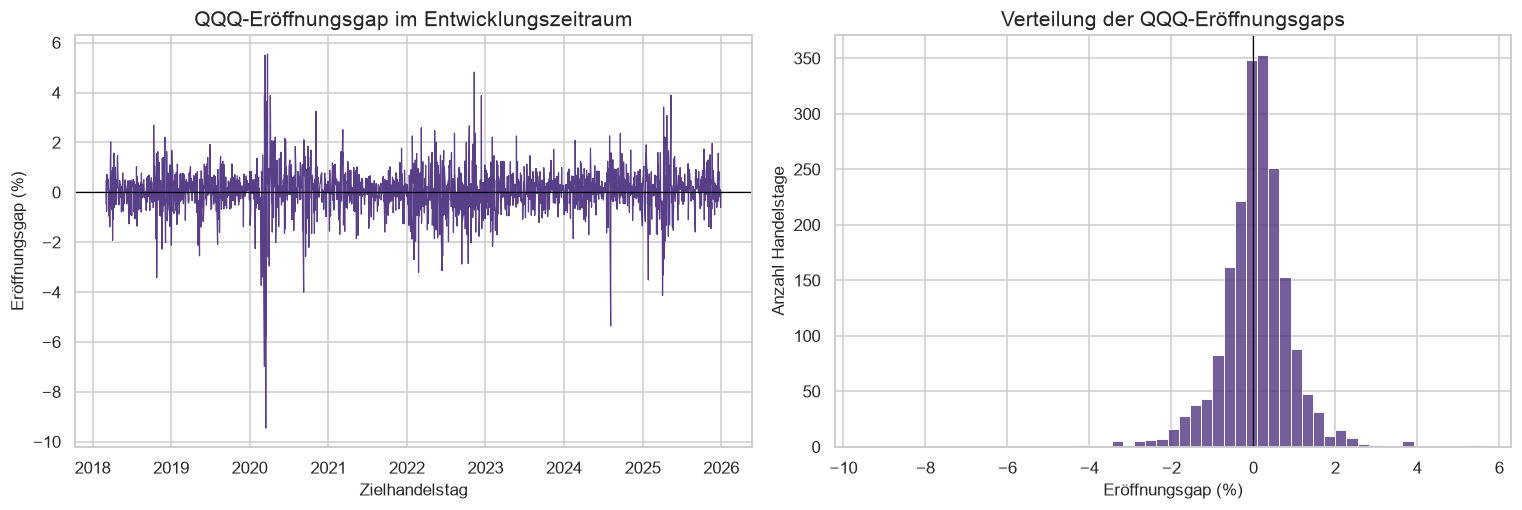

In [11]:
# Restrict every exploratory result to the development period
development_data = modeling_data[
    modeling_data["target_session_date"] < HOLDOUT_START
].copy()
assert development_data["target_session_date"].max() < HOLDOUT_START

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

axes[0].plot(
    development_data["target_session_date"],
    development_data["qqq_gap_percent"],
    color=COLORS["qqq"],
    linewidth=0.8,
    alpha=0.9,
)
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_title("QQQ-Eröffnungsgap im Entwicklungszeitraum")
axes[0].set_xlabel("Zielhandelstag")
axes[0].set_ylabel("Eröffnungsgap (%)")

sns.histplot(
    data=development_data,
    x="qqq_gap_percent",
    bins=55,
    color=COLORS["qqq"],
    ax=axes[1],
)
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_title("Verteilung der QQQ-Eröffnungsgaps")
axes[1].set_xlabel("Eröffnungsgap (%)")
axes[1].set_ylabel("Anzahl Handelstage")

fig.tight_layout()
plt.show()

In [12]:
# Quantify target location, tails and class balance
mean_gap = development_data["qqq_gap_percent"].mean()
median_gap = development_data["qqq_gap_percent"].median()
positive_share = development_data[CLASSIFICATION_TARGET].mean()
absolute_gap_95 = development_data["qqq_gap_percent"].abs().quantile(0.95)

display(
    Markdown(
        f'''
### Interpretation

Der mittlere QQQ-Eröffnungsgap beträgt **{mean_gap:.3f}%**, der Median
**{median_gap:.3f}%**. In **{positive_share:.1%}** der
Entwicklungsbeobachtungen eröffnet QQQ höher als am vorherigen
Schluss. 95% der absoluten Gaps liegen unter **{absolute_gap_95:.2f}%**.
Einzelne starke Ausschläge und die Klassenverteilung müssen bei der
späteren Bewertung berücksichtigt werden; Accuracy wird deshalb gegen
eine historische Mehrheitsbaseline und zusätzlich mit Balanced
Accuracy beurteilt.
        '''
    )
)


### Interpretation

Der mittlere QQQ-Eröffnungsgap beträgt **0.049%**, der Median
**0.089%**. In **56.5%** der
Entwicklungsbeobachtungen eröffnet QQQ höher als am vorherigen
Schluss. 95% der absoluten Gaps liegen unter **1.77%**.
Einzelne starke Ausschläge und die Klassenverteilung müssen bei der
späteren Bewertung berücksichtigt werden; Accuracy wird deshalb gegen
eine historische Mehrheitsbaseline und zusätzlich mit Balanced
Accuracy beurteilt.
        

### 7.1 Richtung und Fensterlänge nach Wochentag

Wir prüfen, ob die positive Gap-Rate und die Dauer des
Informationsfensters systematisch mit dem Ziel-Wochentag variieren.
Montage enthalten in der Regel das gesamte Wochenende; Feiertage und
verkürzte Sitzungen können zusätzliche längere Fenster erzeugen.

,Beobachtungen,Positive_Rate,Median_Fensterstunden,Max_Fensterstunden
target_weekday,,,,
Montag,362,0.561,65.0,92.0
Dienstag,403,0.561,17.0,89.0
Mittwoch,396,0.596,17.0,44.0
Donnerstag,392,0.561,17.0,44.0
Freitag,392,0.546,17.0,44.0


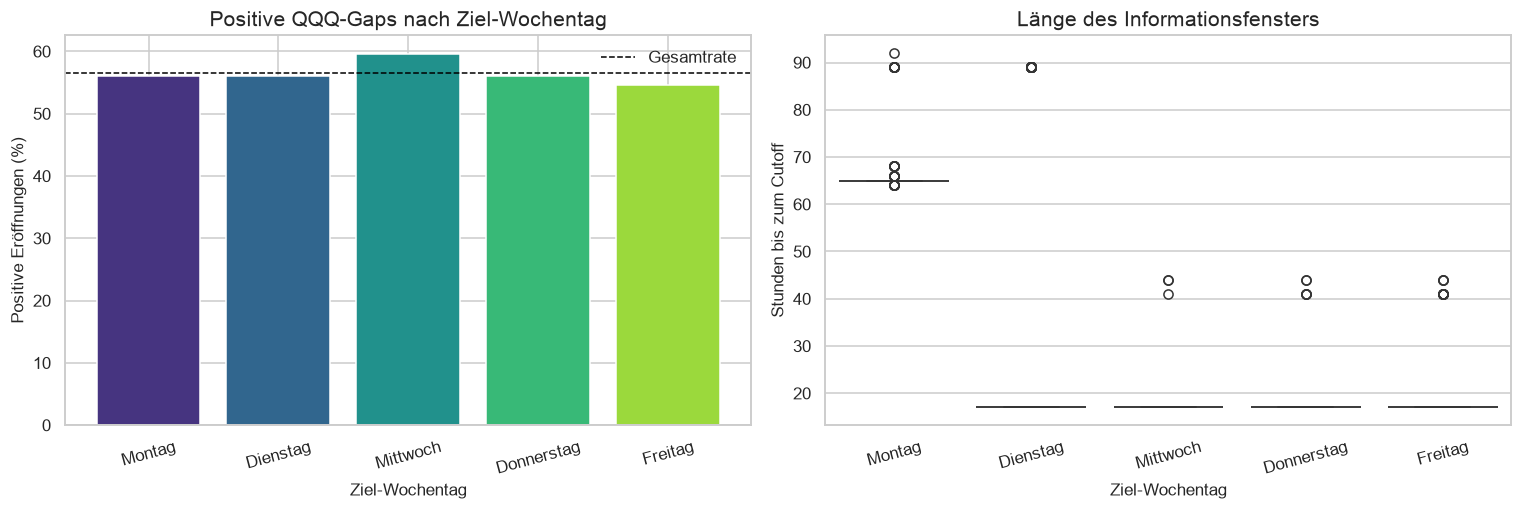

In [13]:
weekday_order = ["Montag", "Dienstag", "Mittwoch", "Donnerstag", "Freitag"]
weekday_summary = (
    development_data.groupby("target_weekday", observed=False)
    .agg(
        Beobachtungen=(CLASSIFICATION_TARGET, "size"),
        Positive_Rate=(CLASSIFICATION_TARGET, "mean"),
        Median_Fensterstunden=("overnight_hours", "median"),
        Max_Fensterstunden=("overnight_hours", "max"),
    )
    .reindex(weekday_order)
)
display(weekday_summary.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
viridis_weekdays = [VIRIDIS(value) for value in np.linspace(0.15, 0.85, 5)]

axes[0].bar(
    weekday_summary.index,
    100 * weekday_summary["Positive_Rate"],
    color=viridis_weekdays,
)
axes[0].axhline(
    100 * positive_share,
    color="black",
    linewidth=1,
    linestyle="--",
    label="Gesamtrate",
)
axes[0].set_title("Positive QQQ-Gaps nach Ziel-Wochentag")
axes[0].set_xlabel("Ziel-Wochentag")
axes[0].set_ylabel("Positive Eröffnungen (%)")
axes[0].legend()

sns.boxplot(
    data=development_data,
    x="target_weekday",
    y="overnight_hours",
    order=weekday_order,
    hue="target_weekday",
    palette="viridis",
    legend=False,
    ax=axes[1],
)
axes[1].set_title("Länge des Informationsfensters")
axes[1].set_xlabel("Ziel-Wochentag")
axes[1].set_ylabel("Stunden bis zum Cutoff")

for axis in axes:
    axis.tick_params(axis="x", rotation=15)

fig.tight_layout()
plt.show()

In [14]:
# Describe observed weekday differences without causal interpretation
highest_weekday = weekday_summary["Positive_Rate"].idxmax()
lowest_weekday = weekday_summary["Positive_Rate"].idxmin()
monday_median_hours = weekday_summary.loc["Montag", "Median_Fensterstunden"]
weekday_median_hours = weekday_summary.loc[
    ["Dienstag", "Mittwoch", "Donnerstag", "Freitag"],
    "Median_Fensterstunden",
].median()

display(
    Markdown(
        f'''
### Interpretation

Die höchste positive Gap-Rate zeigt **{highest_weekday}**, die tiefste
**{lowest_weekday}**. Das mediane Montagsfenster umfasst
**{monday_median_hours:.0f} Stunden**, gegenüber
**{weekday_median_hours:.0f} Stunden** an den übrigen Handelstagen.
Diese Kalenderunterschiede rechtfertigen den Montag-Indikator und die
Fensterlänge im Kontrollmodell. Sie sind keine Evidenz für einen
Bitcoin-Effekt.
        '''
    )
)


### Interpretation

Die höchste positive Gap-Rate zeigt **Mittwoch**, die tiefste
**Freitag**. Das mediane Montagsfenster umfasst
**65 Stunden**, gegenüber
**17 Stunden** an den übrigen Handelstagen.
Diese Kalenderunterschiede rechtfertigen den Montag-Indikator und die
Fensterlänge im Kontrollmodell. Sie sind keine Evidenz für einen
Bitcoin-Effekt.
        

### 7.2 BTC-Overnight-Return und QQQ-Gap

Der Scatterplot zeigt den direkten linearen Zusammenhang. Fear & Greed
dient als Farbdimension, um mögliche Sentimentregime sichtbar zu
machen. Danach vergleichen wir alle Tage, Montage und die übrigen
Handelstage getrennt.

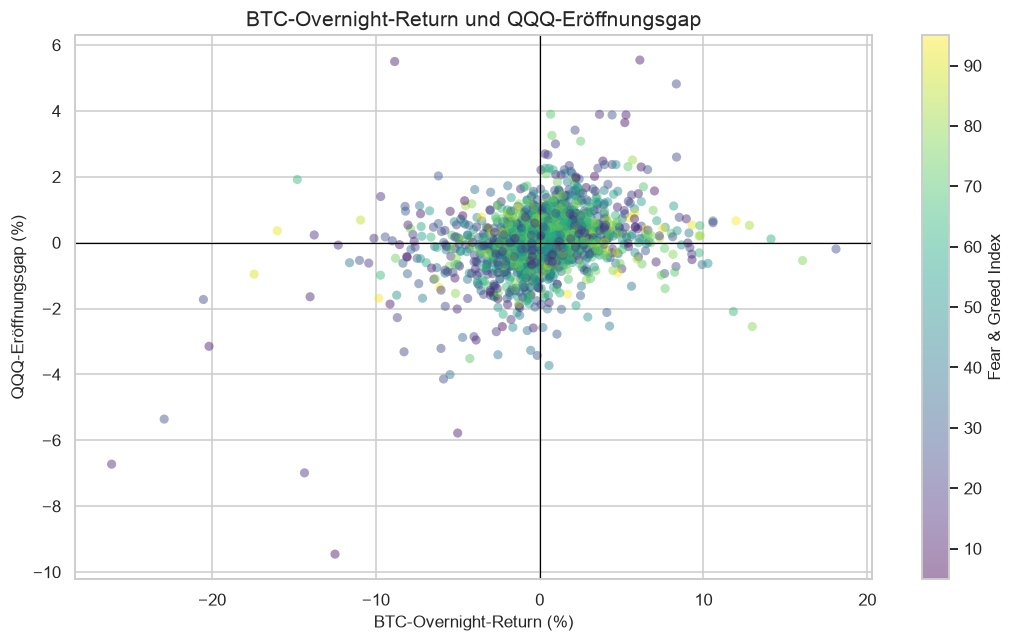

In [15]:
# Plot the direct relationship without fitting a predictive model
plt.figure(figsize=(10, 6))
scatter = plt.scatter(
    100 * development_data["btc_overnight_return"],
    development_data["qqq_gap_percent"],
    c=development_data["fear_greed"],
    cmap="viridis",
    alpha=0.45,
    edgecolor="none",
)
plt.axhline(0, color="black", linewidth=0.8)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("BTC-Overnight-Return und QQQ-Eröffnungsgap")
plt.xlabel("BTC-Overnight-Return (%)")
plt.ylabel("QQQ-Eröffnungsgap (%)")
colorbar = plt.colorbar(scatter)
colorbar.set_label("Fear & Greed Index")
plt.tight_layout()
plt.show()

In [16]:
# Compare correlations overall and by the main calendar regime
monday_data = development_data[development_data["target_is_monday"] == 1]
other_days_data = development_data[development_data["target_is_monday"] == 0]

def target_correlation(frame):
    # Return the linear BTC-return relationship for one subset
    return frame[["btc_overnight_return", NUMERIC_TARGET]].corr().iloc[0, 1]


correlation_by_period = pd.DataFrame(
    {
        "Teilmenge": ["Alle Handelstage", "Montage", "Dienstag bis Freitag"],
        "Beobachtungen": [
            len(development_data),
            len(monday_data),
            len(other_days_data),
        ],
        "Korrelation": [
            target_correlation(development_data),
            target_correlation(monday_data),
            target_correlation(other_days_data),
        ],
    }
)
display(correlation_by_period.round(3))

overall_correlation = correlation_by_period.loc[0, "Korrelation"]
monday_correlation = correlation_by_period.loc[1, "Korrelation"]
other_days_correlation = correlation_by_period.loc[2, "Korrelation"]

display(
    Markdown(
        f'''
### Interpretation

Im gesamten Entwicklungszeitraum beträgt die lineare Korrelation
zwischen BTC-Overnight-Return und numerischem QQQ-Gap
**{overall_correlation:.3f}**. Für Montage liegt sie bei
**{monday_correlation:.3f}**, für Dienstag bis Freitag bei
**{other_days_correlation:.3f}**. Die grössere Stichprobe erlaubt damit
eine getrennte Beschreibung längerer und normaler Fenster. Ob die
Beziehung gegenüber Kontrollmerkmalen stabilen Zusatznutzen besitzt,
muss die spätere Walk-forward-Validierung zeigen.
        '''
    )
)

,Teilmenge,Beobachtungen,Korrelation
0,Alle Handelstage,1945,0.316
1,Montage,362,0.345
2,Dienstag bis Freitag,1583,0.306



### Interpretation

Im gesamten Entwicklungszeitraum beträgt die lineare Korrelation
zwischen BTC-Overnight-Return und numerischem QQQ-Gap
**0.316**. Für Montage liegt sie bei
**0.345**, für Dienstag bis Freitag bei
**0.306**. Die grössere Stichprobe erlaubt damit
eine getrennte Beschreibung längerer und normaler Fenster. Ob die
Beziehung gegenüber Kontrollmerkmalen stabilen Zusatznutzen besitzt,
muss die spätere Walk-forward-Validierung zeigen.
        

### 7.3 Richtungsanteil nach BTC-Return-Quintil

Eine reine Korrelation kann nichtlineare oder schwellenartige
Beziehungen übersehen. Deshalb teilen wir die BTC-Overnight-Returns im
Entwicklungszeitraum in fünf gleich grosse Gruppen und berechnen je
Gruppe den Anteil positiver QQQ-Gaps. Die Quintile werden nur für diese
deskriptive EDA verwendet und nicht als nachträglich ausgewählte
Modellfeatures übernommen.

,Beobachtungen,BTC_Return_Median,Positive_QQQ_Rate,QQQ_Gap_Median
btc_return_quintile,,,,
Q1 tief,389,-0.0289,0.3728,-0.1816
Q2,389,-0.0085,0.4910,-0.0118
Q3,389,0.0012,0.6015,0.1125
Q4,389,0.0115,0.6530,0.1888
Q5 hoch,389,0.0338,0.7069,0.2995


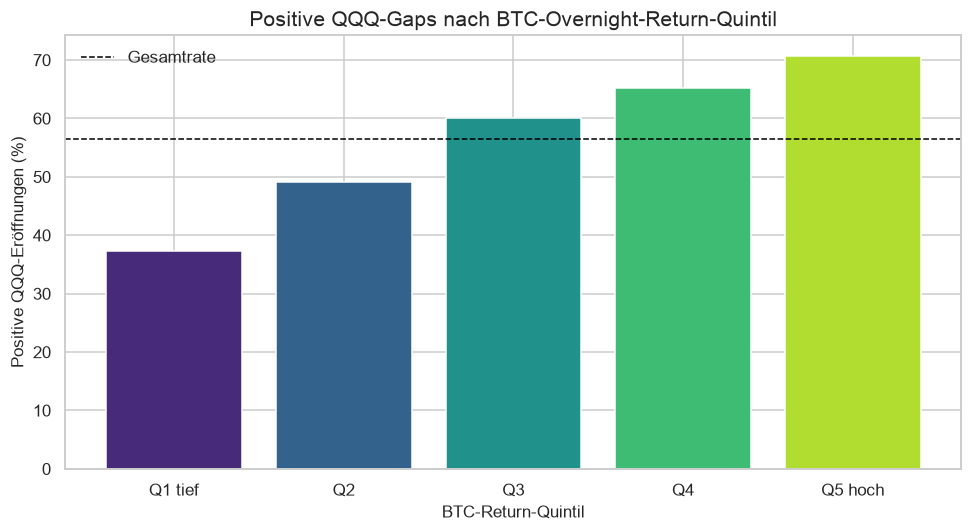

In [17]:
# Create equal-frequency bins for a descriptive monotonicity check
quintile_labels = ["Q1 tief", "Q2", "Q3", "Q4", "Q5 hoch"]
development_data["btc_return_quintile"] = pd.qcut(
    development_data["btc_overnight_return"],
    q=5,
    labels=quintile_labels,
)
quintile_summary = (
    development_data.groupby("btc_return_quintile", observed=False)
    .agg(
        Beobachtungen=(CLASSIFICATION_TARGET, "size"),
        BTC_Return_Median=("btc_overnight_return", "median"),
        Positive_QQQ_Rate=(CLASSIFICATION_TARGET, "mean"),
        QQQ_Gap_Median=("qqq_gap_percent", "median"),
    )
)
display(quintile_summary.round(4))

plt.figure(figsize=(9, 5))
plt.bar(
    quintile_summary.index.astype(str),
    100 * quintile_summary["Positive_QQQ_Rate"],
    color=[VIRIDIS(value) for value in np.linspace(0.12, 0.88, 5)],
)
plt.axhline(
    100 * positive_share,
    color="black",
    linewidth=1,
    linestyle="--",
    label="Gesamtrate",
)
plt.title("Positive QQQ-Gaps nach BTC-Overnight-Return-Quintil")
plt.xlabel("BTC-Return-Quintil")
plt.ylabel("Positive QQQ-Eröffnungen (%)")
plt.legend()
plt.tight_layout()
plt.show()

In [18]:
# Summarize the observed range without selecting a threshold
lowest_quintile_rate = quintile_summary["Positive_QQQ_Rate"].iloc[0]
highest_quintile_rate = quintile_summary["Positive_QQQ_Rate"].iloc[-1]
quintile_rate_difference = highest_quintile_rate - lowest_quintile_rate
quintile_rates_are_ordered = quintile_summary[
    "Positive_QQQ_Rate"
].is_monotonic_increasing
quintile_pattern_text = (
    "Die positive QQQ-Rate steigt über alle fünf Quintile geordnet an."
    if quintile_rates_are_ordered
    else "Die positive QQQ-Rate verläuft über die fünf Quintile nicht geordnet."
)

display(
    Markdown(
        f'''
### Interpretation

Im tiefsten BTC-Return-Quintil sind **{lowest_quintile_rate:.1%}** der
QQQ-Gaps positiv, im höchsten Quintil **{highest_quintile_rate:.1%}**.
Die Differenz beträgt **{quintile_rate_difference:.1%}**.
{quintile_pattern_text} Das ist ein klarer deskriptiver Hinweis zugunsten
unserer Hypothese, bleibt aber eine In-Sample-Beschreibung und kein
Beleg für Out-of-sample-Prognosekraft. Die Quintile werden nicht als
nachträglich optimierte Schwellenwerte in die Modelle übernommen.
        '''
    )
)


### Interpretation

Im tiefsten BTC-Return-Quintil sind **37.3%** der
QQQ-Gaps positiv, im höchsten Quintil **70.7%**.
Die Differenz beträgt **33.4%**.
Die positive QQQ-Rate steigt über alle fünf Quintile geordnet an. Das ist ein klarer deskriptiver Hinweis zugunsten
unserer Hypothese, bleibt aber eine In-Sample-Beschreibung und kein
Beleg für Out-of-sample-Prognosekraft. Die Quintile werden nicht als
nachträglich optimierte Schwellenwerte in die Modelle übernommen.
        

### 7.4 Kompakte Korrelationsübersicht

Die Heatmap vergleicht den numerischen Gap mit einer kleinen, vorab
definierten Auswahl von Bitcoin-, Sentiment-, Makro- und
QQQ-Merkmalen. Sie dient der Plausibilitätsprüfung, nicht der
automatischen Feature-Auswahl.

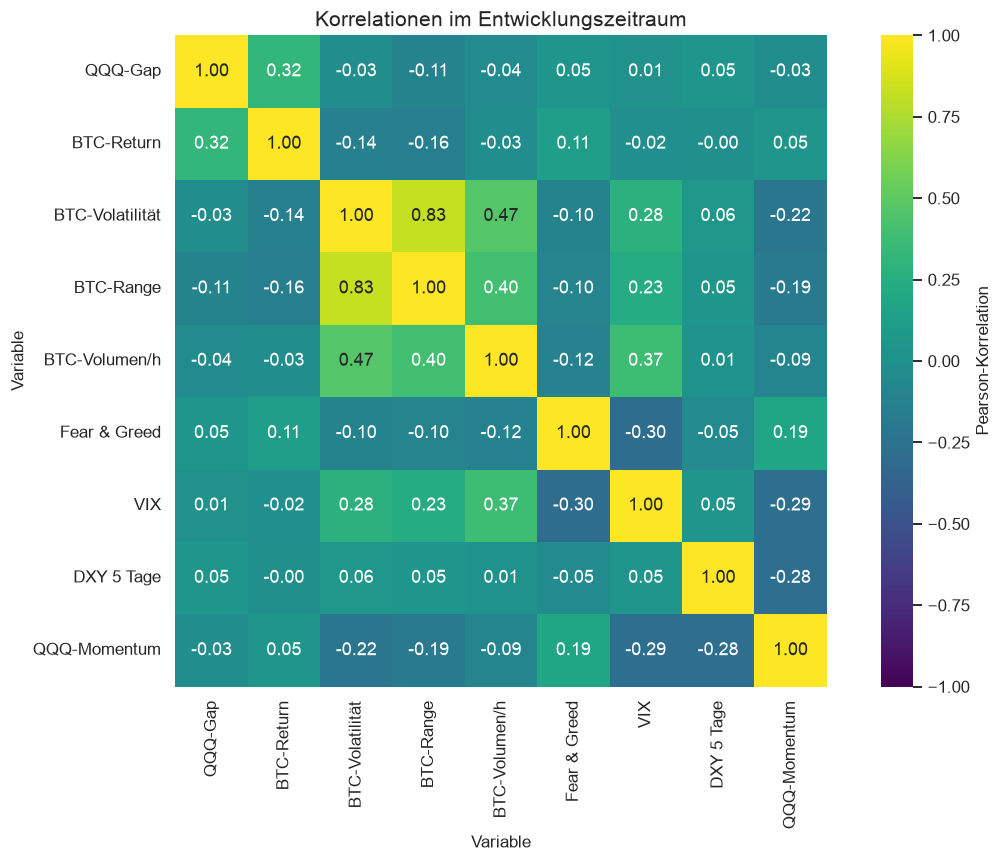

In [19]:
# Keep the heatmap focused on the research question
correlation_columns = [
    NUMERIC_TARGET,
    "btc_overnight_return",
    "btc_overnight_rv_intensity",
    "btc_overnight_range",
    "btc_overnight_log_volume_per_hour",
    "fear_greed",
    "vix_close",
    "dxy_change_5d",
    "qqq_momentum_5d",
]
correlation_labels = {
    NUMERIC_TARGET: "QQQ-Gap",
    "btc_overnight_return": "BTC-Return",
    "btc_overnight_rv_intensity": "BTC-Volatilität",
    "btc_overnight_range": "BTC-Range",
    "btc_overnight_log_volume_per_hour": "BTC-Volumen/h",
    "fear_greed": "Fear & Greed",
    "vix_close": "VIX",
    "dxy_change_5d": "DXY 5 Tage",
    "qqq_momentum_5d": "QQQ-Momentum",
}
correlation_matrix = development_data[correlation_columns].corr().rename(
    index=correlation_labels, columns=correlation_labels
)

plt.figure(figsize=(11, 8))
sns.heatmap(
    correlation_matrix,
    cmap="viridis",
    vmin=-1,
    vmax=1,
    center=0,
    annot=True,
    fmt=".2f",
    square=True,
    cbar_kws={"label": "Pearson-Korrelation"},
)
plt.title("Korrelationen im Entwicklungszeitraum")
plt.xlabel("Variable")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()

In [20]:
# Rank target correlations for a concise evidence-based interpretation
target_correlations = (
    development_data[correlation_columns]
    .corr()[NUMERIC_TARGET]
    .drop(NUMERIC_TARGET)
    .sort_values(key=lambda values: values.abs(), ascending=False)
)
strongest_feature = target_correlations.index[0]
strongest_value = target_correlations.iloc[0]

display(target_correlations.rename("Korrelation mit QQQ-Gap").round(3).to_frame())
display(
    Markdown(
        f'''
### Interpretation

Die stärkste absolute lineare Zielkorrelation in dieser bewusst kleinen
Auswahl besitzt **`{strongest_feature}`** mit
**{strongest_value:.3f}**. Die Grössenordnung ist eine
In-Sample-Beschreibung. Stark korrelierte Features können redundant
sein; schwach korrelierte Features können in nichtlinearen Modellen
gemeinsam nützlich werden. Deshalb bleiben die Feature-Sets wie vorab
definiert bestehen.
        '''
    )
)

,Korrelation mit QQQ-Gap
btc_overnight_return,0.316
btc_overnight_range,-0.108
dxy_change_5d,0.052
fear_greed,0.051
btc_overnight_log_volume_per_hour,-0.041
qqq_momentum_5d,-0.029
btc_overnight_rv_intensity,-0.029
vix_close,0.008



### Interpretation

Die stärkste absolute lineare Zielkorrelation in dieser bewusst kleinen
Auswahl besitzt **`btc_overnight_return`** mit
**0.316**. Die Grössenordnung ist eine
In-Sample-Beschreibung. Stark korrelierte Features können redundant
sein; schwach korrelierte Features können in nichtlinearen Modellen
gemeinsam nützlich werden. Deshalb bleiben die Feature-Sets wie vorab
definiert bestehen.
        

## 8. Expanding-window-Validierung und Mehrheitsbaseline

### 8.1 Jährliche Expanding-window-Folds

### Erklärung

Ein zufälliger Split würde zukünftige Marktregime in das Training
mischen. Wir verwenden deshalb fünf chronologische Folds. Für das
Validierungsjahr (v) besteht das Training aus allen Beobachtungen vor
dem 1. Januar von (v):

$$
\mathcal{T}_v = \{(x_t,y_t): date_t < 1.\ Januar\ v\},
\qquad
\mathcal{V}_v = \{(x_t,y_t): year(date_t)=v\}.
$$

Innerhalb eines Validierungsjahres darf eine Walk-forward-Methode nach
jedem beobachteten Zieltag auch diese neue Vergangenheit verwenden. Der
Holdout ab 2026 bleibt vollständig ausserhalb aller Folds.

In [21]:
# Define annual folds using development data only
fold_rows = []
for validation_year in VALIDATION_YEARS:
    validation_start = pd.Timestamp(f"{validation_year}-01-01")
    validation_end = pd.Timestamp(f"{validation_year + 1}-01-01")
    training_fold = development_data[
        development_data["target_session_date"] < validation_start
    ]
    validation_fold = development_data[
        (development_data["target_session_date"] >= validation_start)
        & (development_data["target_session_date"] < validation_end)
    ]

    # Enforce strict chronology and non-empty annual folds
    assert not training_fold.empty
    assert not validation_fold.empty
    assert (
        training_fold["target_session_date"].max()
        < validation_fold["target_session_date"].min()
    )
    assert validation_fold["target_session_date"].max() < HOLDOUT_START

    fold_rows.append(
        {
            "Validierungsjahr": validation_year,
            "Training von": training_fold["target_session_date"].min(),
            "Training bis": training_fold["target_session_date"].max(),
            "Training Beobachtungen": len(training_fold),
            "Training Positivrate": training_fold[
                CLASSIFICATION_TARGET
            ].mean(),
            "Validierung von": validation_fold[
                "target_session_date"
            ].min(),
            "Validierung bis": validation_fold[
                "target_session_date"
            ].max(),
            "Validierung Beobachtungen": len(validation_fold),
        }
    )

fold_summary = pd.DataFrame(fold_rows)
assert fold_summary["Validierung Beobachtungen"].sum() == 1248
display(fold_summary.round({"Training Positivrate": 3}))

,Validierungsjahr,Training von,Training bis,Training Beobachtungen,Training Positivrate,Validierung von,Validierung bis,Validierung Beobachtungen
0,2021,2018-03-05,2020-12-31,697,0.590,2021-01-04,2021-12-31,246
1,2022,2018-03-05,2021-12-31,943,0.587,2022-01-03,2022-12-30,251
2,2023,2018-03-05,2022-12-30,1194,0.559,2023-01-03,2023-12-29,249
3,2024,2018-03-05,2023-12-29,1443,0.554,2024-01-02,2024-12-31,252
4,2025,2018-03-05,2024-12-31,1695,0.560,2025-01-02,2025-12-31,250


In [22]:
# Summarize the executed fold boundaries
first_training_size = int(fold_summary.iloc[0]["Training Beobachtungen"])
last_training_size = int(fold_summary.iloc[-1]["Training Beobachtungen"])
validation_forecasts = int(
    fold_summary["Validierung Beobachtungen"].sum()
)

display(
    Markdown(
        f'''
### Interpretation

Der erste Fold trainiert auf **{first_training_size} Handelstagen** aus
2018 bis 2020 und validiert auf 2021. Bis zum letzten Fold wächst das
Starttraining auf **{last_training_size} Beobachtungen**. Insgesamt
enthalten die fünf Validierungsjahre **{validation_forecasts}
chronologische Prognosetermine**. Jede Trainingsperiode endet strikt
vor ihrer Validierung; Daten ab 2026 werden nicht verwendet.
        '''
    )
)


### Interpretation

Der erste Fold trainiert auf **697 Handelstagen** aus
2018 bis 2020 und validiert auf 2021. Bis zum letzten Fold wächst das
Starttraining auf **1695 Beobachtungen**. Insgesamt
enthalten die fünf Validierungsjahre **1248
chronologische Prognosetermine**. Jede Trainingsperiode endet strikt
vor ihrer Validierung; Daten ab 2026 werden nicht verwendet.
        

### 8.2 Historische Mehrheitsklasse

### Erklärung

Die naive Baseline verwendet keine Features. Vor jedem Prognosetag
(t) berechnen wir den Anteil positiver QQQ-Gaps in allen bereits
beobachteten Zielwerten:

$$
\hat p_t = \frac{1}{N_t}\sum_{i:date_i<date_t} Direction_i,
\qquad
\widehat{Direction}_t = \mathbb{1}(\hat p_t \ge 0.5).
$$

Bei einem exakten Gleichstand wählen wir die positive Klasse. Die
Baseline wird vor jedem Handelstag aktualisiert und ist damit strenger
als eine einmal auf dem gesamten Entwicklungszeitraum bestimmte
Mehrheitsklasse.

Wir berichten Accuracy und Balanced Accuracy:

$$
Balanced\ Accuracy = \frac{1}{2}(TPR + TNR).
$$

Balanced Accuracy zeigt, ob ein Modell beide Richtungen erkennt, statt
nur von der häufigeren Klasse zu profitieren.

In [23]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score

# Generate one strictly historical majority forecast per validation day
majority_rows = []
for validation_year in VALIDATION_YEARS:
    validation_fold = development_data[
        development_data["target_session_date"].dt.year
        == validation_year
    ]

    for observation in validation_fold.itertuples(index=False):
        training_history = development_data[
            development_data["target_session_date"]
            < observation.target_session_date
        ]
        historical_positive_rate = training_history[
            CLASSIFICATION_TARGET
        ].mean()

        majority_rows.append(
            {
                "model": "Historische Mehrheitsklasse",
                "fold_year": validation_year,
                "forecast_date": observation.target_session_date,
                "train_start": training_history[
                    "target_session_date"
                ].min(),
                "train_end": training_history[
                    "target_session_date"
                ].max(),
                "train_size": len(training_history),
                "historical_positive_rate": historical_positive_rate,
                "prediction": int(historical_positive_rate >= 0.5),
                "actual": observation.qqq_gap_direction,
                "target_is_monday": observation.target_is_monday,
            }
        )

majority_predictions = pd.DataFrame(majority_rows).sort_values(
    "forecast_date"
).reset_index(drop=True)

# Validate the expanding handoff and protect the holdout
assert len(majority_predictions) == 1248
assert majority_predictions["forecast_date"].is_monotonic_increasing
assert majority_predictions["forecast_date"].is_unique
assert (
    majority_predictions["train_end"]
    < majority_predictions["forecast_date"]
).all()
assert (majority_predictions["forecast_date"] < HOLDOUT_START).all()
assert majority_predictions["prediction"].isin([0, 1]).all()
assert majority_predictions["actual"].isin([0, 1]).all()

# Save the transparent forecast-level audit trail
majority_output_path = (
    PROCESSED_DATA_DIR / "btc_overnight_qqq_majority_baseline.csv"
)
majority_predictions.to_csv(majority_output_path, index=False)

majority_head = majority_predictions.head(6).copy()
majority_tail = majority_predictions.tail(3).copy()
for preview in [majority_head, majority_tail]:
    numeric_columns = preview.select_dtypes(include="number").columns
    preview[numeric_columns] = preview[numeric_columns].round(3)
    display(preview)

,model,fold_year,forecast_date,train_start,train_end,train_size,historical_positive_rate,prediction,actual,target_is_monday
0,Historische Mehrheitsklasse,2021,2021-01-04,2018-03-05,2020-12-31,697,0.590,1,1,1
1,Historische Mehrheitsklasse,2021,2021-01-05,2018-03-05,2021-01-04,698,0.590,1,0,0
2,Historische Mehrheitsklasse,2021,2021-01-06,2018-03-05,2021-01-05,699,0.589,1,0,0
3,Historische Mehrheitsklasse,2021,2021-01-07,2018-03-05,2021-01-06,700,0.589,1,1,0
4,Historische Mehrheitsklasse,2021,2021-01-08,2018-03-05,2021-01-07,701,0.589,1,1,0
5,Historische Mehrheitsklasse,2021,2021-01-11,2018-03-05,2021-01-08,702,0.590,1,0,1


,model,fold_year,forecast_date,train_start,train_end,train_size,historical_positive_rate,prediction,actual,target_is_monday
1245,Historische Mehrheitsklasse,2025,2025-12-29,2018-03-05,2025-12-26,1942,0.565,1,0,1
1246,Historische Mehrheitsklasse,2025,2025-12-30,2018-03-05,2025-12-29,1943,0.565,1,0,0
1247,Historische Mehrheitsklasse,2025,2025-12-31,2018-03-05,2025-12-30,1944,0.565,1,1,0


,Beobachtungen,Positivrate Ziel,Positivrate Prognose,Accuracy,Balanced Accuracy
Alle Handelstage,1248.0,0.551,1.0,0.551,0.5
Montage,231.0,0.558,1.0,0.558,0.5
Dienstag bis Freitag,1017.0,0.550,1.0,0.550,0.5


,Validierungsjahr,Beobachtungen,Positivrate Ziel,Positivrate Prognose,Accuracy,Balanced Accuracy
0,2021,246.0,0.581,1.0,0.581,0.5
1,2022,251.0,0.454,1.0,0.454,0.5
2,2023,249.0,0.526,1.0,0.526,0.5
3,2024,252.0,0.599,1.0,0.599,0.5
4,2025,250.0,0.596,1.0,0.596,0.5


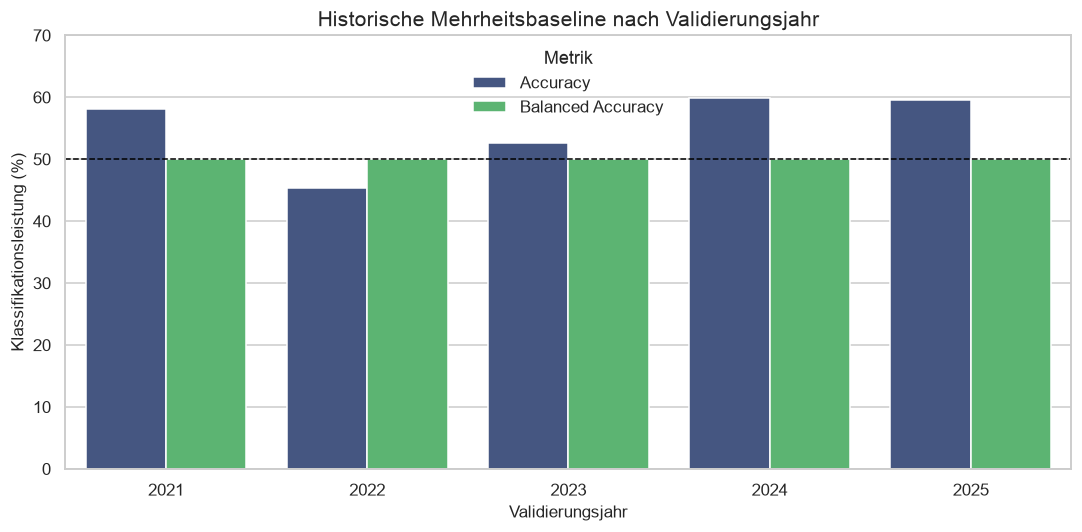

In [24]:
def summarize_classification(frame):
    # Calculate the two agreed classification metrics
    return pd.Series(
        {
            "Beobachtungen": len(frame),
            "Positivrate Ziel": frame["actual"].mean(),
            "Positivrate Prognose": frame["prediction"].mean(),
            "Accuracy": accuracy_score(
                frame["actual"], frame["prediction"]
            ),
            "Balanced Accuracy": balanced_accuracy_score(
                frame["actual"], frame["prediction"]
            ),
        }
    )


# Report overall and calendar-subgroup results
baseline_scope_metrics = pd.DataFrame(
    {
        "Alle Handelstage": summarize_classification(
            majority_predictions
        ),
        "Montage": summarize_classification(
            majority_predictions[
                majority_predictions["target_is_monday"] == 1
            ]
        ),
        "Dienstag bis Freitag": summarize_classification(
            majority_predictions[
                majority_predictions["target_is_monday"] == 0
            ]
        ),
    }
).T

baseline_year_metrics = (
    majority_predictions.groupby("fold_year", observed=False)
    .apply(summarize_classification, include_groups=False)
    .reset_index()
    .rename(columns={"fold_year": "Validierungsjahr"})
)

display(baseline_scope_metrics.round(3))
display(baseline_year_metrics.round(3))

# Visualize annual performance on a common percentage scale
plot_metrics = baseline_year_metrics.melt(
    id_vars="Validierungsjahr",
    value_vars=["Accuracy", "Balanced Accuracy"],
    var_name="Metrik",
    value_name="Wert",
)
plot_metrics["Wert (%)"] = 100 * plot_metrics["Wert"]

plt.figure(figsize=(10, 5))
sns.barplot(
    data=plot_metrics,
    x="Validierungsjahr",
    y="Wert (%)",
    hue="Metrik",
    palette=[VIRIDIS(0.25), VIRIDIS(0.72)],
)
plt.axhline(50, color="black", linewidth=1, linestyle="--")
plt.ylim(0, 70)
plt.title("Historische Mehrheitsbaseline nach Validierungsjahr")
plt.xlabel("Validierungsjahr")
plt.ylabel("Klassifikationsleistung (%)")
plt.legend(title="Metrik")
plt.tight_layout()
plt.show()

In [25]:
# Interpret the executed baseline without overstating skill
overall_accuracy = baseline_scope_metrics.loc[
    "Alle Handelstage", "Accuracy"
]
overall_balanced_accuracy = baseline_scope_metrics.loc[
    "Alle Handelstage", "Balanced Accuracy"
]
predicted_positive_count = int(majority_predictions["prediction"].sum())
best_year_row = baseline_year_metrics.loc[
    baseline_year_metrics["Accuracy"].idxmax()
]
worst_year_row = baseline_year_metrics.loc[
    baseline_year_metrics["Accuracy"].idxmin()
]

display(
    Markdown(
        f'''
### Interpretation

Die historische Positivrate bleibt an allen Prognoseterminen über 50%.
Deshalb sagt die Baseline für **{predicted_positive_count} von
{len(majority_predictions)} Terminen** eine positive Eröffnung voraus.
Ihre gesamte Accuracy beträgt **{overall_accuracy:.1%}**, die Balanced
Accuracy erwartungsgemäss **{overall_balanced_accuracy:.1%}**. Die
höhere Accuracy entsteht ausschliesslich aus der leicht häufigeren
positiven Klasse; die Baseline erkennt keine negativen Gaps.

Die jährliche Accuracy schwankt von
**{worst_year_row['Accuracy']:.1%} im Jahr
{int(worst_year_row['Validierungsjahr'])}** bis
**{best_year_row['Accuracy']:.1%} im Jahr
{int(best_year_row['Validierungsjahr'])}**. Diese Baseline ist damit die
Mindesthürde: Ein nützliches Richtungsmodell sollte nicht nur ihre
Accuracy übertreffen, sondern auch eine Balanced Accuracy klar über
50% erreichen.
        '''
    )
)


### Interpretation

Die historische Positivrate bleibt an allen Prognoseterminen über 50%.
Deshalb sagt die Baseline für **1248 von
1248 Terminen** eine positive Eröffnung voraus.
Ihre gesamte Accuracy beträgt **55.1%**, die Balanced
Accuracy erwartungsgemäss **50.0%**. Die
höhere Accuracy entsteht ausschliesslich aus der leicht häufigeren
positiven Klasse; die Baseline erkennt keine negativen Gaps.

Die jährliche Accuracy schwankt von
**45.4% im Jahr
2022** bis
**59.9% im Jahr
2024**. Diese Baseline ist damit die
Mindesthürde: Ein nützliches Richtungsmodell sollte nicht nur ihre
Accuracy übertreffen, sondern auch eine Balanced Accuracy klar über
50% erreichen.
        

## 9. Logistische Regression

### 9.1 Methode und Walk-forward-Training

### Erklärung

Die logistische Regression modelliert direkt die Wahrscheinlichkeit
eines positiven QQQ-Gaps. Für standardisierte Features (z_{t,j})
gilt:

$$
P(Direction_t=1\mid z_t)
= \sigma\left(\beta_0 + \sum_{j=1}^{p}\beta_j z_{t,j}\right),
\qquad
\sigma(a)=\frac{1}{1+e^{-a}}.
$$

Die Standardisierung wird vor jedem Prognosetag ausschliesslich auf der
damaligen Trainingshistorie geschätzt:

$$
z_{t,j}=\frac{x_{t,j}-\mu_{j,train}}{s_{j,train}}.
$$

Wir verwenden eine L2-Regularisierung mit festem (C=1). Weil die EDA
eine leichte Klassenverschiebung zeigt, berechnet
`class_weight="balanced"` in jedem Trainingsfenster Gewichte aus den
dort verfügbaren Zielwerten. Dadurch erhalten positive und negative
Beobachtungen im Fit dasselbe Gesamtgewicht.

Wir vergleichen zwei vorab definierte Varianten:

1. **Logistische Regression Kontrolle:** QQQ, Fear & Greed, VIX, DXY,
   Montag-Indikator und Fensterlänge.
2. **Logistische Regression + Bitcoin:** dieselben Variablen plus die
   fünf BTC-Overnight-Merkmale.

Beide Modelle werden vor jedem Validierungstag neu auf allen früheren
Beobachtungen geschätzt. Es gibt keine Hyperparametersuche und keinen
Zugriff auf den Holdout ab 2026.

In [26]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

LOGISTIC_MODEL_FEATURES = {
    "Logistische Regression Kontrolle": CONTROL_FEATURES,
    "Logistische Regression + Bitcoin": FULL_FEATURES,
}
LOGISTIC_PARAMETERS = {
    "C": 1.0,
    "solver": "lbfgs",
    "class_weight": "balanced",
    "max_iter": 2000,
    "random_state": RANDOM_SEED,
}

logistic_rows = []
for model_name, feature_columns in LOGISTIC_MODEL_FEATURES.items():
    for validation_year in VALIDATION_YEARS:
        validation_fold = development_data[
            development_data["target_session_date"].dt.year
            == validation_year
        ]

        for _, observation in validation_fold.iterrows():
            forecast_date = observation["target_session_date"]
            training_history = development_data[
                development_data["target_session_date"] < forecast_date
            ]

            # Fit scaling and classification only on historical rows
            classifier = make_pipeline(
                StandardScaler(),
                LogisticRegression(**LOGISTIC_PARAMETERS),
            )
            classifier.fit(
                training_history[feature_columns],
                training_history[CLASSIFICATION_TARGET],
            )

            forecast_features = (
                observation[feature_columns].to_frame().T.astype(float)
            )
            positive_probability = classifier.predict_proba(
                forecast_features
            )[0, 1]
            prediction = int(positive_probability >= 0.5)
            fitted_logistic = classifier.named_steps[
                "logisticregression"
            ]

            logistic_rows.append(
                {
                    "model": model_name,
                    "fold_year": validation_year,
                    "forecast_date": forecast_date,
                    "train_start": training_history[
                        "target_session_date"
                    ].min(),
                    "train_end": training_history[
                        "target_session_date"
                    ].max(),
                    "train_size": len(training_history),
                    "train_positive_rate": training_history[
                        CLASSIFICATION_TARGET
                    ].mean(),
                    "positive_probability": positive_probability,
                    "prediction": prediction,
                    "actual": observation[CLASSIFICATION_TARGET],
                    "target_is_monday": observation["target_is_monday"],
                    "iterations": int(fitted_logistic.n_iter_.max()),
                }
            )

logistic_predictions = pd.DataFrame(logistic_rows).sort_values(
    ["model", "forecast_date"]
).reset_index(drop=True)

# Validate identical dates, chronology and numerical convergence
expected_forecast_dates = majority_predictions["forecast_date"].tolist()
for model_name in LOGISTIC_MODEL_FEATURES:
    model_predictions = logistic_predictions[
        logistic_predictions["model"] == model_name
    ]
    assert len(model_predictions) == len(majority_predictions)
    assert model_predictions["forecast_date"].tolist() == expected_forecast_dates
    assert model_predictions["actual"].tolist() == majority_predictions[
        "actual"
    ].tolist()
    assert (
        model_predictions["train_end"]
        < model_predictions["forecast_date"]
    ).all()

assert (logistic_predictions["forecast_date"] < HOLDOUT_START).all()
assert logistic_predictions["positive_probability"].between(0, 1).all()
assert logistic_predictions["prediction"].isin([0, 1]).all()
assert logistic_predictions["iterations"].max() < LOGISTIC_PARAMETERS[
    "max_iter"
]

# Save one transparent forecast-level audit trail for both variants
logistic_output_path = (
    PROCESSED_DATA_DIR / "btc_overnight_qqq_logistic_backtest.csv"
)
logistic_predictions.to_csv(logistic_output_path, index=False)

logistic_preview = logistic_predictions.groupby(
    "model", observed=False, sort=False
).head(3).copy()
logistic_numeric = logistic_preview.select_dtypes(include="number").columns
logistic_preview[logistic_numeric] = logistic_preview[
    logistic_numeric
].round(3)
display(logistic_preview)

,model,fold_year,forecast_date,train_start,train_end,train_size,train_positive_rate,positive_probability,prediction,actual,target_is_monday,iterations
0,Logistische Regression + Bitcoin,2021,2021-01-04,2018-03-05,2020-12-31,697,0.590,0.270,0,1,1,21
1,Logistische Regression + Bitcoin,2021,2021-01-05,2018-03-05,2021-01-04,698,0.590,0.437,0,0,0,22
2,Logistische Regression + Bitcoin,2021,2021-01-06,2018-03-05,2021-01-05,699,0.589,0.652,1,0,0,21
1248,Logistische Regression Kontrolle,2021,2021-01-04,2018-03-05,2020-12-31,697,0.590,0.388,0,1,1,13
1249,Logistische Regression Kontrolle,2021,2021-01-05,2018-03-05,2021-01-04,698,0.590,0.506,1,0,0,13
1250,Logistische Regression Kontrolle,2021,2021-01-06,2018-03-05,2021-01-05,699,0.589,0.630,1,0,0,13


In [27]:
# Confirm the shared expanding-window handoff
logistic_handoff = (
    logistic_predictions.groupby("model", observed=False, sort=False)
    .agg(
        Prognosen=("forecast_date", "size"),
        Erste_Prognose=("forecast_date", "min"),
        Letzte_Prognose=("forecast_date", "max"),
        Erstes_Training=("train_size", "min"),
        Letztes_Training=("train_size", "max"),
        Max_Iterationen=("iterations", "max"),
    )
    .reset_index()
)
display(logistic_handoff)

maximum_iterations = int(logistic_predictions["iterations"].max())
display(
    Markdown(
        f'''
### Interpretation

Beide Varianten erzeugen dieselben **{len(majority_predictions)}
Prognosetermine** wie die Mehrheitsbaseline. Das Training wächst vor
jedem Handelstag um den neu bekannten Zielwert. Die Fits benötigen
höchstens **{maximum_iterations} Optimierungsschritte** und bleiben
damit deutlich unter dem Limit von
**{LOGISTIC_PARAMETERS['max_iter']}**; es gibt keinen Hinweis auf ein
Konvergenzproblem.
        '''
    )
)

,model,Prognosen,Erste_Prognose,Letzte_Prognose,Erstes_Training,Letztes_Training,Max_Iterationen
0,Logistische Regression + Bitcoin,1248,2021-01-04,2025-12-31,697,1944,23
1,Logistische Regression Kontrolle,1248,2021-01-04,2025-12-31,697,1944,15



### Interpretation

Beide Varianten erzeugen dieselben **1248
Prognosetermine** wie die Mehrheitsbaseline. Das Training wächst vor
jedem Handelstag um den neu bekannten Zielwert. Die Fits benötigen
höchstens **23 Optimierungsschritte** und bleiben
damit deutlich unter dem Limit von
**2000**; es gibt keinen Hinweis auf ein
Konvergenzproblem.
        

### 9.2 Ergebnisse und Bitcoin-Zusatznutzen

### Erklärung

Wir vergleichen die beiden logistischen Varianten und die
Mehrheitsbaseline auf identischen 1’248 Prognoseterminen. Neben dem
Gesamtergebnis zeigen wir die Montagsgruppe sowie jedes
Validierungsjahr. Entscheidend für die Forschungsfrage ist der direkte
Unterschied zwischen Kontrolle und `+ Bitcoin`.

In [28]:
# Combine baseline and logistic predictions on the shared dates
comparison_predictions = pd.concat(
    [
        majority_predictions[
            [
                "model",
                "fold_year",
                "forecast_date",
                "prediction",
                "actual",
                "target_is_monday",
            ]
        ],
        logistic_predictions[
            [
                "model",
                "fold_year",
                "forecast_date",
                "prediction",
                "actual",
                "target_is_monday",
            ]
        ],
    ],
    ignore_index=True,
)

model_order = [
    "Historische Mehrheitsklasse",
    "Logistische Regression Kontrolle",
    "Logistische Regression + Bitcoin",
]

overall_model_metrics = (
    comparison_predictions.groupby("model", observed=False, sort=False)
    .apply(summarize_classification, include_groups=False)
    .reindex(model_order)
    .reset_index()
)

logistic_year_metrics = (
    logistic_predictions.groupby(
        ["model", "fold_year"], observed=False, sort=False
    )
    .apply(summarize_classification, include_groups=False)
    .reset_index()
    .rename(columns={"fold_year": "Validierungsjahr"})
)

scope_rows = []
for model_name in model_order:
    model_predictions = comparison_predictions[
        comparison_predictions["model"] == model_name
    ]
    for scope_name, scope_frame in [
        ("Alle Handelstage", model_predictions),
        (
            "Montage",
            model_predictions[model_predictions["target_is_monday"] == 1],
        ),
        (
            "Dienstag bis Freitag",
            model_predictions[model_predictions["target_is_monday"] == 0],
        ),
    ]:
        metrics = summarize_classification(scope_frame).to_dict()
        scope_rows.append(
            {"Modell": model_name, "Teilmenge": scope_name, **metrics}
        )

model_scope_metrics = pd.DataFrame(scope_rows)

display(overall_model_metrics.round(3))
display(logistic_year_metrics.round(3))
display(model_scope_metrics.round(3))

,model,Beobachtungen,Positivrate Ziel,Positivrate Prognose,Accuracy,Balanced Accuracy
0,Historische Mehrheitsklasse,1248.0,0.551,1.000,0.551,0.500
1,Logistische Regression Kontrolle,1248.0,0.551,0.585,0.524,0.515
2,Logistische Regression + Bitcoin,1248.0,0.551,0.622,0.607,0.596


,model,Validierungsjahr,Beobachtungen,Positivrate Ziel,Positivrate Prognose,Accuracy,Balanced Accuracy
0,Logistische Regression + Bitcoin,2021,246.0,0.581,0.646,0.553,0.530
1,Logistische Regression + Bitcoin,2022,251.0,0.454,0.430,0.633,0.628
2,Logistische Regression + Bitcoin,2023,249.0,0.526,0.558,0.534,0.531
3,Logistische Regression + Bitcoin,2024,252.0,0.599,0.706,0.631,0.594
4,Logistische Regression + Bitcoin,2025,250.0,0.596,0.768,0.684,0.638
5,Logistische Regression Kontrolle,2021,246.0,0.581,0.671,0.488,0.459
6,Logistische Regression Kontrolle,2022,251.0,0.454,0.458,0.526,0.522
7,Logistische Regression Kontrolle,2023,249.0,0.526,0.622,0.502,0.496
8,Logistische Regression Kontrolle,2024,252.0,0.599,0.611,0.504,0.481
9,Logistische Regression Kontrolle,2025,250.0,0.596,0.564,0.600,0.591


,Modell,Teilmenge,Beobachtungen,Positivrate Ziel,Positivrate Prognose,Accuracy,Balanced Accuracy
0,Historische Mehrheitsklasse,Alle Handelstage,1248.0,0.551,1.000,0.551,0.500
1,Historische Mehrheitsklasse,Montage,231.0,0.558,1.000,0.558,0.500
2,Historische Mehrheitsklasse,Dienstag bis Freitag,1017.0,0.550,1.000,0.550,0.500
3,Logistische Regression Kontrolle,Alle Handelstage,1248.0,0.551,0.585,0.524,0.515
4,Logistische Regression Kontrolle,Montage,231.0,0.558,0.429,0.437,0.445
5,Logistische Regression Kontrolle,Dienstag bis Freitag,1017.0,0.550,0.620,0.544,0.532
6,Logistische Regression + Bitcoin,Alle Handelstage,1248.0,0.551,0.622,0.607,0.596
7,Logistische Regression + Bitcoin,Montage,231.0,0.558,0.550,0.610,0.606
8,Logistische Regression + Bitcoin,Dienstag bis Freitag,1017.0,0.550,0.638,0.607,0.594


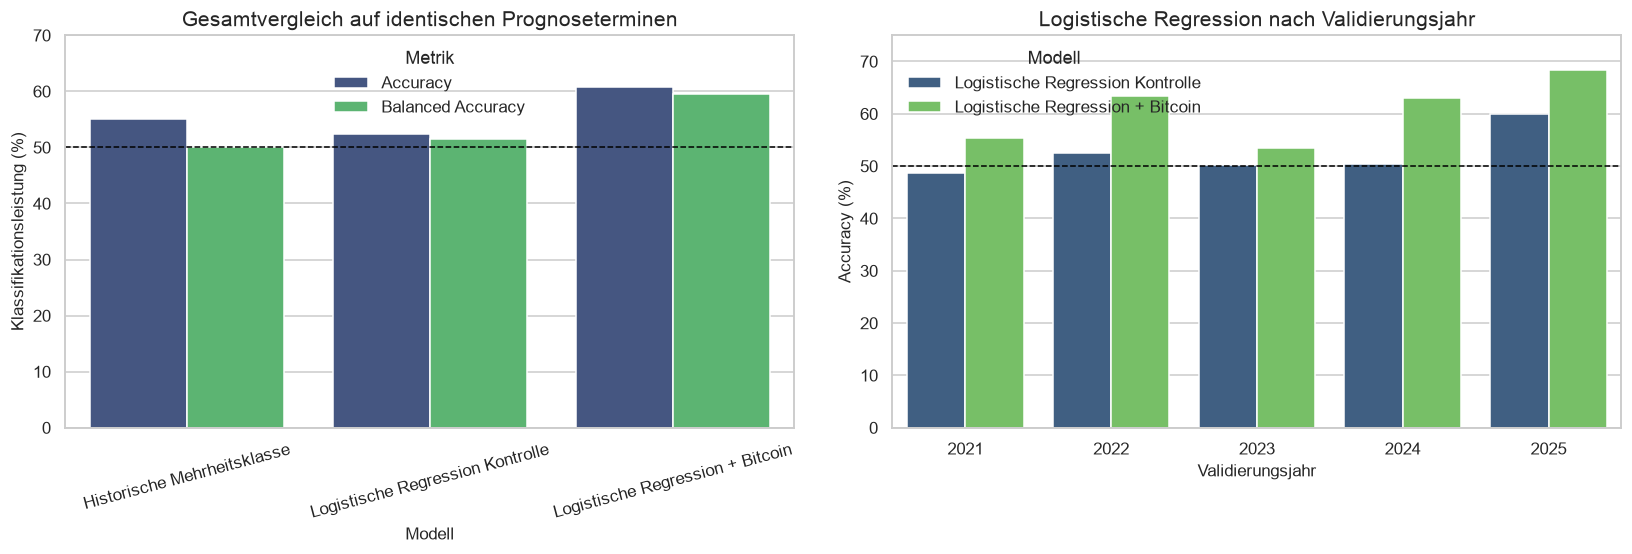

In [29]:
# Plot overall and annual metrics on a shared percentage scale
overall_plot = overall_model_metrics.melt(
    id_vars="model",
    value_vars=["Accuracy", "Balanced Accuracy"],
    var_name="Metrik",
    value_name="Wert",
)
overall_plot["Wert (%)"] = 100 * overall_plot["Wert"]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
sns.barplot(
    data=overall_plot,
    x="model",
    y="Wert (%)",
    hue="Metrik",
    order=model_order,
    palette=[VIRIDIS(0.25), VIRIDIS(0.72)],
    ax=axes[0],
)
axes[0].axhline(50, color="black", linewidth=1, linestyle="--")
axes[0].set_ylim(0, 70)
axes[0].set_title("Gesamtvergleich auf identischen Prognoseterminen")
axes[0].set_xlabel("Modell")
axes[0].set_ylabel("Klassifikationsleistung (%)")
axes[0].tick_params(axis="x", rotation=15)
axes[0].legend(title="Metrik")

yearly_plot = logistic_year_metrics.copy()
yearly_plot["Accuracy (%)"] = 100 * yearly_plot["Accuracy"]
sns.barplot(
    data=yearly_plot,
    x="Validierungsjahr",
    y="Accuracy (%)",
    hue="model",
    hue_order=[
        "Logistische Regression Kontrolle",
        "Logistische Regression + Bitcoin",
    ],
    palette=[VIRIDIS(0.30), VIRIDIS(0.78)],
    ax=axes[1],
)
axes[1].axhline(50, color="black", linewidth=1, linestyle="--")
axes[1].set_ylim(0, 75)
axes[1].set_title("Logistische Regression nach Validierungsjahr")
axes[1].set_xlabel("Validierungsjahr")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend(title="Modell")

fig.tight_layout()
plt.show()

In [30]:
# Derive the written comparison only from executed predictions
overall_by_model = overall_model_metrics.set_index("model")
control_accuracy = overall_by_model.loc[
    "Logistische Regression Kontrolle", "Accuracy"
]
bitcoin_accuracy = overall_by_model.loc[
    "Logistische Regression + Bitcoin", "Accuracy"
]
control_balanced = overall_by_model.loc[
    "Logistische Regression Kontrolle", "Balanced Accuracy"
]
bitcoin_balanced = overall_by_model.loc[
    "Logistische Regression + Bitcoin", "Balanced Accuracy"
]
bitcoin_predicted_positive_rate = overall_by_model.loc[
    "Logistische Regression + Bitcoin", "Positivrate Prognose"
]
scope_by_model = model_scope_metrics.set_index(["Modell", "Teilmenge"])
monday_control_accuracy = scope_by_model.loc[
    ("Logistische Regression Kontrolle", "Montage"), "Accuracy"
]
monday_bitcoin_accuracy = scope_by_model.loc[
    ("Logistische Regression + Bitcoin", "Montage"), "Accuracy"
]
monday_bitcoin_balanced = scope_by_model.loc[
    ("Logistische Regression + Bitcoin", "Montage"),
    "Balanced Accuracy",
]

yearly_pivot = logistic_year_metrics.pivot(
    index="Validierungsjahr", columns="model", values="Accuracy"
)
bitcoin_year_wins = int(
    (
        yearly_pivot["Logistische Regression + Bitcoin"]
        > yearly_pivot["Logistische Regression Kontrolle"]
    ).sum()
)

display(
    Markdown(
        f'''
### Interpretation

Die Kontrollvariante erreicht **{control_accuracy:.1%} Accuracy** und
**{control_balanced:.1%} Balanced Accuracy**. Mit den fünf
Bitcoin-Merkmalen steigen die Werte auf **{bitcoin_accuracy:.1%}** und
**{bitcoin_balanced:.1%}**. Der direkte Zusatz beträgt damit
**{bitcoin_accuracy - control_accuracy:.1%}-Punkte bei Accuracy** und
**{bitcoin_balanced - control_balanced:.1%}-Punkte bei Balanced
Accuracy**.

Die Bitcoin-Variante prognostiziert in
**{bitcoin_predicted_positive_rate:.1%}** der Fälle positiv und erkennt
somit beide Klassen. Sie übertrifft die Kontrollvariante in
**{bitcoin_year_wins} von {len(VALIDATION_YEARS)} Validierungsjahren**
bei der Accuracy. Das ist ein konsistenter Out-of-sample-Hinweis auf
zusätzlichen Informationsgehalt der BTC-Overnight-Merkmale innerhalb
der logistischen Regression.

An den **{int((majority_predictions['target_is_monday'] == 1).sum())}
Montagen** steigt die Accuracy von
**{monday_control_accuracy:.1%} ohne Bitcoin** auf
**{monday_bitcoin_accuracy:.1%} mit Bitcoin**; die Bitcoin-Variante
erreicht dort **{monday_bitcoin_balanced:.1%} Balanced Accuracy**. Die
längeren Wochenendfenster widersprechen dem Gesamtergebnis somit nicht.
Es ist dennoch kein finaler Beweis: Die Modellparameter sind bewusst
einfach, weitere Modellklassen fehlen, und der Holdout 2026 bleibt
unangetastet.
        '''
    )
)


### Interpretation

Die Kontrollvariante erreicht **52.4% Accuracy** und
**51.5% Balanced Accuracy**. Mit den fünf
Bitcoin-Merkmalen steigen die Werte auf **60.7%** und
**59.6%**. Der direkte Zusatz beträgt damit
**8.3%-Punkte bei Accuracy** und
**8.0%-Punkte bei Balanced
Accuracy**.

Die Bitcoin-Variante prognostiziert in
**62.2%** der Fälle positiv und erkennt
somit beide Klassen. Sie übertrifft die Kontrollvariante in
**5 von 5 Validierungsjahren**
bei der Accuracy. Das ist ein konsistenter Out-of-sample-Hinweis auf
zusätzlichen Informationsgehalt der BTC-Overnight-Merkmale innerhalb
der logistischen Regression.

An den **231
Montagen** steigt die Accuracy von
**43.7% ohne Bitcoin** auf
**61.0% mit Bitcoin**; die Bitcoin-Variante
erreicht dort **60.6% Balanced Accuracy**. Die
längeren Wochenendfenster widersprechen dem Gesamtergebnis somit nicht.
Es ist dennoch kein finaler Beweis: Die Modellparameter sind bewusst
einfach, weitere Modellklassen fehlen, und der Holdout 2026 bleibt
unangetastet.
        

## 10. XGBoost

### 10.1 Methode und Walk-forward-Training

### Erklärung

XGBoost kombiniert viele kleine Entscheidungsbäume schrittweise zu einem
nichtlinearen Klassifikationsmodell. In Iteration \(m\) wird ein neuer Baum
\(f_m\) ergänzt, der die bisherigen Fehler reduziert:

$$
\widehat{p}^{(m)}_t
= \sigma\!\left(\sum_{k=1}^{m} \eta f_k(x_t)\right),
\qquad
\sigma(a)=\frac{1}{1+e^{-a}}.
$$

Die Lernrate \(\eta\) begrenzt den Beitrag jedes neuen Baums. Unsere Bäume
bleiben mit Tiefe 2 bewusst flach. Subsampling, Spaltenauswahl und
Regularisierung reduzieren das Overfitting bei der begrenzten Datenmenge.

Analog zur logistischen Regression vergleichen wir:

1. **XGBoost Kontrolle:** QQQ, Fear & Greed, VIX, DXY,
   Montag-Indikator und Fensterlänge.
2. **XGBoost + Bitcoin:** dieselben Variablen plus die fünf
   BTC-Overnight-Merkmale.

Vor jedem Validierungstag wird das Modell auf allen früheren Beobachtungen neu
geschätzt. Das Verhältnis negativer zu positiver Trainingsbeobachtungen
bestimmt dabei `scale_pos_weight` ausschließlich aus der jeweiligen Historie:

$$
w_{+,t}=\frac{N_{-,train,t}}{N_{+,train,t}}.
$$

Wir verwenden feste konservative Parameter und keine Hyperparametersuche.
XGBoost nutzt auf Apple Silicon die optimierte CPU-Implementierung
`tree_method="hist"`; MPS wird von XGBoost nicht benötigt. Der Holdout ab
2026 wird in diesem Entwicklungsabschnitt nicht verwendet.

In [31]:
from xgboost import XGBClassifier

XGBOOST_MODEL_FEATURES = {
    "XGBoost Kontrolle": CONTROL_FEATURES,
    "XGBoost + Bitcoin": FULL_FEATURES,
}
XGBOOST_PARAMETERS = {
    "n_estimators": 150,
    "max_depth": 2,
    "learning_rate": 0.04,
    "min_child_weight": 10,
    "subsample": 0.80,
    "colsample_bytree": 0.80,
    "reg_alpha": 0.10,
    "reg_lambda": 5.0,
    "gamma": 0.05,
    "objective": "binary:logistic",
    "eval_metric": "logloss",
    "tree_method": "hist",
    "n_jobs": -1,
    "random_state": RANDOM_SEED,
    "verbosity": 0,
}

xgboost_rows = []
for model_name, feature_columns in XGBOOST_MODEL_FEATURES.items():
    for validation_year in VALIDATION_YEARS:
        validation_fold = development_data[
            development_data["target_session_date"].dt.year
            == validation_year
        ]

        for _, observation in validation_fold.iterrows():
            forecast_date = observation["target_session_date"]
            training_history = development_data[
                development_data["target_session_date"] < forecast_date
            ]

            # Derive class weighting from the current historical window only
            positive_count = training_history[CLASSIFICATION_TARGET].sum()
            negative_count = len(training_history) - positive_count
            scale_pos_weight = negative_count / positive_count

            # Fit one deterministic model using only information known at t
            classifier = XGBClassifier(
                **XGBOOST_PARAMETERS,
                scale_pos_weight=scale_pos_weight,
            )
            classifier.fit(
                training_history[feature_columns],
                training_history[CLASSIFICATION_TARGET],
            )

            forecast_features = (
                observation[feature_columns].to_frame().T.astype(float)
            )
            positive_probability = classifier.predict_proba(
                forecast_features
            )[0, 1]
            prediction = int(positive_probability >= 0.5)

            xgboost_rows.append(
                {
                    "model": model_name,
                    "fold_year": validation_year,
                    "forecast_date": forecast_date,
                    "train_start": training_history[
                        "target_session_date"
                    ].min(),
                    "train_end": training_history[
                        "target_session_date"
                    ].max(),
                    "train_size": len(training_history),
                    "train_positive_rate": training_history[
                        CLASSIFICATION_TARGET
                    ].mean(),
                    "scale_pos_weight": scale_pos_weight,
                    "positive_probability": positive_probability,
                    "prediction": prediction,
                    "actual": observation[CLASSIFICATION_TARGET],
                    "target_is_monday": observation["target_is_monday"],
                }
            )

xgboost_predictions = pd.DataFrame(xgboost_rows).sort_values(
    ["model", "forecast_date"]
).reset_index(drop=True)

# Validate identical dates, labels, chronology and probability bounds
expected_forecast_dates = majority_predictions["forecast_date"].tolist()
for model_name in XGBOOST_MODEL_FEATURES:
    model_predictions = xgboost_predictions[
        xgboost_predictions["model"] == model_name
    ]
    assert len(model_predictions) == len(majority_predictions)
    assert model_predictions["forecast_date"].tolist() == expected_forecast_dates
    assert model_predictions["actual"].tolist() == majority_predictions[
        "actual"
    ].tolist()
    assert (
        model_predictions["train_end"]
        < model_predictions["forecast_date"]
    ).all()

assert (xgboost_predictions["forecast_date"] < HOLDOUT_START).all()
assert xgboost_predictions["positive_probability"].between(0, 1).all()
assert xgboost_predictions["prediction"].isin([0, 1]).all()
assert xgboost_predictions["scale_pos_weight"].gt(0).all()

# Save one forecast-level audit trail for both XGBoost variants
xgboost_output_path = (
    PROCESSED_DATA_DIR / "btc_overnight_qqq_xgboost_backtest.csv"
)
xgboost_predictions.to_csv(xgboost_output_path, index=False)

xgboost_preview = xgboost_predictions.groupby(
    "model", observed=False, sort=False
).head(3).copy()
xgboost_numeric = xgboost_preview.select_dtypes(include="number").columns
xgboost_preview[xgboost_numeric] = xgboost_preview[
    xgboost_numeric
].round(3)
display(xgboost_preview)

,model,fold_year,forecast_date,train_start,train_end,train_size,train_positive_rate,scale_pos_weight,positive_probability,prediction,actual,target_is_monday
0,XGBoost + Bitcoin,2021,2021-01-04,2018-03-05,2020-12-31,697,0.590,0.696,0.559,1,1,1
1,XGBoost + Bitcoin,2021,2021-01-05,2018-03-05,2021-01-04,698,0.590,0.694,0.471,0,0,0
2,XGBoost + Bitcoin,2021,2021-01-06,2018-03-05,2021-01-05,699,0.589,0.697,0.534,1,0,0
1248,XGBoost Kontrolle,2021,2021-01-04,2018-03-05,2020-12-31,697,0.590,0.696,0.469,0,1,1
1249,XGBoost Kontrolle,2021,2021-01-05,2018-03-05,2021-01-04,698,0.590,0.694,0.419,0,0,0
1250,XGBoost Kontrolle,2021,2021-01-06,2018-03-05,2021-01-05,699,0.589,0.697,0.544,1,0,0


In [32]:
# Confirm the expanding training window and fixed configuration
xgboost_handoff = (
    xgboost_predictions.groupby("model", observed=False, sort=False)
    .agg(
        Prognosen=("forecast_date", "size"),
        Erste_Prognose=("forecast_date", "min"),
        Letzte_Prognose=("forecast_date", "max"),
        Erstes_Training=("train_size", "min"),
        Letztes_Training=("train_size", "max"),
        Min_Klassengewicht=("scale_pos_weight", "min"),
        Max_Klassengewicht=("scale_pos_weight", "max"),
    )
    .reset_index()
)

parameter_display = pd.DataFrame(
    {
        "Parameter": [
            "Bäume",
            "Maximale Tiefe",
            "Lernrate",
            "Zeilenanteil pro Baum",
            "Feature-Anteil pro Baum",
            "L1-Regularisierung",
            "L2-Regularisierung",
        ],
        "Wert": [
            XGBOOST_PARAMETERS["n_estimators"],
            XGBOOST_PARAMETERS["max_depth"],
            XGBOOST_PARAMETERS["learning_rate"],
            XGBOOST_PARAMETERS["subsample"],
            XGBOOST_PARAMETERS["colsample_bytree"],
            XGBOOST_PARAMETERS["reg_alpha"],
            XGBOOST_PARAMETERS["reg_lambda"],
        ],
    }
)

xgboost_handoff_display = xgboost_handoff.copy()
# Round only numeric columns and preserve the date columns unchanged
xgboost_handoff_numeric = xgboost_handoff_display.select_dtypes(
    include="number"
).columns
xgboost_handoff_display[xgboost_handoff_numeric] = xgboost_handoff_display[
    xgboost_handoff_numeric
].round(3)
display(xgboost_handoff_display)
display(parameter_display)
display(
    Markdown(
        f'''
### Interpretation

Beide XGBoost-Varianten erzeugen dieselben
**{len(majority_predictions)} Prognosetermine** wie die bisherigen Modelle.
Das Training wächst von **{int(xgboost_handoff['Erstes_Training'].min())}**
auf **{int(xgboost_handoff['Letztes_Training'].max())} Beobachtungen**.
Das positive Klassengewicht wird für jeden Prognosetag neu aus der
Trainingshistorie berechnet; Validierungslabels und der Holdout beeinflussen
es nicht.
        '''
    )
)

,model,Prognosen,Erste_Prognose,Letzte_Prognose,Erstes_Training,Letztes_Training,Min_Klassengewicht,Max_Klassengewicht
0,XGBoost + Bitcoin,1248,2021-01-04,2025-12-31,697,1944,0.683,0.819
1,XGBoost Kontrolle,1248,2021-01-04,2025-12-31,697,1944,0.683,0.819


,Parameter,Wert
0,Bäume,150.00
1,Maximale Tiefe,2.00
2,Lernrate,0.04
3,Zeilenanteil pro Baum,0.80
4,Feature-Anteil pro Baum,0.80
5,L1-Regularisierung,0.10
6,L2-Regularisierung,5.00



### Interpretation

Beide XGBoost-Varianten erzeugen dieselben
**1248 Prognosetermine** wie die bisherigen Modelle.
Das Training wächst von **697**
auf **1944 Beobachtungen**.
Das positive Klassengewicht wird für jeden Prognosetag neu aus der
Trainingshistorie berechnet; Validierungslabels und der Holdout beeinflussen
es nicht.
        

### 10.2 Ergebnisse und Bitcoin-Zusatznutzen

### Erklärung

Wir bewerten XGBoost auf denselben Prognoseterminen und mit denselben Metriken
wie die Mehrheitsklasse und die logistische Regression. Entscheidend bleibt
zuerst der direkte Vergleich zwischen `XGBoost Kontrolle` und
`XGBoost + Bitcoin`. Erst danach vergleichen wir die Modellklassen.

Die Feature-Importance zeigt ergänzend, welche Variablen XGBoost beim Aufbau
der Bäume verwendet. Sie ist eine deskriptive Modellinterpretation und weder
ein Kausalitätsnachweis noch allein ein Beleg für Prognosewert.

In [33]:
# Combine all completed models on the identical validation dates
all_comparison_predictions = pd.concat(
    [
        comparison_predictions,
        xgboost_predictions[
            [
                "model",
                "fold_year",
                "forecast_date",
                "prediction",
                "actual",
                "target_is_monday",
            ]
        ],
    ],
    ignore_index=True,
)

all_model_order = [
    "Historische Mehrheitsklasse",
    "Logistische Regression Kontrolle",
    "Logistische Regression + Bitcoin",
    "XGBoost Kontrolle",
    "XGBoost + Bitcoin",
]

all_overall_metrics = (
    all_comparison_predictions.groupby("model", observed=False, sort=False)
    .apply(summarize_classification, include_groups=False)
    .reindex(all_model_order)
    .reset_index()
)

xgboost_year_metrics = (
    xgboost_predictions.groupby(
        ["model", "fold_year"], observed=False, sort=False
    )
    .apply(summarize_classification, include_groups=False)
    .reset_index()
    .rename(columns={"fold_year": "Validierungsjahr"})
)

xgboost_scope_rows = []
for model_name in XGBOOST_MODEL_FEATURES:
    model_predictions = xgboost_predictions[
        xgboost_predictions["model"] == model_name
    ]
    for scope_name, scope_frame in [
        ("Alle Handelstage", model_predictions),
        (
            "Montage",
            model_predictions[model_predictions["target_is_monday"] == 1],
        ),
        (
            "Dienstag bis Freitag",
            model_predictions[model_predictions["target_is_monday"] == 0],
        ),
    ]:
        metrics = summarize_classification(scope_frame).to_dict()
        xgboost_scope_rows.append(
            {"Modell": model_name, "Teilmenge": scope_name, **metrics}
        )

xgboost_scope_metrics = pd.DataFrame(xgboost_scope_rows)

display(all_overall_metrics.round(3))
display(xgboost_year_metrics.round(3))
display(xgboost_scope_metrics.round(3))

,model,Beobachtungen,Positivrate Ziel,Positivrate Prognose,Accuracy,Balanced Accuracy
0,Historische Mehrheitsklasse,1248.0,0.551,1.000,0.551,0.500
1,Logistische Regression Kontrolle,1248.0,0.551,0.585,0.524,0.515
2,Logistische Regression + Bitcoin,1248.0,0.551,0.622,0.607,0.596
3,XGBoost Kontrolle,1248.0,0.551,0.557,0.531,0.526
4,XGBoost + Bitcoin,1248.0,0.551,0.591,0.633,0.625


,model,Validierungsjahr,Beobachtungen,Positivrate Ziel,Positivrate Prognose,Accuracy,Balanced Accuracy
0,XGBoost + Bitcoin,2021,246.0,0.581,0.618,0.573,0.555
1,XGBoost + Bitcoin,2022,251.0,0.454,0.534,0.657,0.662
2,XGBoost + Bitcoin,2023,249.0,0.526,0.582,0.558,0.554
3,XGBoost + Bitcoin,2024,252.0,0.599,0.647,0.659,0.635
4,XGBoost + Bitcoin,2025,250.0,0.596,0.576,0.716,0.709
5,XGBoost Kontrolle,2021,246.0,0.581,0.593,0.533,0.518
6,XGBoost Kontrolle,2022,251.0,0.454,0.498,0.558,0.558
7,XGBoost Kontrolle,2023,249.0,0.526,0.570,0.466,0.462
8,XGBoost Kontrolle,2024,252.0,0.599,0.587,0.552,0.536
9,XGBoost Kontrolle,2025,250.0,0.596,0.536,0.548,0.543


,Modell,Teilmenge,Beobachtungen,Positivrate Ziel,Positivrate Prognose,Accuracy,Balanced Accuracy
0,XGBoost Kontrolle,Alle Handelstage,1248.0,0.551,0.557,0.531,0.526
1,XGBoost Kontrolle,Montage,231.0,0.558,0.481,0.481,0.483
2,XGBoost Kontrolle,Dienstag bis Freitag,1017.0,0.550,0.574,0.543,0.536
3,XGBoost + Bitcoin,Alle Handelstage,1248.0,0.551,0.591,0.633,0.625
4,XGBoost + Bitcoin,Montage,231.0,0.558,0.502,0.641,0.642
5,XGBoost + Bitcoin,Dienstag bis Freitag,1017.0,0.550,0.612,0.631,0.621


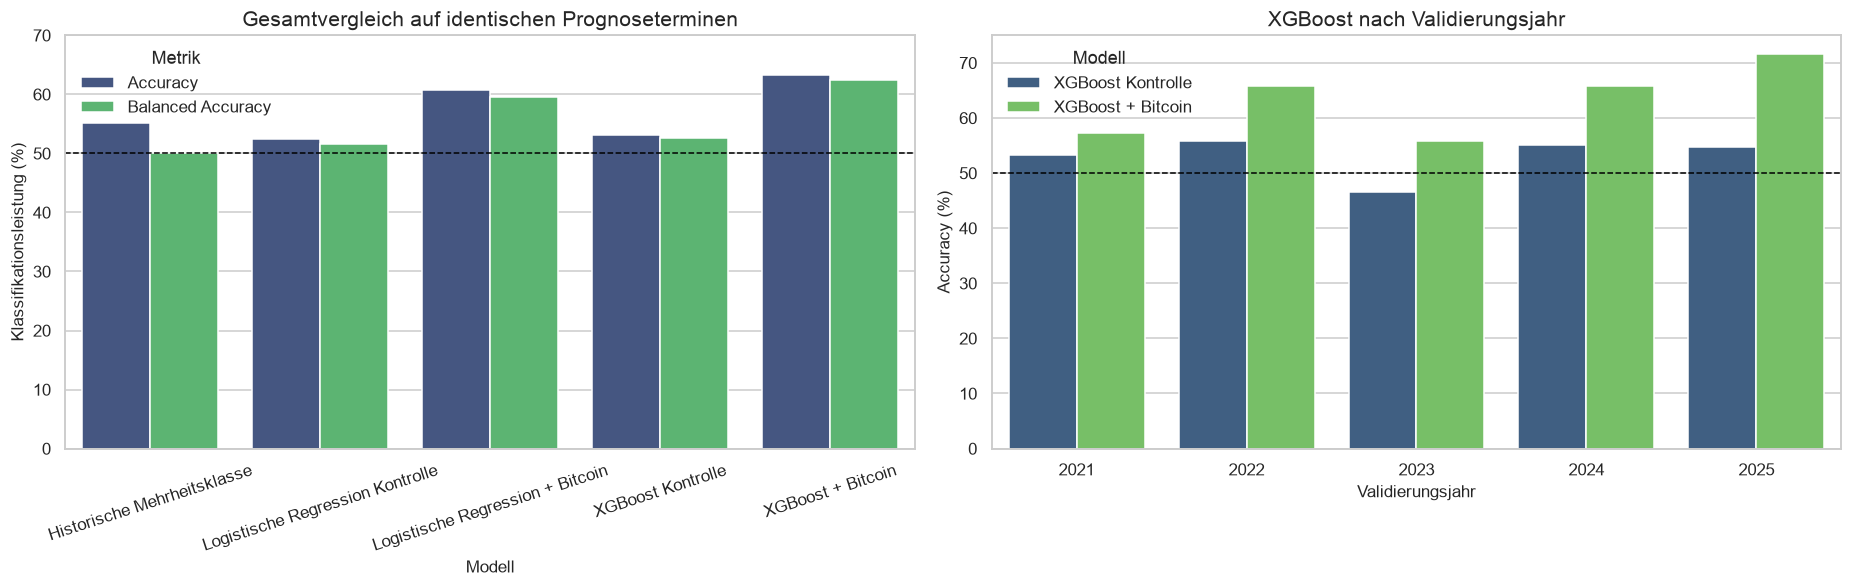

In [34]:
# Plot overall model performance and annual XGBoost stability
overall_xgboost_plot = all_overall_metrics.melt(
    id_vars="model",
    value_vars=["Accuracy", "Balanced Accuracy"],
    var_name="Metrik",
    value_name="Wert",
)
overall_xgboost_plot["Wert (%)"] = 100 * overall_xgboost_plot["Wert"]

fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))
sns.barplot(
    data=overall_xgboost_plot,
    x="model",
    y="Wert (%)",
    hue="Metrik",
    order=all_model_order,
    palette=[VIRIDIS(0.25), VIRIDIS(0.72)],
    ax=axes[0],
)
axes[0].axhline(50, color="black", linewidth=1, linestyle="--")
axes[0].set_ylim(0, 70)
axes[0].set_title("Gesamtvergleich auf identischen Prognoseterminen")
axes[0].set_xlabel("Modell")
axes[0].set_ylabel("Klassifikationsleistung (%)")
axes[0].tick_params(axis="x", rotation=18)
axes[0].legend(title="Metrik")

yearly_xgboost_plot = xgboost_year_metrics.copy()
yearly_xgboost_plot["Accuracy (%)"] = 100 * yearly_xgboost_plot["Accuracy"]
sns.barplot(
    data=yearly_xgboost_plot,
    x="Validierungsjahr",
    y="Accuracy (%)",
    hue="model",
    hue_order=["XGBoost Kontrolle", "XGBoost + Bitcoin"],
    palette=[VIRIDIS(0.30), VIRIDIS(0.78)],
    ax=axes[1],
)
axes[1].axhline(50, color="black", linewidth=1, linestyle="--")
axes[1].set_ylim(0, 75)
axes[1].set_title("XGBoost nach Validierungsjahr")
axes[1].set_xlabel("Validierungsjahr")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend(title="Modell")

fig.tight_layout()
plt.show()

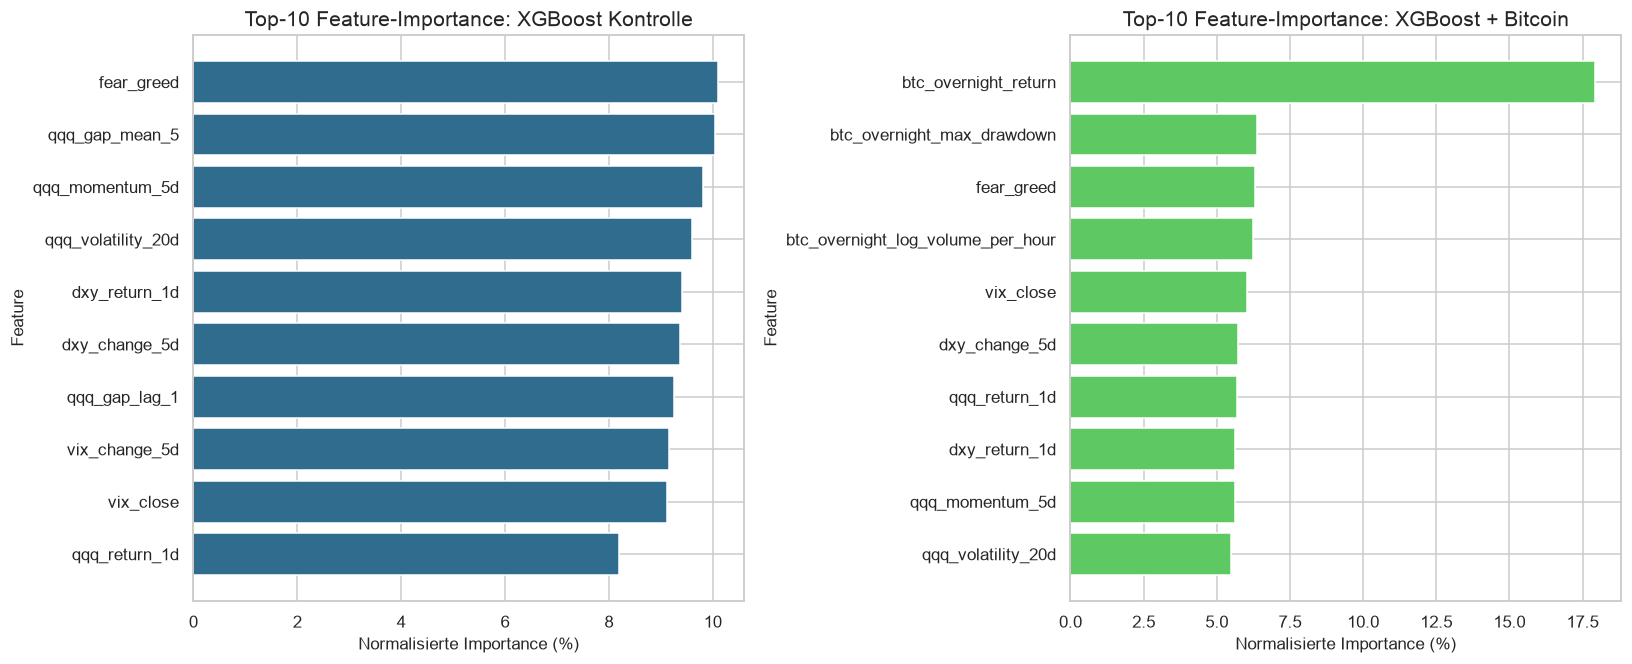

,model,Feature,Importance
24,XGBoost + Bitcoin,btc_overnight_return,0.179
28,XGBoost + Bitcoin,btc_overnight_max_drawdown,0.064
17,XGBoost + Bitcoin,fear_greed,0.063
27,XGBoost + Bitcoin,btc_overnight_log_volume_per_hour,0.062
18,XGBoost + Bitcoin,vix_close,0.060
21,XGBoost + Bitcoin,dxy_change_5d,0.057
14,XGBoost + Bitcoin,qqq_return_1d,0.057
20,XGBoost + Bitcoin,dxy_return_1d,0.056
15,XGBoost + Bitcoin,qqq_momentum_5d,0.056
16,XGBoost + Bitcoin,qqq_volatility_20d,0.055


In [35]:
# Fit one descriptive end-of-development model per feature set
development_positive_count = development_data[CLASSIFICATION_TARGET].sum()
development_negative_count = len(development_data) - development_positive_count
development_scale_pos_weight = (
    development_negative_count / development_positive_count
)

importance_rows = []
for model_name, feature_columns in XGBOOST_MODEL_FEATURES.items():
    diagnostic_model = XGBClassifier(
        **XGBOOST_PARAMETERS,
        scale_pos_weight=development_scale_pos_weight,
    )
    diagnostic_model.fit(
        development_data[feature_columns],
        development_data[CLASSIFICATION_TARGET],
    )

    # XGBoost reports normalized gain-based split importance
    for feature_name, importance in zip(
        feature_columns, diagnostic_model.feature_importances_
    ):
        importance_rows.append(
            {
                "model": model_name,
                "Feature": feature_name,
                "Importance": importance,
            }
        )

xgboost_importance = pd.DataFrame(importance_rows)
top_importance = (
    xgboost_importance.sort_values(
        ["model", "Importance"], ascending=[True, False]
    )
    .groupby("model", observed=False, sort=False)
    .head(10)
)

fig, axes = plt.subplots(1, 2, figsize=(15, 6.2))
for axis, model_name, color in zip(
    axes,
    ["XGBoost Kontrolle", "XGBoost + Bitcoin"],
    [VIRIDIS(0.35), VIRIDIS(0.75)],
):
    model_importance = top_importance[
        top_importance["model"] == model_name
    ].sort_values("Importance")
    axis.barh(
        model_importance["Feature"],
        100 * model_importance["Importance"],
        color=color,
    )
    axis.set_title(f"Top-10 Feature-Importance: {model_name}")
    axis.set_xlabel("Normalisierte Importance (%)")
    axis.set_ylabel("Feature")

fig.tight_layout()
plt.show()

display(
    xgboost_importance.sort_values(
        ["model", "Importance"], ascending=[True, False]
    )
    .groupby("model", observed=False, sort=False)
    .head(10)
    .assign(Importance=lambda frame: frame["Importance"].round(3))
)

In [36]:
# Derive the interpretation from the executed XGBoost predictions
xgboost_overall = all_overall_metrics.set_index("model")
xgb_control_accuracy = xgboost_overall.loc[
    "XGBoost Kontrolle", "Accuracy"
]
xgb_bitcoin_accuracy = xgboost_overall.loc[
    "XGBoost + Bitcoin", "Accuracy"
]
xgb_control_balanced = xgboost_overall.loc[
    "XGBoost Kontrolle", "Balanced Accuracy"
]
xgb_bitcoin_balanced = xgboost_overall.loc[
    "XGBoost + Bitcoin", "Balanced Accuracy"
]
logistic_bitcoin_accuracy = xgboost_overall.loc[
    "Logistische Regression + Bitcoin", "Accuracy"
]
logistic_bitcoin_balanced = xgboost_overall.loc[
    "Logistische Regression + Bitcoin", "Balanced Accuracy"
]
xgb_bitcoin_positive_rate = xgboost_overall.loc[
    "XGBoost + Bitcoin", "Positivrate Prognose"
]

xgboost_year_pivot = xgboost_year_metrics.pivot(
    index="Validierungsjahr", columns="model", values="Accuracy"
)
xgboost_bitcoin_year_wins = int(
    (
        xgboost_year_pivot["XGBoost + Bitcoin"]
        > xgboost_year_pivot["XGBoost Kontrolle"]
    ).sum()
)

xgboost_scope_indexed = xgboost_scope_metrics.set_index(
    ["Modell", "Teilmenge"]
)
xgb_monday_control_accuracy = xgboost_scope_indexed.loc[
    ("XGBoost Kontrolle", "Montage"), "Accuracy"
]
xgb_monday_bitcoin_accuracy = xgboost_scope_indexed.loc[
    ("XGBoost + Bitcoin", "Montage"), "Accuracy"
]
xgb_monday_bitcoin_balanced = xgboost_scope_indexed.loc[
    ("XGBoost + Bitcoin", "Montage"), "Balanced Accuracy"
]

bitcoin_feature_names = set(FULL_FEATURES) - set(CONTROL_FEATURES)
bitcoin_importance_share = xgboost_importance.loc[
    (xgboost_importance["model"] == "XGBoost + Bitcoin")
    & xgboost_importance["Feature"].isin(bitcoin_feature_names),
    "Importance",
].sum()
top_bitcoin_feature_row = (
    xgboost_importance.loc[
        (xgboost_importance["model"] == "XGBoost + Bitcoin")
        & xgboost_importance["Feature"].isin(bitcoin_feature_names)
    ]
    .sort_values("Importance", ascending=False)
    .iloc[0]
)

display(
    Markdown(
        f'''
### Interpretation

Die XGBoost-Kontrollvariante erreicht **{xgb_control_accuracy:.1%}
Accuracy** und **{xgb_control_balanced:.1%} Balanced Accuracy**. Mit den
Bitcoin-Merkmalen ergeben sich **{xgb_bitcoin_accuracy:.1%} Accuracy** und
**{xgb_bitcoin_balanced:.1%} Balanced Accuracy**. Der direkte Bitcoin-Zusatz
beträgt damit **{100 * (xgb_bitcoin_accuracy - xgb_control_accuracy):.1f}
Prozentpunkte bei Accuracy** und
**{100 * (xgb_bitcoin_balanced - xgb_control_balanced):.1f} Prozentpunkte bei
Balanced Accuracy**. Die Bitcoin-Variante prognostiziert in
**{xgb_bitcoin_positive_rate:.1%}** der Fälle positiv und erkennt beide Klassen.

Sie übertrifft die XGBoost-Kontrollvariante in
**{xgboost_bitcoin_year_wins} von {len(VALIDATION_YEARS)}
Validierungsjahren**. Gegenüber der logistischen Bitcoin-Variante verändert
sich die Accuracy um
**{100 * (xgb_bitcoin_accuracy - logistic_bitcoin_accuracy):+.1f}
Prozentpunkte** und die Balanced Accuracy um
**{100 * (xgb_bitcoin_balanced - logistic_bitcoin_balanced):+.1f}
Prozentpunkte**. Damit
prüfen wir, ob nichtlineare Bäume über den bereits beobachteten linearen
Bitcoin-Zusammenhang hinausgehen.

An Montagen verändert Bitcoin die XGBoost-Accuracy von
**{xgb_monday_control_accuracy:.1%}** auf **{xgb_monday_bitcoin_accuracy:.1%}**;
die Bitcoin-Variante erreicht **{xgb_monday_bitcoin_balanced:.1%} Balanced
Accuracy**. Im deskriptiven Endmodell entfallen zusammen
**{bitcoin_importance_share:.1%} der normalisierten Importance** auf die fünf
BTC-Merkmale; davon ist **`{top_bitcoin_feature_row['Feature']}`** am höchsten
gewichtet. Diese Importance beschreibt die Nutzung durch das Modell, nicht die
Richtung eines Effekts und keine Kausalität.

Alle Resultate stammen weiterhin ausschließlich aus der Walk-forward-
Validierung 2021 bis 2025. Der Holdout 2026 wird erst nach Abschluss der
Modellentwicklung einmalig ausgewertet.
        '''
    )
)


### Interpretation

Die XGBoost-Kontrollvariante erreicht **53.1%
Accuracy** und **52.6% Balanced Accuracy**. Mit den
Bitcoin-Merkmalen ergeben sich **63.3% Accuracy** und
**62.5% Balanced Accuracy**. Der direkte Bitcoin-Zusatz
beträgt damit **10.2
Prozentpunkte bei Accuracy** und
**9.9 Prozentpunkte bei
Balanced Accuracy**. Die Bitcoin-Variante prognostiziert in
**59.1%** der Fälle positiv und erkennt beide Klassen.

Sie übertrifft die XGBoost-Kontrollvariante in
**5 von 5
Validierungsjahren**. Gegenüber der logistischen Bitcoin-Variante verändert
sich die Accuracy um
**+2.6
Prozentpunkte** und die Balanced Accuracy um
**+2.9
Prozentpunkte**. Damit
prüfen wir, ob nichtlineare Bäume über den bereits beobachteten linearen
Bitcoin-Zusammenhang hinausgehen.

An Montagen verändert Bitcoin die XGBoost-Accuracy von
**48.1%** auf **64.1%**;
die Bitcoin-Variante erreicht **64.2% Balanced
Accuracy**. Im deskriptiven Endmodell entfallen zusammen
**40.9% der normalisierten Importance** auf die fünf
BTC-Merkmale; davon ist **`btc_overnight_return`** am höchsten
gewichtet. Diese Importance beschreibt die Nutzung durch das Modell, nicht die
Richtung eines Effekts und keine Kausalität.

Alle Resultate stammen weiterhin ausschließlich aus der Walk-forward-
Validierung 2021 bis 2025. Der Holdout 2026 wird erst nach Abschluss der
Modellentwicklung einmalig ausgewertet.
        

## 11. Chronos-2

### 11.1 Methode und Zero-shot-Walk-forward-Prognose

### Erklärung

Chronos-2 ist ein vortrainiertes Time-Series Foundation Model. Im Gegensatz
zur logistischen Regression und zu XGBoost passen wir seine Gewichte nicht an
unsere Daten an. Für jeden Validierungstag \(t\) erhält das Modell die bis
dahin bekannten numerischen QQQ-Gaps:

$$
\mathcal{H}_t = (y_1, y_2, \ldots, y_{t-1}).
$$

Chronos-2 kann zusätzlich zeitlich ausgerichtete Kovariaten berücksichtigen.
Für ein Feature \(x_j\) übergeben wir seine bekannten historischen Werte als
`past_covariates` und den am Prognose-Cutoff bekannten aktuellen Wert als
`future_covariates`:

$$
\mathcal{X}_{j,t}^{past}=(x_{j,1},\ldots,x_{j,t-1}),
\qquad
\mathcal{X}_{j,t}^{future}=(x_{j,t}).
$$

Der QQQ-Gap \(y_t\) selbst erscheint nicht in den zukünftigen Kovariaten. Wir
vergleichen drei Varianten:

1. **Chronos-2 Zero-shot:** ausschließlich die historische Gap-Zeitreihe.
2. **Chronos-2 Kontrolle:** Gap-Historie und dieselben zwölf Kontrollfeatures
   wie bei XGBoost.
3. **Chronos-2 + Bitcoin:** Kontrollfeatures plus dieselben fünf
   BTC-Overnight-Merkmale wie bei XGBoost.

Aus jeder Variante erzeugen wir Quantilprognosen. Die Medianprognose ist der
Punktschätzer und bestimmt die Richtung:

$$
\widehat{y}_t = \widehat{Q}_{0.50,t},
\qquad
\widehat{Direction}_t = \mathbb{1}(\widehat{y}_t > 0).
$$

Zusätzlich bilden \(\widehat{Q}_{0.10,t}\) und
\(\widehat{Q}_{0.90,t}\) ein zentrales 80-%-Prognoseintervall. Für die
numerische Punktprognose berichten wir:

$$
MAE = \frac{1}{N}\sum_{t=1}^{N}
\left|Gap^{\%}_t-\widehat{Gap}^{\%}_t\right|.
$$

Wir verwenden für jeden Termin die gesamte verfügbare Historie. Das Batching
beschleunigt lediglich die Berechnung; bei `cross_learning=False` werden keine
Informationen zwischen Prognoseterminen geteilt. Es findet weder Fine-Tuning
noch Hyperparametersuche statt. Auf Apple Silicon verwenden wir MPS, falls es
in PyTorch verfügbar ist, ansonsten die CPU. Wegen der kleinen Gap-Werte bleibt
die Berechnung in `float32`.

In [37]:
import gc
import time

# Suppress the optional notebook-widget warning during model imports
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="IProgress not found.*")
    from chronos import Chronos2Pipeline
    from huggingface_hub import snapshot_download
    from huggingface_hub.utils import disable_progress_bars
    from transformers.utils import logging as transformers_logging

# Keep model loading quiet and use the local Hugging Face cache when possible
disable_progress_bars()
transformers_logging.set_verbosity_error()
transformers_logging.disable_progress_bar()

try:
    chronos_model_path = snapshot_download(
        CHRONOS_MODEL_ID,
        local_files_only=True,
    )
except Exception:
    # Download only when the requested model is not available locally
    chronos_model_path = snapshot_download(CHRONOS_MODEL_ID)

CHRONOS_MODEL_FEATURES = {
    "Chronos-2 Zero-shot": [],
    "Chronos-2 Kontrolle": CONTROL_FEATURES,
    "Chronos-2 + Bitcoin": FULL_FEATURES,
}

assert torch is not None, "PyTorch is required for Chronos-2"
if DEVICE == "mps":
    torch.mps.empty_cache()
torch.set_float32_matmul_precision("high")

with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=FutureWarning)
    chronos_pipeline = Chronos2Pipeline.from_pretrained(
        chronos_model_path,
        device_map=DEVICE,
        dtype=torch.float32,
    )

chronos_device_used = str(chronos_pipeline.model.device)
chronos_model_revision = Path(chronos_model_path).name
chronos_rows = []
chronos_runtime_by_model = {}

for model_name, feature_columns in CHRONOS_MODEL_FEATURES.items():
    chronos_inputs = []
    chronos_metadata = []

    for _, validation_observation in development_data[
        development_data["target_session_date"].dt.year.isin(
            VALIDATION_YEARS
        )
    ].iterrows():
        forecast_date = validation_observation["target_session_date"]
        history = development_data[
            development_data["target_session_date"] < forecast_date
        ]

        target_history = history[NUMERIC_TARGET].to_numpy(dtype=np.float32)
        if feature_columns:
            # Align historical and cutoff-known covariates with the target
            chronos_input = {
                "target": target_history,
                "past_covariates": {
                    feature_name: history[feature_name].to_numpy(
                        dtype=np.float32
                    )
                    for feature_name in feature_columns
                },
                "future_covariates": {
                    feature_name: np.asarray(
                        [validation_observation[feature_name]],
                        dtype=np.float32,
                    )
                    for feature_name in feature_columns
                },
            }
        else:
            chronos_input = target_history

        chronos_inputs.append(chronos_input)
        chronos_metadata.append(
            {
                "model": model_name,
                "fold_year": forecast_date.year,
                "forecast_date": forecast_date,
                "context_start": history["target_session_date"].min(),
                "context_end": history["target_session_date"].max(),
                "context_size": len(history),
                "feature_count": len(feature_columns),
                "actual_gap_log_return": validation_observation[
                    NUMERIC_TARGET
                ],
                "actual_gap_percent": validation_observation[
                    "qqq_gap_percent"
                ],
                "actual": validation_observation[CLASSIFICATION_TARGET],
                "target_is_monday": validation_observation[
                    "target_is_monday"
                ],
            }
        )

    model_started_at = time.perf_counter()
    # Forecast each date independently while batching the forward passes
    quantile_tensors, median_tensors = chronos_pipeline.predict_quantiles(
        chronos_inputs,
        prediction_length=1,
        quantile_levels=CHRONOS_QUANTILES,
        batch_size=CHRONOS_BATCH_SIZE,
        cross_learning=False,
    )
    chronos_runtime_by_model[model_name] = (
        time.perf_counter() - model_started_at
    )

    for metadata, quantile_tensor, median_tensor in zip(
        chronos_metadata,
        quantile_tensors,
        median_tensors,
    ):
        # Convert one-step univariate tensors to transparent scalar forecasts
        quantiles = quantile_tensor[0, 0].detach().float().cpu().numpy()
        predicted_gap_log_return = float(
            median_tensor[0, 0].detach().float().cpu()
        )

        chronos_rows.append(
            {
                **metadata,
                "q10_gap_log_return": float(quantiles[0]),
                "q50_gap_log_return": float(quantiles[1]),
                "q90_gap_log_return": float(quantiles[2]),
                "predicted_gap_log_return": predicted_gap_log_return,
                "predicted_gap_percent": 100
                * np.expm1(predicted_gap_log_return),
                "prediction": int(predicted_gap_log_return > 0),
            }
        )

chronos_predictions = pd.DataFrame(chronos_rows).sort_values(
    ["model", "forecast_date"]
).reset_index(drop=True)
chronos_predictions["inside_80_interval"] = (
    chronos_predictions["actual_gap_log_return"]
    >= chronos_predictions["q10_gap_log_return"]
) & (
    chronos_predictions["actual_gap_log_return"]
    <= chronos_predictions["q90_gap_log_return"]
)

# Release the foundation model after inference to keep the notebook lightweight
del chronos_pipeline, quantile_tensors, median_tensors
gc.collect()
if DEVICE == "mps":
    torch.mps.empty_cache()

chronos_preview = chronos_predictions.groupby(
    "model", observed=False, sort=False
).head(2).copy()
chronos_numeric = chronos_preview.select_dtypes(include="number").columns
chronos_preview[chronos_numeric] = chronos_preview[chronos_numeric].round(4)
display(chronos_preview)

,model,fold_year,forecast_date,context_start,context_end,context_size,feature_count,actual_gap_log_return,actual_gap_percent,actual,target_is_monday,q10_gap_log_return,q50_gap_log_return,q90_gap_log_return,predicted_gap_log_return,predicted_gap_percent,prediction,inside_80_interval
0,Chronos-2 + Bitcoin,2021,2021-01-04,2018-03-05,2020-12-31,697,17,0.0044,0.4367,1,1,-0.0017,0.0013,0.0042,0.0013,0.1303,1,False
1,Chronos-2 + Bitcoin,2021,2021-01-05,2018-03-05,2021-01-04,698,17,-0.0033,-0.3297,0,0,-0.0033,-0.0001,0.0032,-0.0001,-0.0092,0,True
1248,Chronos-2 Kontrolle,2021,2021-01-04,2018-03-05,2020-12-31,697,12,0.0044,0.4367,1,1,-0.0015,0.0012,0.0038,0.0012,0.1212,1,False
1249,Chronos-2 Kontrolle,2021,2021-01-05,2018-03-05,2021-01-04,698,12,-0.0033,-0.3297,0,0,-0.0020,0.0005,0.0030,0.0005,0.0458,1,False
2496,Chronos-2 Zero-shot,2021,2021-01-04,2018-03-05,2020-12-31,697,0,0.0044,0.4367,1,1,-0.0069,0.0017,0.0098,0.0017,0.1656,1,True
2497,Chronos-2 Zero-shot,2021,2021-01-05,2018-03-05,2021-01-04,698,0,-0.0033,-0.3297,0,0,-0.0068,0.0015,0.0095,0.0015,0.1536,1,True


In [38]:
# Validate shared dates, chronology, labels and quantile ordering
expected_forecast_dates = majority_predictions["forecast_date"].tolist()
for model_name, feature_columns in CHRONOS_MODEL_FEATURES.items():
    model_predictions = chronos_predictions[
        chronos_predictions["model"] == model_name
    ]
    assert len(model_predictions) == len(majority_predictions)
    assert model_predictions["forecast_date"].tolist() == expected_forecast_dates
    assert model_predictions["actual"].tolist() == majority_predictions[
        "actual"
    ].tolist()
    assert model_predictions["feature_count"].eq(len(feature_columns)).all()
    assert (
        model_predictions["context_end"]
        < model_predictions["forecast_date"]
    ).all()

assert (chronos_predictions["forecast_date"] < HOLDOUT_START).all()
assert chronos_predictions["prediction"].isin([0, 1]).all()
assert np.isfinite(
    chronos_predictions[
        [
            "q10_gap_log_return",
            "q50_gap_log_return",
            "q90_gap_log_return",
            "predicted_gap_log_return",
        ]
    ].to_numpy()
).all()
assert (
    chronos_predictions["q10_gap_log_return"]
    <= chronos_predictions["q50_gap_log_return"]
).all()
assert (
    chronos_predictions["q50_gap_log_return"]
    <= chronos_predictions["q90_gap_log_return"]
).all()
assert np.allclose(
    chronos_predictions["q50_gap_log_return"],
    chronos_predictions["predicted_gap_log_return"],
)
assert chronos_predictions["prediction"].eq(
    (chronos_predictions["predicted_gap_log_return"] > 0).astype(int)
).all()

# Save one audit trail for all three zero-shot variants
chronos_output_path = (
    PROCESSED_DATA_DIR / "btc_overnight_qqq_chronos2_backtest.csv"
)
chronos_predictions.to_csv(chronos_output_path, index=False)

chronos_handoff = (
    chronos_predictions.groupby("model", observed=False, sort=False)
    .agg(
        Prognosen=("forecast_date", "size"),
        Erste_Prognose=("forecast_date", "min"),
        Letzte_Prognose=("forecast_date", "max"),
        Kleinster_Kontext=("context_size", "min"),
        Grösster_Kontext=("context_size", "max"),
        Features=("feature_count", "first"),
    )
    .reset_index()
)
chronos_handoff["Laufzeit (Sekunden)"] = chronos_handoff["model"].map(
    chronos_runtime_by_model
)
chronos_handoff["Gerät"] = chronos_device_used

chronos_handoff_display = chronos_handoff.copy()
chronos_handoff_display["Laufzeit (Sekunden)"] = chronos_handoff_display[
    "Laufzeit (Sekunden)"
].round(1)
display(chronos_handoff_display)
display(
    Markdown(
        f'''
### Interpretation

Jede Chronos-2-Variante erzeugt **{len(majority_predictions)} Prognosen** auf
exakt denselben Terminen wie die bisherigen Modelle. Der historische Kontext
wächst jeweils von **{chronos_predictions['context_size'].min()}** auf
**{chronos_predictions['context_size'].max()} bekannte Gaps**. Die Varianten
verwenden **0, {len(CONTROL_FEATURES)} beziehungsweise {len(FULL_FEATURES)}
Kovariaten**. Jeder Kontext endet vor seinem Prognosetag; der aktuelle
Feature-Vektor ist um 09:00 Uhr bekannt, während der QQQ-Open und damit das
Ziel unbekannt bleiben. Daten ab 2026 werden nicht verwendet.
        '''
    )
)

,model,Prognosen,Erste_Prognose,Letzte_Prognose,Kleinster_Kontext,Grösster_Kontext,Features,Laufzeit (Sekunden),Gerät
0,Chronos-2 + Bitcoin,1248,2021-01-04,2025-12-31,697,1944,17,103.5,mps:0
1,Chronos-2 Kontrolle,1248,2021-01-04,2025-12-31,697,1944,12,78.6,mps:0
2,Chronos-2 Zero-shot,1248,2021-01-04,2025-12-31,697,1944,0,5.9,mps:0



### Interpretation

Jede Chronos-2-Variante erzeugt **1248 Prognosen** auf
exakt denselben Terminen wie die bisherigen Modelle. Der historische Kontext
wächst jeweils von **697** auf
**1944 bekannte Gaps**. Die Varianten
verwenden **0, 12 beziehungsweise 17
Kovariaten**. Jeder Kontext endet vor seinem Prognosetag; der aktuelle
Feature-Vektor ist um 09:00 Uhr bekannt, während der QQQ-Open und damit das
Ziel unbekannt bleiben. Daten ab 2026 werden nicht verwendet.
        

### 11.2 Ergebnisse und gemeinsamer Modellvergleich

### Erklärung

Wir bewerten die aus dem Median abgeleitete Richtung mit Accuracy und Balanced
Accuracy. Der MAE in Gap-Prozentpunkten beurteilt zusätzlich die numerische
Punktprognose. Die empirische Abdeckung zeigt, wie häufig der tatsächliche Gap
innerhalb des vorhergesagten 10-%- bis 90-%-Intervalls liegt.

Der direkte Vergleich `Chronos-2 Kontrolle` gegen `Chronos-2 + Bitcoin`
isoliert den Bitcoin-Zusatznutzen innerhalb derselben Foundation-Model-Methode.
Die univariate Variante bleibt als einfache Zero-shot-Referenz sichtbar.

In [39]:
from sklearn.metrics import mean_absolute_error


def summarize_chronos(frame):
    # Combine classification, point forecast and interval metrics
    return pd.Series(
        {
            "Beobachtungen": len(frame),
            "Positivrate Ziel": frame["actual"].mean(),
            "Positivrate Prognose": frame["prediction"].mean(),
            "Accuracy": accuracy_score(frame["actual"], frame["prediction"]),
            "Balanced Accuracy": balanced_accuracy_score(
                frame["actual"], frame["prediction"]
            ),
            "MAE Gap (Prozentpunkte)": mean_absolute_error(
                frame["actual_gap_percent"],
                frame["predicted_gap_percent"],
            ),
            "Abdeckung 80%-Intervall": frame["inside_80_interval"].mean(),
        }
    )


chronos_overall_metrics = (
    chronos_predictions.groupby("model", observed=False, sort=False)
    .apply(summarize_chronos, include_groups=False)
    .reset_index()
)
chronos_year_metrics = (
    chronos_predictions.groupby(
        ["model", "fold_year"], observed=False, sort=False
    )
    .apply(summarize_chronos, include_groups=False)
    .reset_index()
    .rename(columns={"fold_year": "Validierungsjahr"})
)

chronos_scope_rows = []
for model_name in CHRONOS_MODEL_FEATURES:
    model_predictions = chronos_predictions[
        chronos_predictions["model"] == model_name
    ]
    for scope_name, scope_frame in [
        ("Alle Handelstage", model_predictions),
        (
            "Montage",
            model_predictions[model_predictions["target_is_monday"] == 1],
        ),
        (
            "Dienstag bis Freitag",
            model_predictions[model_predictions["target_is_monday"] == 0],
        ),
    ]:
        chronos_scope_rows.append(
            {
                "Modell": model_name,
                "Teilmenge": scope_name,
                **summarize_chronos(scope_frame).to_dict(),
            }
        )
chronos_scope_metrics = pd.DataFrame(chronos_scope_rows)

display(chronos_overall_metrics.round(3))
display(chronos_year_metrics.round(3))
display(chronos_scope_metrics.round(3))

,model,Beobachtungen,Positivrate Ziel,Positivrate Prognose,Accuracy,Balanced Accuracy,MAE Gap (Prozentpunkte),Abdeckung 80%-Intervall
0,Chronos-2 + Bitcoin,1248.0,0.551,0.774,0.562,0.535,0.586,0.401
1,Chronos-2 Kontrolle,1248.0,0.551,0.813,0.539,0.507,0.592,0.374
2,Chronos-2 Zero-shot,1248.0,0.551,0.983,0.546,0.496,0.581,0.780


,model,Validierungsjahr,Beobachtungen,Positivrate Ziel,Positivrate Prognose,Accuracy,Balanced Accuracy,MAE Gap (Prozentpunkte),Abdeckung 80%-Intervall
0,Chronos-2 + Bitcoin,2021,246.0,0.581,0.801,0.569,0.521,0.482,0.447
1,Chronos-2 + Bitcoin,2022,251.0,0.454,0.773,0.490,0.515,0.857,0.315
2,Chronos-2 + Bitcoin,2023,249.0,0.526,0.727,0.558,0.547,0.488,0.414
3,Chronos-2 + Bitcoin,2024,252.0,0.599,0.754,0.591,0.543,0.488,0.433
4,Chronos-2 + Bitcoin,2025,250.0,0.596,0.816,0.604,0.545,0.613,0.396
5,Chronos-2 Kontrolle,2021,246.0,0.581,0.911,0.565,0.498,0.481,0.398
6,Chronos-2 Kontrolle,2022,251.0,0.454,0.793,0.438,0.465,0.870,0.291
7,Chronos-2 Kontrolle,2023,249.0,0.526,0.759,0.550,0.537,0.493,0.394
8,Chronos-2 Kontrolle,2024,252.0,0.599,0.778,0.591,0.538,0.482,0.401
9,Chronos-2 Kontrolle,2025,250.0,0.596,0.828,0.552,0.489,0.629,0.388


,Modell,Teilmenge,Beobachtungen,Positivrate Ziel,Positivrate Prognose,Accuracy,Balanced Accuracy,MAE Gap (Prozentpunkte),Abdeckung 80%-Intervall
0,Chronos-2 Zero-shot,Alle Handelstage,1248.0,0.551,0.983,0.546,0.496,0.581,0.780
1,Chronos-2 Zero-shot,Montage,231.0,0.558,0.983,0.567,0.511,0.599,0.801
2,Chronos-2 Zero-shot,Dienstag bis Freitag,1017.0,0.550,0.983,0.541,0.493,0.577,0.776
3,Chronos-2 Kontrolle,Alle Handelstage,1248.0,0.551,0.813,0.539,0.507,0.592,0.374
4,Chronos-2 Kontrolle,Montage,231.0,0.558,0.801,0.541,0.506,0.606,0.377
5,Chronos-2 Kontrolle,Dienstag bis Freitag,1017.0,0.550,0.816,0.539,0.508,0.588,0.374
6,Chronos-2 + Bitcoin,Alle Handelstage,1248.0,0.551,0.774,0.562,0.535,0.586,0.401
7,Chronos-2 + Bitcoin,Montage,231.0,0.558,0.675,0.597,0.578,0.583,0.424
8,Chronos-2 + Bitcoin,Dienstag bis Freitag,1017.0,0.550,0.796,0.555,0.525,0.587,0.395


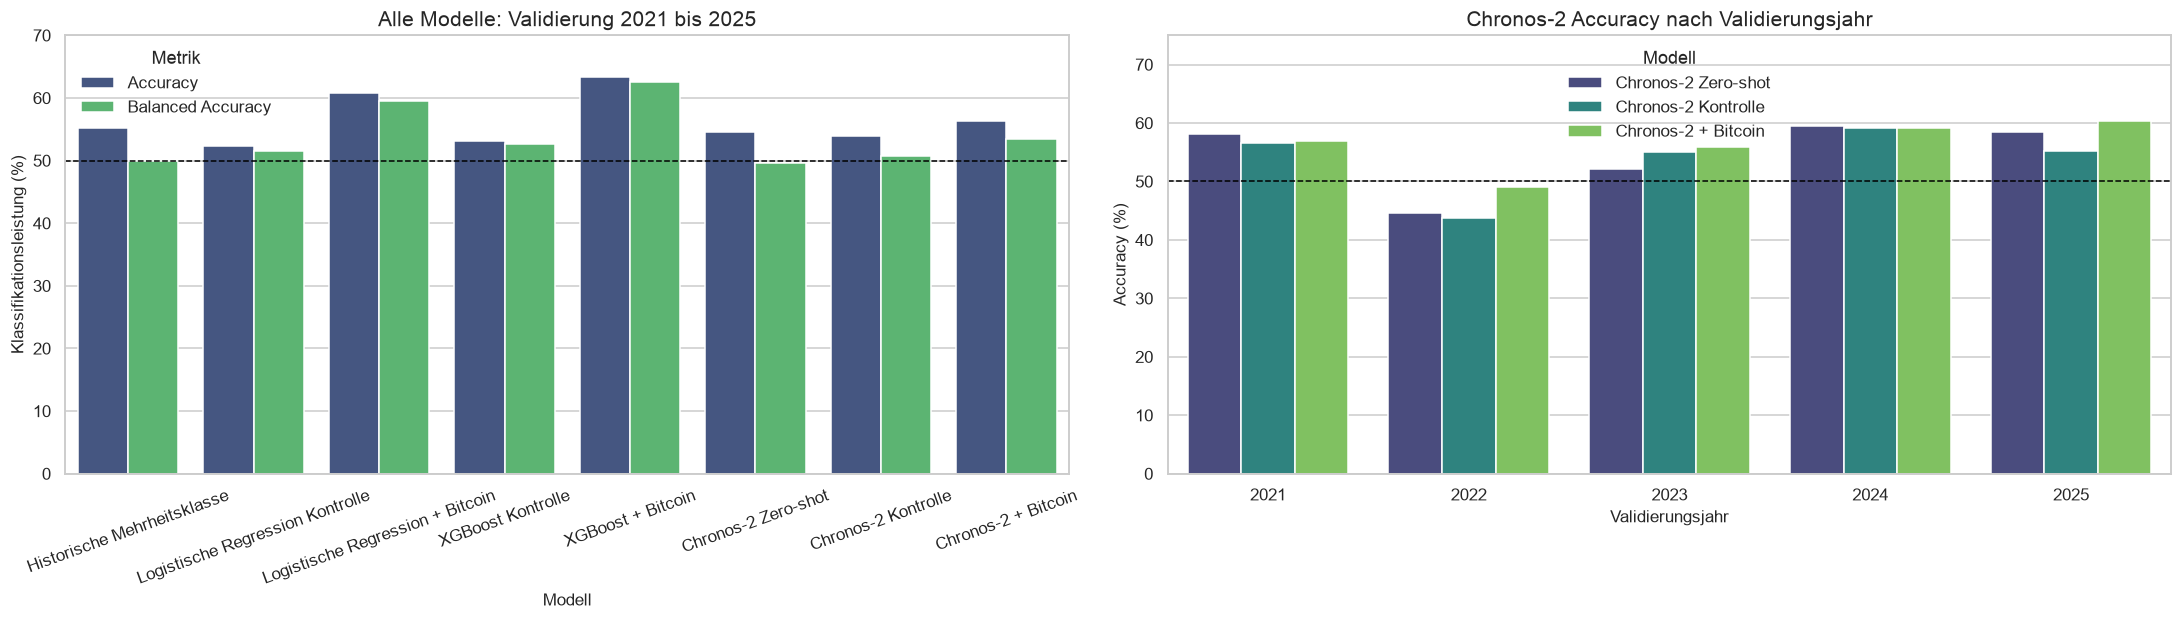

,model,Beobachtungen,Positivrate Ziel,Positivrate Prognose,Accuracy,Balanced Accuracy
0,Historische Mehrheitsklasse,1248.0,0.551,1.000,0.551,0.500
1,Logistische Regression Kontrolle,1248.0,0.551,0.585,0.524,0.515
2,Logistische Regression + Bitcoin,1248.0,0.551,0.622,0.607,0.596
3,XGBoost Kontrolle,1248.0,0.551,0.557,0.531,0.526
4,XGBoost + Bitcoin,1248.0,0.551,0.591,0.633,0.625
5,Chronos-2 Zero-shot,1248.0,0.551,0.983,0.546,0.496
6,Chronos-2 Kontrolle,1248.0,0.551,0.813,0.539,0.507
7,Chronos-2 + Bitcoin,1248.0,0.551,0.774,0.562,0.535


In [40]:
# Add all Chronos-2 variants to the shared classification comparison
chronos_classification_predictions = chronos_predictions[
    [
        "model",
        "fold_year",
        "forecast_date",
        "prediction",
        "actual",
        "target_is_monday",
    ]
]
final_development_predictions = pd.concat(
    [all_comparison_predictions, chronos_classification_predictions],
    ignore_index=True,
)
final_model_order = [
    *all_model_order,
    "Chronos-2 Zero-shot",
    "Chronos-2 Kontrolle",
    "Chronos-2 + Bitcoin",
]
final_development_metrics = (
    final_development_predictions.groupby(
        "model", observed=False, sort=False
    )
    .apply(summarize_classification, include_groups=False)
    .reindex(final_model_order)
    .reset_index()
)

final_metric_plot = final_development_metrics.melt(
    id_vars="model",
    value_vars=["Accuracy", "Balanced Accuracy"],
    var_name="Metrik",
    value_name="Wert",
)
final_metric_plot["Wert (%)"] = 100 * final_metric_plot["Wert"]

fig, axes = plt.subplots(1, 2, figsize=(20, 5.8))
sns.barplot(
    data=final_metric_plot,
    x="model",
    y="Wert (%)",
    hue="Metrik",
    order=final_model_order,
    palette=[VIRIDIS(0.25), VIRIDIS(0.72)],
    ax=axes[0],
)
axes[0].axhline(50, color="black", linewidth=1, linestyle="--")
axes[0].set_ylim(0, 70)
axes[0].set_title("Alle Modelle: Validierung 2021 bis 2025")
axes[0].set_xlabel("Modell")
axes[0].set_ylabel("Klassifikationsleistung (%)")
axes[0].tick_params(axis="x", rotation=20)
axes[0].legend(title="Metrik")

chronos_accuracy_plot = chronos_year_metrics.copy()
chronos_accuracy_plot["Accuracy (%)"] = (
    100 * chronos_accuracy_plot["Accuracy"]
)
sns.barplot(
    data=chronos_accuracy_plot,
    x="Validierungsjahr",
    y="Accuracy (%)",
    hue="model",
    hue_order=list(CHRONOS_MODEL_FEATURES),
    palette=[VIRIDIS(0.20), VIRIDIS(0.50), VIRIDIS(0.80)],
    ax=axes[1],
)
axes[1].axhline(50, color="black", linewidth=1, linestyle="--")
axes[1].set_ylim(0, 75)
axes[1].set_title("Chronos-2 Accuracy nach Validierungsjahr")
axes[1].set_xlabel("Validierungsjahr")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend(title="Modell")

fig.tight_layout()
plt.show()

display(final_development_metrics.round(3))

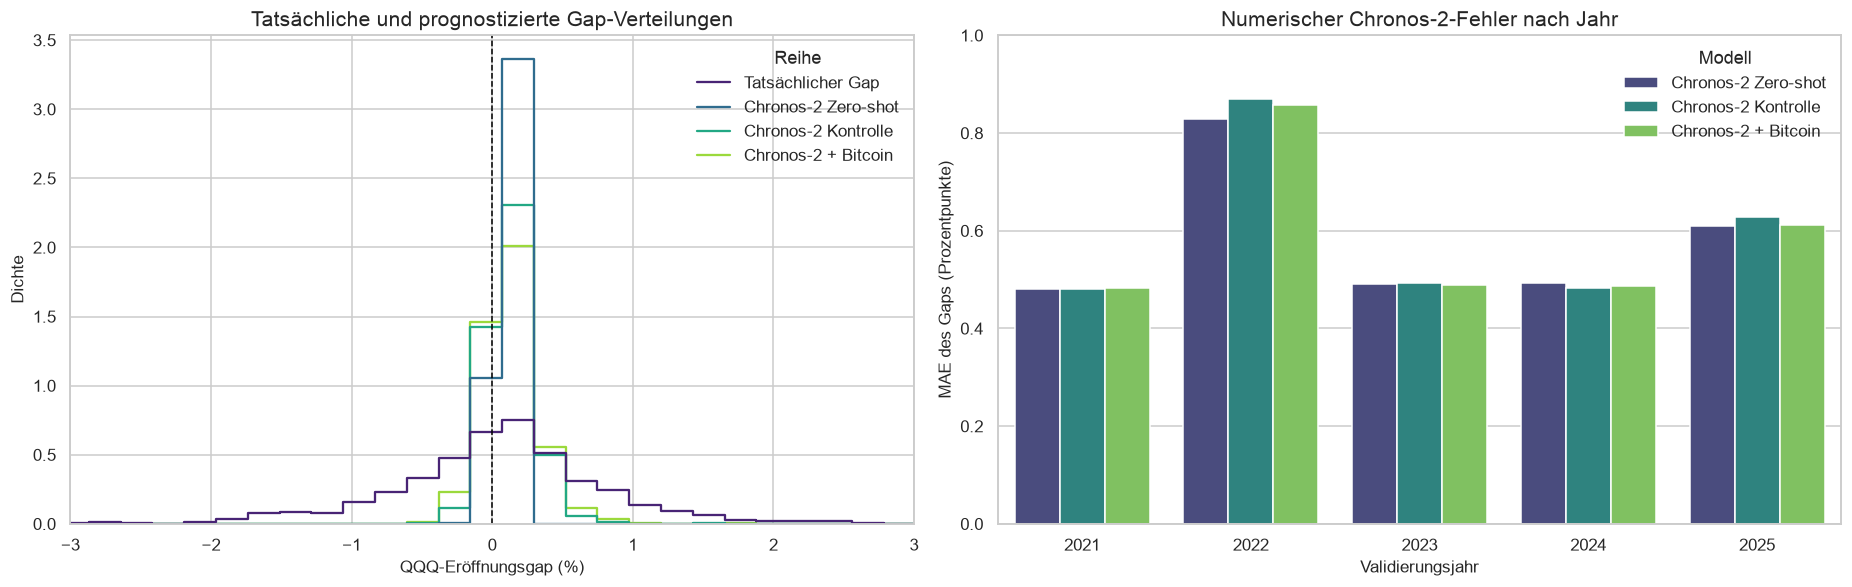

In [41]:
# Compare forecast distributions and annual numerical errors
gap_distribution_frames = [
    chronos_predictions[
        chronos_predictions["model"] == "Chronos-2 Zero-shot"
    ][["actual_gap_percent"]]
    .rename(columns={"actual_gap_percent": "Gap (%)"})
    .assign(Reihe="Tatsächlicher Gap")
]
for model_name in CHRONOS_MODEL_FEATURES:
    gap_distribution_frames.append(
        chronos_predictions[
            chronos_predictions["model"] == model_name
        ][["predicted_gap_percent"]]
        .rename(columns={"predicted_gap_percent": "Gap (%)"})
        .assign(Reihe=model_name)
    )
gap_distribution = pd.concat(gap_distribution_frames, ignore_index=True)

fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))
sns.histplot(
    data=gap_distribution,
    x="Gap (%)",
    hue="Reihe",
    hue_order=["Tatsächlicher Gap", *CHRONOS_MODEL_FEATURES.keys()],
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
    bins=45,
    palette=[
        VIRIDIS(0.10),
        VIRIDIS(0.35),
        VIRIDIS(0.60),
        VIRIDIS(0.85),
    ],
    ax=axes[0],
)
axes[0].axvline(0, color="black", linewidth=1, linestyle="--")
axes[0].set_xlim(-3, 3)
axes[0].set_title("Tatsächliche und prognostizierte Gap-Verteilungen")
axes[0].set_xlabel("QQQ-Eröffnungsgap (%)")
axes[0].set_ylabel("Dichte")

sns.barplot(
    data=chronos_year_metrics,
    x="Validierungsjahr",
    y="MAE Gap (Prozentpunkte)",
    hue="model",
    hue_order=list(CHRONOS_MODEL_FEATURES),
    palette=[VIRIDIS(0.20), VIRIDIS(0.50), VIRIDIS(0.80)],
    ax=axes[1],
)
axes[1].set_ylim(0, 1.0)
axes[1].set_title("Numerischer Chronos-2-Fehler nach Jahr")
axes[1].set_xlabel("Validierungsjahr")
axes[1].set_ylabel("MAE des Gaps (Prozentpunkte)")
axes[1].legend(title="Modell")

fig.tight_layout()
plt.show()

In [42]:
# Derive conclusions only from executed forecast-level results
chronos_overall_indexed = chronos_overall_metrics.set_index("model")
chronos_zero_accuracy = chronos_overall_indexed.loc[
    "Chronos-2 Zero-shot", "Accuracy"
]
chronos_zero_balanced = chronos_overall_indexed.loc[
    "Chronos-2 Zero-shot", "Balanced Accuracy"
]
chronos_control_accuracy = chronos_overall_indexed.loc[
    "Chronos-2 Kontrolle", "Accuracy"
]
chronos_control_balanced = chronos_overall_indexed.loc[
    "Chronos-2 Kontrolle", "Balanced Accuracy"
]
chronos_bitcoin_accuracy = chronos_overall_indexed.loc[
    "Chronos-2 + Bitcoin", "Accuracy"
]
chronos_bitcoin_balanced = chronos_overall_indexed.loc[
    "Chronos-2 + Bitcoin", "Balanced Accuracy"
]
chronos_bitcoin_positive_rate = chronos_overall_indexed.loc[
    "Chronos-2 + Bitcoin", "Positivrate Prognose"
]
chronos_zero_mae = chronos_overall_indexed.loc[
    "Chronos-2 Zero-shot", "MAE Gap (Prozentpunkte)"
]
chronos_control_mae = chronos_overall_indexed.loc[
    "Chronos-2 Kontrolle", "MAE Gap (Prozentpunkte)"
]
chronos_bitcoin_mae = chronos_overall_indexed.loc[
    "Chronos-2 + Bitcoin", "MAE Gap (Prozentpunkte)"
]
chronos_zero_coverage = chronos_overall_indexed.loc[
    "Chronos-2 Zero-shot", "Abdeckung 80%-Intervall"
]
chronos_control_coverage = chronos_overall_indexed.loc[
    "Chronos-2 Kontrolle", "Abdeckung 80%-Intervall"
]
chronos_bitcoin_coverage = chronos_overall_indexed.loc[
    "Chronos-2 + Bitcoin", "Abdeckung 80%-Intervall"
]

chronos_year_accuracy = chronos_year_metrics.pivot(
    index="Validierungsjahr", columns="model", values="Accuracy"
)
chronos_bitcoin_year_wins = int(
    (
        chronos_year_accuracy["Chronos-2 + Bitcoin"]
        > chronos_year_accuracy["Chronos-2 Kontrolle"]
    ).sum()
)
chronos_bitcoin_year_ties = int(
    np.isclose(
        chronos_year_accuracy["Chronos-2 + Bitcoin"],
        chronos_year_accuracy["Chronos-2 Kontrolle"],
    ).sum()
)

final_metrics_indexed = final_development_metrics.set_index("model")
xgboost_bitcoin_accuracy = final_metrics_indexed.loc[
    "XGBoost + Bitcoin", "Accuracy"
]
xgboost_bitcoin_balanced = final_metrics_indexed.loc[
    "XGBoost + Bitcoin", "Balanced Accuracy"
]

display(
    Markdown(
        f'''
### Interpretation

Die reine Zero-shot-Variante erreicht **{chronos_zero_accuracy:.1%} Accuracy**
und **{chronos_zero_balanced:.1%} Balanced Accuracy**. Mit den Kontrollfeatures
ergeben sich **{chronos_control_accuracy:.1%}** und
**{chronos_control_balanced:.1%}**. Nach Ergänzung der fünf Bitcoin-Merkmale
erreicht Chronos-2 **{chronos_bitcoin_accuracy:.1%} Accuracy** und
**{chronos_bitcoin_balanced:.1%} Balanced Accuracy**. Der direkte
Bitcoin-Zusatz innerhalb von Chronos-2 beträgt damit
**{100 * (chronos_bitcoin_accuracy - chronos_control_accuracy):+.1f}
Prozentpunkte bei Accuracy** und
**{100 * (chronos_bitcoin_balanced - chronos_control_balanced):+.1f}
Prozentpunkte bei Balanced Accuracy**.

Die Bitcoin-Variante übertrifft die Kontrollvariante in
**{chronos_bitcoin_year_wins} von {len(VALIDATION_YEARS)}
Validierungsjahren**; in **{chronos_bitcoin_year_ties} Jahren** sind beide
gleich. Sie prognostiziert in **{chronos_bitcoin_positive_rate:.1%}** der Fälle
positiv. Der numerische MAE verändert sich von
**{chronos_control_mae:.3f}** auf **{chronos_bitcoin_mae:.3f}
Gap-Prozentpunkte**; die univariate Referenz liegt bei
**{chronos_zero_mae:.3f}**.

Bei der Unsicherheit ist das Ergebnis schwach: Das nominelle 80-%-Intervall
deckt univariat **{chronos_zero_coverage:.1%}**, mit Kontrollfeatures nur
**{chronos_control_coverage:.1%}** und mit Bitcoin
**{chronos_bitcoin_coverage:.1%}** der tatsächlichen Gaps ab. Die
Kovariatenvarianten sind damit deutlich unterkalibriert. Ihre Quantilintervalle
sollten nicht als verlässliche Risikobänder interpretiert werden, auch wenn
Bitcoin die Richtungsleistung verbessert.

XGBoost mit Bitcoin bleibt bei **{xgboost_bitcoin_accuracy:.1%} Accuracy** und
**{xgboost_bitcoin_balanced:.1%} Balanced Accuracy** die überwachte Referenz.
Der Chronos-Vergleich beantwortet dieselbe Zusatznutzenfrage mit identischen
Features, aber ohne Fine-Tuning. Unterschiede zwischen beiden Methoden sind
daher als Modellunterschiede und nicht als unterschiedliche verfügbare
Information zu interpretieren. Der Holdout 2026 bleibt weiterhin
unangetastet.
        '''
    )
)


### Interpretation

Die reine Zero-shot-Variante erreicht **54.6% Accuracy**
und **49.6% Balanced Accuracy**. Mit den Kontrollfeatures
ergeben sich **53.9%** und
**50.7%**. Nach Ergänzung der fünf Bitcoin-Merkmale
erreicht Chronos-2 **56.2% Accuracy** und
**53.5% Balanced Accuracy**. Der direkte
Bitcoin-Zusatz innerhalb von Chronos-2 beträgt damit
**+2.3
Prozentpunkte bei Accuracy** und
**+2.8
Prozentpunkte bei Balanced Accuracy**.

Die Bitcoin-Variante übertrifft die Kontrollvariante in
**4 von 5
Validierungsjahren**; in **1 Jahren** sind beide
gleich. Sie prognostiziert in **77.4%** der Fälle
positiv. Der numerische MAE verändert sich von
**0.592** auf **0.586
Gap-Prozentpunkte**; die univariate Referenz liegt bei
**0.581**.

Bei der Unsicherheit ist das Ergebnis schwach: Das nominelle 80-%-Intervall
deckt univariat **78.0%**, mit Kontrollfeatures nur
**37.4%** und mit Bitcoin
**40.1%** der tatsächlichen Gaps ab. Die
Kovariatenvarianten sind damit deutlich unterkalibriert. Ihre Quantilintervalle
sollten nicht als verlässliche Risikobänder interpretiert werden, auch wenn
Bitcoin die Richtungsleistung verbessert.

XGBoost mit Bitcoin bleibt bei **63.3% Accuracy** und
**62.5% Balanced Accuracy** die überwachte Referenz.
Der Chronos-Vergleich beantwortet dieselbe Zusatznutzenfrage mit identischen
Features, aber ohne Fine-Tuning. Unterschiede zwischen beiden Methoden sind
daher als Modellunterschiede und nicht als unterschiedliche verfügbare
Information zu interpretieren. Der Holdout 2026 bleibt weiterhin
unangetastet.
        

## 12. Finaler Holdout 2026

### 12.1 Eingefrorene Methodik und überwachte Modelle

### Erklärung

Nach Abschluss der Modellentwicklung frieren wir Features, Modellparameter und
Entscheidungsregeln ein. Der Holdout umfasst alle im festen Datenbestand
verfügbaren QQQ-Handelstage vom 2. Januar bis 30. Juni 2026. Es handelt sich
damit um einen **partiellen 2026-Holdout**, nicht um das vollständige
Kalenderjahr.

Auf Basis der vollständig abgeschlossenen Validierung 2021 bis 2025 legen wir
**XGBoost + Bitcoin** vor der Auswertung des Holdouts als Hauptmodell fest. Es
erreichte dort unter den verglichenen Modellen die höchste Balanced Accuracy.
Alle weiteren Varianten bleiben als vorab definierte Benchmarks im finalen
Vergleich; die Holdout-Ergebnisse verändern die Modellauswahl nicht.

Wir führen genau einen sequenziellen Walk-forward-Lauf durch. Für jeden
Holdout-Tag (t) trainieren wir die überwachten Modelle ausschließlich auf
Beobachtungen mit früherem Zieltag:

$$
\mathcal{D}^{train}_t = \{(x_i,y_i): i < t\}.
$$

Nach einem Handelstag darf dessen bekannt gewordenes Ziel in die Historie des
nächsten Tages eingehen. Dieses Expanding-window-Verfahren entspricht exakt
der Validierung 2021 bis 2025. Der aktuelle QQQ-Open bleibt bei jeder Prognose
unbekannt. Wir nehmen keine Auswahl, Kalibrierung oder Parameteränderung anhand
der Holdout-Ergebnisse vor.

In [43]:
# Isolate the final partial holdout only after model development is complete
holdout_data = modeling_data[
    modeling_data["target_session_date"] >= HOLDOUT_START
].copy()
holdout_data = holdout_data.sort_values("target_session_date").reset_index(
    drop=True
)

assert not holdout_data.empty
assert holdout_data["target_session_date"].min() >= HOLDOUT_START
assert holdout_data["target_session_date"].max() < pd.Timestamp(DATA_END_DATE)
assert holdout_data["target_session_date"].is_unique

holdout_supervised_rows = []
for _, observation in holdout_data.iterrows():
    forecast_date = observation["target_session_date"]
    training_history = modeling_data[
        modeling_data["target_session_date"] < forecast_date
    ]

    # The historical majority class uses only labels already observed
    historical_positive_rate = training_history[
        CLASSIFICATION_TARGET
    ].mean()
    holdout_supervised_rows.append(
        {
            "model": "Historische Mehrheitsklasse",
            "fold_year": forecast_date.year,
            "forecast_date": forecast_date,
            "train_start": training_history["target_session_date"].min(),
            "train_end": training_history["target_session_date"].max(),
            "train_size": len(training_history),
            "train_positive_rate": historical_positive_rate,
            "positive_probability": historical_positive_rate,
            "prediction": int(historical_positive_rate >= 0.5),
            "actual": observation[CLASSIFICATION_TARGET],
            "target_is_monday": observation["target_is_monday"],
        }
    )

    for model_name, feature_columns in LOGISTIC_MODEL_FEATURES.items():
        # Refit the fixed pipeline on the expanding historical window
        classifier = make_pipeline(
            StandardScaler(),
            LogisticRegression(**LOGISTIC_PARAMETERS),
        )
        classifier.fit(
            training_history[feature_columns],
            training_history[CLASSIFICATION_TARGET],
        )
        forecast_features = (
            observation[feature_columns].to_frame().T.astype(float)
        )
        positive_probability = classifier.predict_proba(
            forecast_features
        )[0, 1]
        holdout_supervised_rows.append(
            {
                "model": model_name,
                "fold_year": forecast_date.year,
                "forecast_date": forecast_date,
                "train_start": training_history[
                    "target_session_date"
                ].min(),
                "train_end": training_history[
                    "target_session_date"
                ].max(),
                "train_size": len(training_history),
                "train_positive_rate": training_history[
                    CLASSIFICATION_TARGET
                ].mean(),
                "positive_probability": positive_probability,
                "prediction": int(positive_probability >= 0.5),
                "actual": observation[CLASSIFICATION_TARGET],
                "target_is_monday": observation["target_is_monday"],
            }
        )

    for model_name, feature_columns in XGBOOST_MODEL_FEATURES.items():
        # Preserve the fixed class weighting and XGBoost configuration
        positive_count = training_history[CLASSIFICATION_TARGET].sum()
        negative_count = len(training_history) - positive_count
        scale_pos_weight = negative_count / positive_count
        classifier = XGBClassifier(
            **XGBOOST_PARAMETERS,
            scale_pos_weight=scale_pos_weight,
        )
        classifier.fit(
            training_history[feature_columns],
            training_history[CLASSIFICATION_TARGET],
        )
        forecast_features = (
            observation[feature_columns].to_frame().T.astype(float)
        )
        positive_probability = classifier.predict_proba(
            forecast_features
        )[0, 1]
        holdout_supervised_rows.append(
            {
                "model": model_name,
                "fold_year": forecast_date.year,
                "forecast_date": forecast_date,
                "train_start": training_history[
                    "target_session_date"
                ].min(),
                "train_end": training_history[
                    "target_session_date"
                ].max(),
                "train_size": len(training_history),
                "train_positive_rate": training_history[
                    CLASSIFICATION_TARGET
                ].mean(),
                "scale_pos_weight": scale_pos_weight,
                "positive_probability": positive_probability,
                "prediction": int(positive_probability >= 0.5),
                "actual": observation[CLASSIFICATION_TARGET],
                "target_is_monday": observation["target_is_monday"],
            }
        )

holdout_supervised_predictions = pd.DataFrame(
    holdout_supervised_rows
).sort_values(["model", "forecast_date"]).reset_index(drop=True)

# Validate shared dates, labels and strict chronology for all five variants
expected_holdout_dates = holdout_data["target_session_date"].tolist()
for model_name in [
    "Historische Mehrheitsklasse",
    *LOGISTIC_MODEL_FEATURES.keys(),
    *XGBOOST_MODEL_FEATURES.keys(),
]:
    model_predictions = holdout_supervised_predictions[
        holdout_supervised_predictions["model"] == model_name
    ]
    assert len(model_predictions) == len(holdout_data)
    assert model_predictions["forecast_date"].tolist() == expected_holdout_dates
    assert model_predictions["actual"].tolist() == holdout_data[
        CLASSIFICATION_TARGET
    ].tolist()
    assert (
        model_predictions["train_end"]
        < model_predictions["forecast_date"]
    ).all()

assert holdout_supervised_predictions["positive_probability"].between(
    0, 1
).all()
assert holdout_supervised_predictions["prediction"].isin([0, 1]).all()

supervised_handoff = (
    holdout_supervised_predictions.groupby("model", sort=False)
    .agg(
        Prognosen=("forecast_date", "size"),
        Erste_Prognose=("forecast_date", "min"),
        Letzte_Prognose=("forecast_date", "max"),
        Erstes_Training=("train_size", "min"),
        Letztes_Training=("train_size", "max"),
    )
    .reset_index()
)
display(supervised_handoff)

,model,Prognosen,Erste_Prognose,Letzte_Prognose,Erstes_Training,Letztes_Training
0,Historische Mehrheitsklasse,123,2026-01-02,2026-06-30,1945,2067
1,Logistische Regression + Bitcoin,123,2026-01-02,2026-06-30,1945,2067
2,Logistische Regression Kontrolle,123,2026-01-02,2026-06-30,1945,2067
3,XGBoost + Bitcoin,123,2026-01-02,2026-06-30,1945,2067
4,XGBoost Kontrolle,123,2026-01-02,2026-06-30,1945,2067


In [44]:
# Explain the supervised holdout handoff from executed checks
holdout_start_date = holdout_data["target_session_date"].min()
holdout_end_date = holdout_data["target_session_date"].max()
holdout_mondays = int(holdout_data["target_is_monday"].sum())

display(
    Markdown(
        f'''### Interpretation

Der partielle Holdout enthält **{len(holdout_data)} Handelstage** vom
**{holdout_start_date:%d.%m.%Y}** bis **{holdout_end_date:%d.%m.%Y}**, davon
**{holdout_mondays} Montage**. Alle fünf überwachten Varianten prognostizieren
exakt dieselben Termine. Das Expanding Window wächst von
**{int(holdout_supervised_predictions['train_size'].min())}** auf
**{int(holdout_supervised_predictions['train_size'].max())} bekannte
Beobachtungen**. Jede Trainingshistorie endet strikt vor dem jeweiligen
Prognosetag.
        '''
    )
)

### Interpretation

Der partielle Holdout enthält **123 Handelstage** vom
**02.01.2026** bis **30.06.2026**, davon
**23 Montage**. Alle fünf überwachten Varianten prognostizieren
exakt dieselben Termine. Das Expanding Window wächst von
**1945** auf
**2067 bekannte
Beobachtungen**. Jede Trainingshistorie endet strikt vor dem jeweiligen
Prognosetag.
        

### 12.2 Chronos-2 auf dem Holdout

### Erklärung

Auch Chronos-2 erhält keine Sonderbehandlung für den Holdout. Wir verwenden
dieselben drei Varianten, Quantile und die natürliche Richtungsregel wie in
der Entwicklung:

$$
\widehat{Direction}_t = \mathbb{1}(\widehat{Q}_{0.50,t} > 0).
$$

Der Kontext umfasst bei jedem Termin nur frühere QQQ-Gaps. Für die beiden
Kovariatenvarianten übergeben wir die historischen Merkmale und den um 09:00
Uhr bekannten aktuellen Feature-Vektor. Es findet weiterhin weder
Fine-Tuning noch Schwellenwertoptimierung statt.

In [45]:
# Reload the frozen foundation model for the final holdout pass
if DEVICE == "mps":
    torch.mps.empty_cache()

with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=FutureWarning)
    chronos_holdout_pipeline = Chronos2Pipeline.from_pretrained(
        chronos_model_path,
        device_map=DEVICE,
        dtype=torch.float32,
    )

chronos_holdout_rows = []
chronos_holdout_runtime_by_model = {}

for model_name, feature_columns in CHRONOS_MODEL_FEATURES.items():
    chronos_holdout_inputs = []
    chronos_holdout_metadata = []

    for _, observation in holdout_data.iterrows():
        forecast_date = observation["target_session_date"]
        history = modeling_data[
            modeling_data["target_session_date"] < forecast_date
        ]
        target_history = history[NUMERIC_TARGET].to_numpy(dtype=np.float32)

        if feature_columns:
            chronos_input = {
                "target": target_history,
                "past_covariates": {
                    feature_name: history[feature_name].to_numpy(
                        dtype=np.float32
                    )
                    for feature_name in feature_columns
                },
                "future_covariates": {
                    feature_name: np.asarray(
                        [observation[feature_name]], dtype=np.float32
                    )
                    for feature_name in feature_columns
                },
            }
        else:
            chronos_input = target_history

        chronos_holdout_inputs.append(chronos_input)
        chronos_holdout_metadata.append(
            {
                "model": model_name,
                "fold_year": forecast_date.year,
                "forecast_date": forecast_date,
                "context_start": history["target_session_date"].min(),
                "context_end": history["target_session_date"].max(),
                "context_size": len(history),
                "feature_count": len(feature_columns),
                "actual_gap_log_return": observation[NUMERIC_TARGET],
                "actual_gap_percent": observation["qqq_gap_percent"],
                "actual": observation[CLASSIFICATION_TARGET],
                "target_is_monday": observation["target_is_monday"],
            }
        )

    model_started_at = time.perf_counter()
    quantile_tensors, median_tensors = (
        chronos_holdout_pipeline.predict_quantiles(
            chronos_holdout_inputs,
            prediction_length=1,
            quantile_levels=CHRONOS_QUANTILES,
            batch_size=CHRONOS_BATCH_SIZE,
            cross_learning=False,
        )
    )
    chronos_holdout_runtime_by_model[model_name] = (
        time.perf_counter() - model_started_at
    )

    for metadata, quantile_tensor, median_tensor in zip(
        chronos_holdout_metadata,
        quantile_tensors,
        median_tensors,
    ):
        quantiles = quantile_tensor[0, 0].detach().float().cpu().numpy()
        predicted_gap_log_return = float(
            median_tensor[0, 0].detach().float().cpu()
        )
        chronos_holdout_rows.append(
            {
                **metadata,
                "q10_gap_log_return": float(quantiles[0]),
                "q50_gap_log_return": float(quantiles[1]),
                "q90_gap_log_return": float(quantiles[2]),
                "predicted_gap_log_return": predicted_gap_log_return,
                "predicted_gap_percent": 100
                * np.expm1(predicted_gap_log_return),
                "prediction": int(predicted_gap_log_return > 0),
            }
        )

chronos_holdout_predictions = pd.DataFrame(
    chronos_holdout_rows
).sort_values(["model", "forecast_date"]).reset_index(drop=True)
chronos_holdout_predictions["inside_80_interval"] = (
    chronos_holdout_predictions["actual_gap_log_return"]
    >= chronos_holdout_predictions["q10_gap_log_return"]
) & (
    chronos_holdout_predictions["actual_gap_log_return"]
    <= chronos_holdout_predictions["q90_gap_log_return"]
)

# Release the second model instance after the single final inference pass
del chronos_holdout_pipeline, quantile_tensors, median_tensors
gc.collect()
if DEVICE == "mps":
    torch.mps.empty_cache()

chronos_holdout_preview = chronos_holdout_predictions.groupby(
    "model", observed=False, sort=False
).head(2).copy()
chronos_holdout_numeric = chronos_holdout_preview.select_dtypes(
    include="number"
).columns
chronos_holdout_preview[chronos_holdout_numeric] = chronos_holdout_preview[
    chronos_holdout_numeric
].round(4)
display(chronos_holdout_preview)

,model,fold_year,forecast_date,context_start,context_end,context_size,feature_count,actual_gap_log_return,actual_gap_percent,actual,target_is_monday,q10_gap_log_return,q50_gap_log_return,q90_gap_log_return,predicted_gap_log_return,predicted_gap_percent,prediction,inside_80_interval
0,Chronos-2 + Bitcoin,2026,2026-01-02,2018-03-05,2025-12-31,1945,17,0.0093,0.9360,1,0,0.0009,0.0032,0.0057,0.0032,0.3204,1,False
1,Chronos-2 + Bitcoin,2026,2026-01-05,2018-03-05,2026-01-02,1946,17,0.0101,1.0112,1,1,0.0020,0.0041,0.0065,0.0041,0.4130,1,False
123,Chronos-2 Kontrolle,2026,2026-01-02,2018-03-05,2025-12-31,1945,12,0.0093,0.9360,1,0,0.0008,0.0029,0.0052,0.0029,0.2951,1,False
124,Chronos-2 Kontrolle,2026,2026-01-05,2018-03-05,2026-01-02,1946,12,0.0101,1.0112,1,1,0.0010,0.0031,0.0053,0.0031,0.3065,1,False
246,Chronos-2 Zero-shot,2026,2026-01-02,2018-03-05,2025-12-31,1945,0,0.0093,0.9360,1,0,-0.0043,0.0009,0.0063,0.0009,0.0916,1,False
247,Chronos-2 Zero-shot,2026,2026-01-05,2018-03-05,2026-01-02,1946,0,0.0101,1.0112,1,1,-0.0051,0.0010,0.0073,0.0010,0.1021,1,False


In [46]:
# Validate Chronos chronology, quantiles and the unchanged sign rule
for model_name, feature_columns in CHRONOS_MODEL_FEATURES.items():
    model_predictions = chronos_holdout_predictions[
        chronos_holdout_predictions["model"] == model_name
    ]
    assert len(model_predictions) == len(holdout_data)
    assert model_predictions["forecast_date"].tolist() == expected_holdout_dates
    assert model_predictions["actual"].tolist() == holdout_data[
        CLASSIFICATION_TARGET
    ].tolist()
    assert model_predictions["feature_count"].eq(len(feature_columns)).all()
    assert (
        model_predictions["context_end"]
        < model_predictions["forecast_date"]
    ).all()

assert (
    chronos_holdout_predictions["q10_gap_log_return"]
    <= chronos_holdout_predictions["q50_gap_log_return"]
).all()
assert (
    chronos_holdout_predictions["q50_gap_log_return"]
    <= chronos_holdout_predictions["q90_gap_log_return"]
).all()
assert chronos_holdout_predictions["prediction"].eq(
    (chronos_holdout_predictions["predicted_gap_log_return"] > 0).astype(int)
).all()

# Save one shared forecast-level audit trail for all final model variants
holdout_classification_predictions = pd.concat(
    [
        holdout_supervised_predictions[
            [
                "model",
                "fold_year",
                "forecast_date",
                "prediction",
                "actual",
                "target_is_monday",
            ]
        ],
        chronos_holdout_predictions[
            [
                "model",
                "fold_year",
                "forecast_date",
                "prediction",
                "actual",
                "target_is_monday",
            ]
        ],
    ],
    ignore_index=True,
)
holdout_output_path = (
    PROCESSED_DATA_DIR / "btc_overnight_qqq_holdout_2026.csv"
)
holdout_classification_predictions.to_csv(holdout_output_path, index=False)

chronos_holdout_handoff = (
    chronos_holdout_predictions.groupby("model", sort=False)
    .agg(
        Prognosen=("forecast_date", "size"),
        Kleinster_Kontext=("context_size", "min"),
        Grösster_Kontext=("context_size", "max"),
        Features=("feature_count", "first"),
    )
    .reset_index()
)
chronos_holdout_handoff["Laufzeit (Sekunden)"] = (
    chronos_holdout_handoff["model"].map(
        chronos_holdout_runtime_by_model
    )
)
display(chronos_holdout_handoff.round(1))
display(
    Markdown(
        f'''### Interpretation

Jede Chronos-2-Variante erzeugt **{len(holdout_data)} Holdout-Prognosen**.
Die Varianten verwenden unverändert **0, {len(CONTROL_FEATURES)} und
{len(FULL_FEATURES)} Kovariaten**. Der historische Kontext wächst während des
Holdouts weiter, endet aber immer vor dem Prognosetag. Die Richtung stammt
ausschließlich aus dem Vorzeichen der Medianprognose.
        '''
    )
)

,model,Prognosen,Kleinster_Kontext,Grösster_Kontext,Features,Laufzeit (Sekunden)
0,Chronos-2 + Bitcoin,123,1945,2067,17,16.0
1,Chronos-2 Kontrolle,123,1945,2067,12,11.8
2,Chronos-2 Zero-shot,123,1945,2067,0,1.0


### Interpretation

Jede Chronos-2-Variante erzeugt **123 Holdout-Prognosen**.
Die Varianten verwenden unverändert **0, 12 und
17 Kovariaten**. Der historische Kontext wächst während des
Holdouts weiter, endet aber immer vor dem Prognosetag. Die Richtung stammt
ausschließlich aus dem Vorzeichen der Medianprognose.
        

### 12.3 Holdout-Ergebnisse und Schlussfolgerung

### Erklärung

Wir berichten dieselben primären Metriken wie in der Entwicklung. Accuracy
misst den Anteil korrekter Richtungen; Balanced Accuracy gewichtet positive
und negative Zielklasse gleich. Für Chronos-2 ergänzen wir erneut MAE und die
empirische Abdeckung des 80-%-Intervalls. Für das vorab festgelegte Hauptmodell
zeigt eine Confusion Matrix zusätzlich die korrekt und falsch klassifizierten
positiven und negativen Gaps:

$$
\begin{pmatrix}
TN & FP \\
FN & TP
\end{pmatrix}.
$$

Der Vergleich zwischen 2021–2025 und dem Holdout dient ausschließlich der
Beurteilung der zeitlichen Übertragbarkeit. Die Holdout-Ergebnisse werden nicht
für eine nachträgliche Modell- oder Feature-Auswahl verwendet.

In [47]:
# Summarize the final classification results on identical holdout dates
holdout_metrics = (
    holdout_classification_predictions.groupby(
        "model", observed=False, sort=False
    )
    .apply(summarize_classification, include_groups=False)
    .reindex(final_model_order)
    .reset_index()
)

holdout_scope_rows = []
for model_name in final_model_order:
    model_predictions = holdout_classification_predictions[
        holdout_classification_predictions["model"] == model_name
    ]
    for scope_name, scope_frame in [
        ("Alle Handelstage", model_predictions),
        (
            "Montage",
            model_predictions[model_predictions["target_is_monday"] == 1],
        ),
        (
            "Dienstag bis Freitag",
            model_predictions[model_predictions["target_is_monday"] == 0],
        ),
    ]:
        holdout_scope_rows.append(
            {
                "Modell": model_name,
                "Teilmenge": scope_name,
                **summarize_classification(scope_frame).to_dict(),
            }
        )
holdout_scope_metrics = pd.DataFrame(holdout_scope_rows)

chronos_holdout_metrics = (
    chronos_holdout_predictions.groupby(
        "model", observed=False, sort=False
    )
    .apply(summarize_chronos, include_groups=False)
    .reset_index()
)

development_holdout_comparison = final_development_metrics[
    ["model", "Accuracy", "Balanced Accuracy"]
].merge(
    holdout_metrics[["model", "Accuracy", "Balanced Accuracy"]],
    on="model",
    suffixes=(" Entwicklung 2021-2025", " Holdout 2026"),
    validate="one_to_one",
)

display(holdout_metrics.round(3))
display(
    holdout_scope_metrics[
        holdout_scope_metrics["Teilmenge"] != "Alle Handelstage"
    ].round(3)
)
# Add a bounded monthly stability check for the strongest model family
xgboost_month_metrics = (
    holdout_classification_predictions[
        holdout_classification_predictions["model"].isin(
            ["XGBoost Kontrolle", "XGBoost + Bitcoin"]
        )
    ]
    .assign(Monat=lambda frame: frame["forecast_date"].dt.month)
    .groupby(["Monat", "model"], observed=False, sort=True)
    .apply(summarize_classification, include_groups=False)
    .reset_index()
)
xgboost_month_balanced = xgboost_month_metrics.pivot(
    index="Monat", columns="model", values="Balanced Accuracy"
).reset_index()

display(chronos_holdout_metrics.round(3))
display(development_holdout_comparison.round(3))
display(xgboost_month_balanced.round(3))

,model,Beobachtungen,Positivrate Ziel,Positivrate Prognose,Accuracy,Balanced Accuracy
0,Historische Mehrheitsklasse,123.0,0.569,1.000,0.569,0.500
1,Logistische Regression Kontrolle,123.0,0.569,0.252,0.504,0.539
2,Logistische Regression + Bitcoin,123.0,0.569,0.610,0.667,0.654
3,XGBoost Kontrolle,123.0,0.569,0.244,0.528,0.565
4,XGBoost + Bitcoin,123.0,0.569,0.447,0.715,0.727
5,Chronos-2 Zero-shot,123.0,0.569,1.000,0.569,0.500
6,Chronos-2 Kontrolle,123.0,0.569,0.772,0.520,0.482
7,Chronos-2 + Bitcoin,123.0,0.569,0.715,0.561,0.532


,Modell,Teilmenge,Beobachtungen,Positivrate Ziel,Positivrate Prognose,Accuracy,Balanced Accuracy
1,Historische Mehrheitsklasse,Montage,23.0,0.522,1.000,0.522,0.500
2,Historische Mehrheitsklasse,Dienstag bis Freitag,100.0,0.580,1.000,0.580,0.500
4,Logistische Regression Kontrolle,Montage,23.0,0.522,0.174,0.565,0.580
5,Logistische Regression Kontrolle,Dienstag bis Freitag,100.0,0.580,0.270,0.490,0.528
7,Logistische Regression + Bitcoin,Montage,23.0,0.522,0.652,0.609,0.602
8,Logistische Regression + Bitcoin,Dienstag bis Freitag,100.0,0.580,0.600,0.680,0.668
10,XGBoost Kontrolle,Montage,23.0,0.522,0.261,0.565,0.576
11,XGBoost Kontrolle,Dienstag bis Freitag,100.0,0.580,0.240,0.520,0.563
13,XGBoost + Bitcoin,Montage,23.0,0.522,0.565,0.783,0.780
14,XGBoost + Bitcoin,Dienstag bis Freitag,100.0,0.580,0.420,0.700,0.718


,model,Beobachtungen,Positivrate Ziel,Positivrate Prognose,Accuracy,Balanced Accuracy,MAE Gap (Prozentpunkte),Abdeckung 80%-Intervall
0,Chronos-2 + Bitcoin,123.0,0.569,0.715,0.561,0.532,0.654,0.325
1,Chronos-2 Kontrolle,123.0,0.569,0.772,0.520,0.482,0.676,0.293
2,Chronos-2 Zero-shot,123.0,0.569,1.000,0.569,0.500,0.650,0.764


,model,Accuracy Entwicklung 2021-2025,Balanced Accuracy Entwicklung 2021-2025,Accuracy Holdout 2026,Balanced Accuracy Holdout 2026
0,Historische Mehrheitsklasse,0.551,0.500,0.569,0.500
1,Logistische Regression Kontrolle,0.524,0.515,0.504,0.539
2,Logistische Regression + Bitcoin,0.607,0.596,0.667,0.654
3,XGBoost Kontrolle,0.531,0.526,0.528,0.565
4,XGBoost + Bitcoin,0.633,0.625,0.715,0.727
5,Chronos-2 Zero-shot,0.546,0.496,0.569,0.500
6,Chronos-2 Kontrolle,0.539,0.507,0.520,0.482
7,Chronos-2 + Bitcoin,0.562,0.535,0.561,0.532


model,Monat,XGBoost + Bitcoin,XGBoost Kontrolle
0,1,0.562,0.688
1,2,0.705,0.625
2,3,0.725,0.642
3,4,0.923,0.577
4,5,0.571,0.369
5,6,0.808,0.553


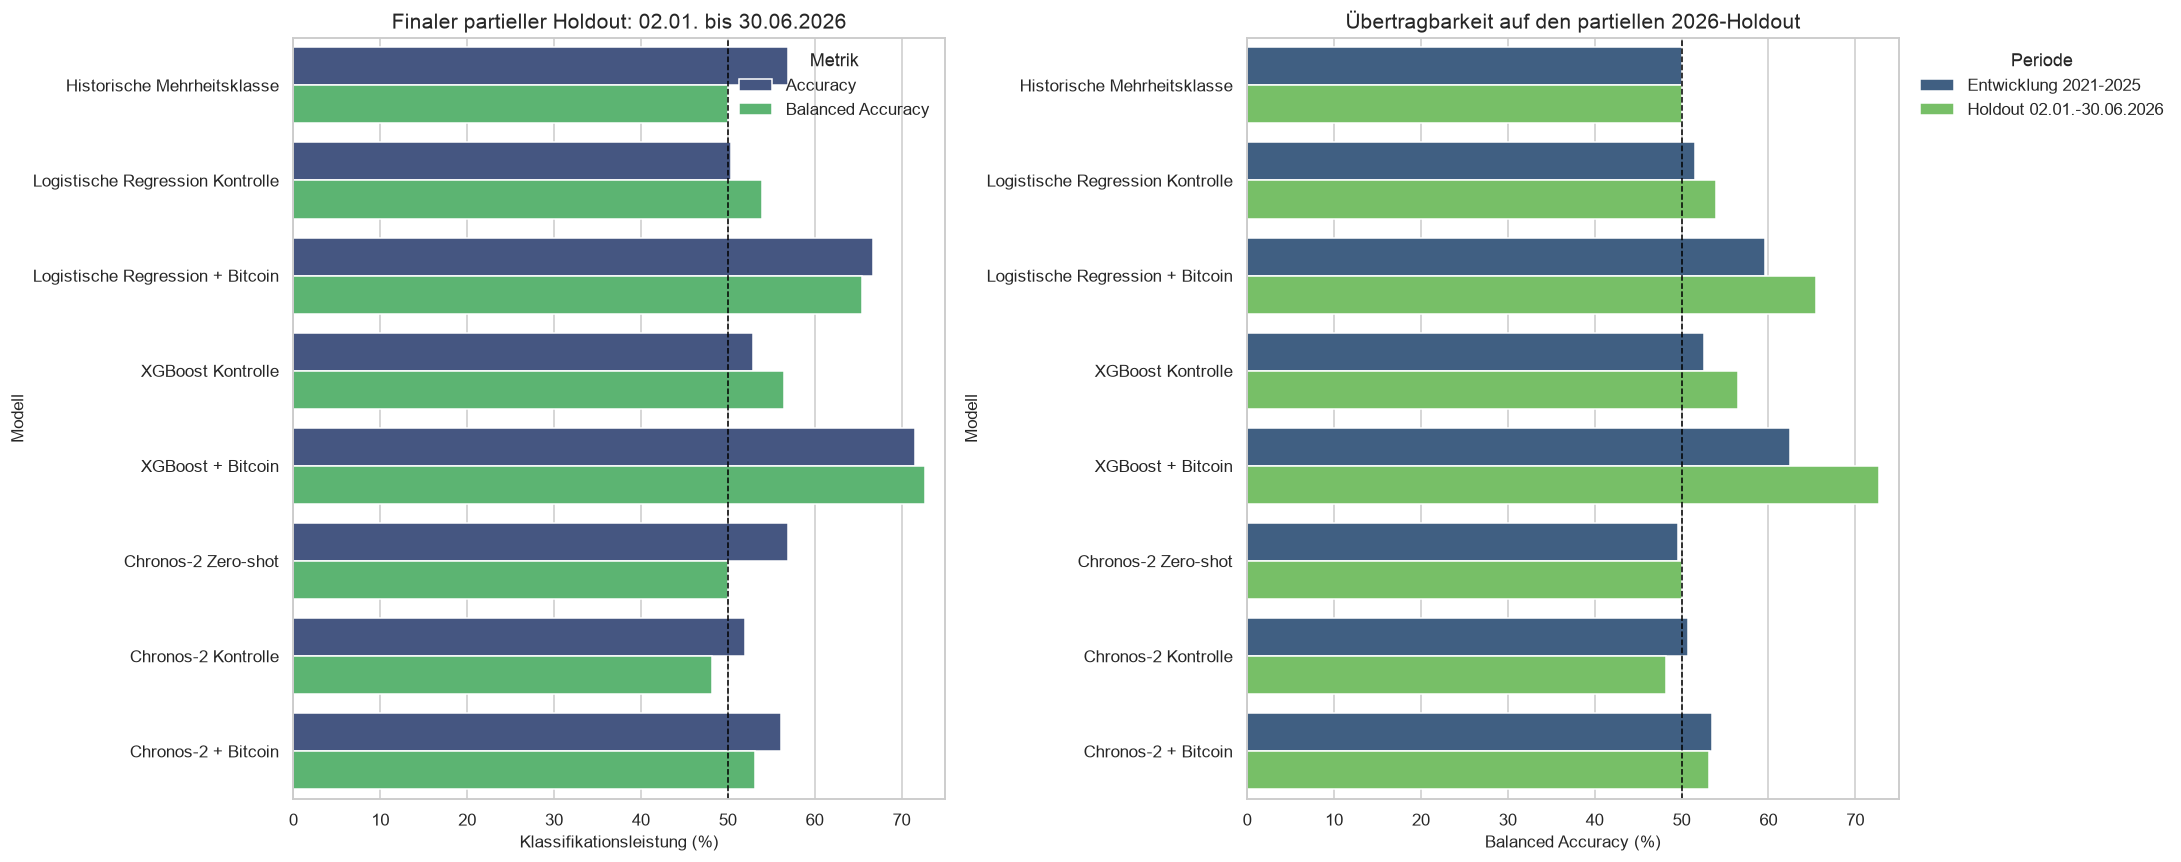

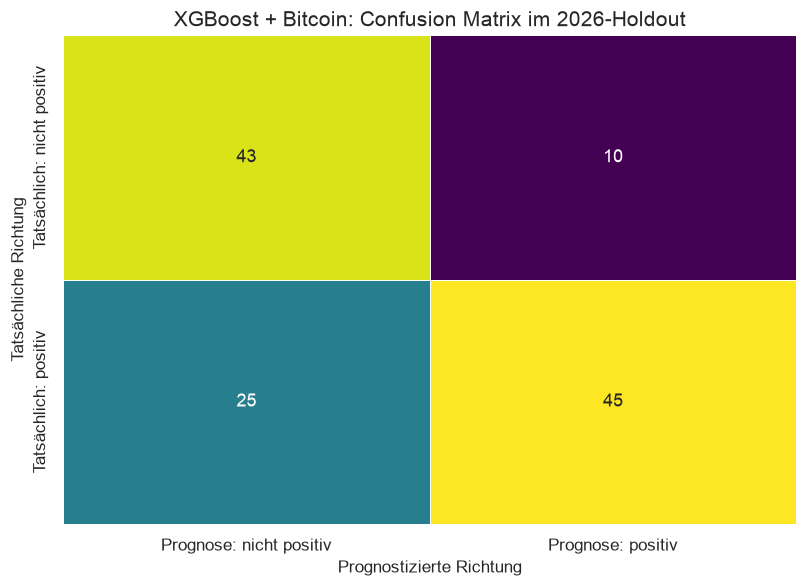

In [48]:
# Plot final performance and temporal transfer on common scales
holdout_metric_plot = holdout_metrics.melt(
    id_vars="model",
    value_vars=["Accuracy", "Balanced Accuracy"],
    var_name="Metrik",
    value_name="Wert",
)
holdout_metric_plot["Wert (%)"] = 100 * holdout_metric_plot["Wert"]

balanced_transfer_plot = development_holdout_comparison.melt(
    id_vars="model",
    value_vars=[
        "Balanced Accuracy Entwicklung 2021-2025",
        "Balanced Accuracy Holdout 2026",
    ],
    var_name="Periode",
    value_name="Balanced Accuracy",
)
balanced_transfer_plot["Periode"] = balanced_transfer_plot[
    "Periode"
].replace(
    {
        "Balanced Accuracy Entwicklung 2021-2025": "Entwicklung 2021-2025",
        "Balanced Accuracy Holdout 2026": "Holdout 02.01.-30.06.2026",
    }
)
balanced_transfer_plot["Balanced Accuracy (%)"] = (
    100 * balanced_transfer_plot["Balanced Accuracy"]
)

fig, axes = plt.subplots(1, 2, figsize=(20, 8))
sns.barplot(
    data=holdout_metric_plot,
    y="model",
    x="Wert (%)",
    hue="Metrik",
    order=final_model_order,
    palette=[VIRIDIS(0.25), VIRIDIS(0.72)],
    ax=axes[0],
)
axes[0].axvline(50, color="black", linewidth=1, linestyle="--")
axes[0].set_xlim(0, 75)
axes[0].set_title("Finaler partieller Holdout: 02.01. bis 30.06.2026")
axes[0].set_xlabel("Klassifikationsleistung (%)")
axes[0].set_ylabel("Modell")
axes[0].legend(title="Metrik")

sns.barplot(
    data=balanced_transfer_plot,
    y="model",
    x="Balanced Accuracy (%)",
    hue="Periode",
    order=final_model_order,
    palette=[VIRIDIS(0.30), VIRIDIS(0.78)],
    ax=axes[1],
)
axes[1].axvline(50, color="black", linewidth=1, linestyle="--")
axes[1].set_xlim(0, 75)
axes[1].set_title("Übertragbarkeit auf den partiellen 2026-Holdout")
axes[1].set_xlabel("Balanced Accuracy (%)")
axes[1].set_ylabel("Modell")
axes[1].legend(
    title="Periode",
    loc="upper left",
    bbox_to_anchor=(1.01, 1.0),
)

fig.tight_layout()
plt.show()

# Show the four outcomes for the preselected final model
from sklearn.metrics import confusion_matrix

final_model_holdout = holdout_classification_predictions[
    holdout_classification_predictions["model"] == "XGBoost + Bitcoin"
]
final_confusion_matrix = confusion_matrix(
    final_model_holdout["actual"],
    final_model_holdout["prediction"],
    labels=[0, 1],
)
true_negative, false_positive, false_negative, true_positive = (
    final_confusion_matrix.ravel()
)
final_confusion_display = pd.DataFrame(
    final_confusion_matrix,
    index=["Tatsächlich: nicht positiv", "Tatsächlich: positiv"],
    columns=["Prognose: nicht positiv", "Prognose: positiv"],
)

plt.figure(figsize=(7.5, 5.5))
sns.heatmap(
    final_confusion_display,
    annot=True,
    fmt="d",
    cmap="viridis",
    cbar=False,
    linewidths=0.5,
)
plt.title("XGBoost + Bitcoin: Confusion Matrix im 2026-Holdout")
plt.xlabel("Prognostizierte Richtung")
plt.ylabel("Tatsächliche Richtung")
plt.tight_layout()
plt.show()


In [49]:
# Derive the final narrative only from the executed holdout results
holdout_indexed = holdout_metrics.set_index("model")
holdout_winner = holdout_indexed["Balanced Accuracy"].idxmax()
holdout_winner_balanced = holdout_indexed.loc[
    holdout_winner, "Balanced Accuracy"
]
holdout_winner_accuracy = holdout_indexed.loc[holdout_winner, "Accuracy"]
holdout_target_positive_rate = holdout_data[CLASSIFICATION_TARGET].mean()

logistic_holdout_lift = (
    holdout_indexed.loc[
        "Logistische Regression + Bitcoin", "Balanced Accuracy"
    ]
    - holdout_indexed.loc[
        "Logistische Regression Kontrolle", "Balanced Accuracy"
    ]
)
xgboost_holdout_lift = (
    holdout_indexed.loc["XGBoost + Bitcoin", "Balanced Accuracy"]
    - holdout_indexed.loc["XGBoost Kontrolle", "Balanced Accuracy"]
)
chronos_holdout_lift = (
    holdout_indexed.loc["Chronos-2 + Bitcoin", "Balanced Accuracy"]
    - holdout_indexed.loc["Chronos-2 Kontrolle", "Balanced Accuracy"]
)

xgboost_development_balanced = final_metrics_indexed.loc[
    "XGBoost + Bitcoin", "Balanced Accuracy"
]
xgboost_holdout_accuracy = holdout_indexed.loc[
    "XGBoost + Bitcoin", "Accuracy"
]
xgboost_holdout_balanced = holdout_indexed.loc[
    "XGBoost + Bitcoin", "Balanced Accuracy"
]
xgboost_bitcoin_month_wins = int(
    (
        xgboost_month_balanced["XGBoost + Bitcoin"]
        > xgboost_month_balanced["XGBoost Kontrolle"]
    ).sum()
)

display(
    Markdown(
        f'''### Interpretation

Der partielle 2026-Holdout enthält **{len(holdout_data)} Beobachtungen** und
eine tatsächliche Positivrate von **{holdout_target_positive_rate:.1%}**. Die
höchste Balanced Accuracy erreicht **{holdout_winner}** mit
**{holdout_winner_balanced:.1%}**; seine Accuracy beträgt
**{holdout_winner_accuracy:.1%}**.

Das bereits vor dem Holdout festgelegte Hauptmodell
**XGBoost + Bitcoin** erzielt **{xgboost_holdout_accuracy:.1%} Accuracy** und
**{xgboost_holdout_balanced:.1%} Balanced Accuracy**, gegenüber
**{xgboost_development_balanced:.1%} Balanced Accuracy** in der Validierung
2021 bis 2025. Der Bitcoin-Zusatz verändert die Holdout-Balanced-Accuracy
innerhalb der logistischen Regression um
**{100 * logistic_holdout_lift:+.1f} Prozentpunkte**, innerhalb von XGBoost um
**{100 * xgboost_holdout_lift:+.1f} Prozentpunkte** und innerhalb von
Chronos-2 um **{100 * chronos_holdout_lift:+.1f} Prozentpunkte**.
XGBoost mit Bitcoin übertrifft seine Kontrollvariante in
**{xgboost_bitcoin_month_wins} von 6 Kalendermonaten**. Diese Monatswerte
umfassen jeweils nur 19 bis 22 Beobachtungen und dienen daher ausschließlich
als einfache Stabilitätskontrolle. Die Confusion Matrix enthält
**{true_negative} korrekt negative** und **{true_positive} korrekt positive**
Prognosen sowie **{false_positive} falsch positive** und
**{false_negative} falsch negative** Fälle. Das tägliche Neutraining verwendet
dabei jeweils nur Ziele, die vor dem aktuellen Prognosetag bereits bekannt
sind.

Damit beurteilen wir die ursprüngliche Hypothese auf einem zeitlich späteren,
vollständig getrennten Zeitraum. Unterschiede zwischen Entwicklung und
Holdout zeigen zeitliche Instabilität und dürfen nicht durch nachträgliches
Tuning geglättet werden. Wegen des halben Jahres mit nur
**{holdout_mondays} Montagen** sind insbesondere Wochentagsresultate
deskriptiv. Die Auswertung belegt eine Prognosebeziehung, aber weder
Kausalität noch die Profitabilität einer Handelsstrategie.
        '''
    )
)

### Interpretation

Der partielle 2026-Holdout enthält **123 Beobachtungen** und
eine tatsächliche Positivrate von **56.9%**. Die
höchste Balanced Accuracy erreicht **XGBoost + Bitcoin** mit
**72.7%**; seine Accuracy beträgt
**71.5%**.

Das bereits vor dem Holdout festgelegte Hauptmodell
**XGBoost + Bitcoin** erzielt **71.5% Accuracy** und
**72.7% Balanced Accuracy**, gegenüber
**62.5% Balanced Accuracy** in der Validierung
2021 bis 2025. Der Bitcoin-Zusatz verändert die Holdout-Balanced-Accuracy
innerhalb der logistischen Regression um
**+11.5 Prozentpunkte**, innerhalb von XGBoost um
**+16.2 Prozentpunkte** und innerhalb von
Chronos-2 um **+4.9 Prozentpunkte**.
XGBoost mit Bitcoin übertrifft seine Kontrollvariante in
**5 von 6 Kalendermonaten**. Diese Monatswerte
umfassen jeweils nur 19 bis 22 Beobachtungen und dienen daher ausschließlich
als einfache Stabilitätskontrolle. Die Confusion Matrix enthält
**43 korrekt negative** und **45 korrekt positive**
Prognosen sowie **10 falsch positive** und
**25 falsch negative** Fälle. Das tägliche Neutraining verwendet
dabei jeweils nur Ziele, die vor dem aktuellen Prognosetag bereits bekannt
sind.

Damit beurteilen wir die ursprüngliche Hypothese auf einem zeitlich späteren,
vollständig getrennten Zeitraum. Unterschiede zwischen Entwicklung und
Holdout zeigen zeitliche Instabilität und dürfen nicht durch nachträgliches
Tuning geglättet werden. Wegen des halben Jahres mit nur
**23 Montagen** sind insbesondere Wochentagsresultate
deskriptiv. Die Auswertung belegt eine Prognosebeziehung, aber weder
Kausalität noch die Profitabilität einer Handelsstrategie.
        